# QUADRA em reais: rentabilidade, risco e retorno das culturas do protótipo no Nordeste

**A pergunta.** O protótipo QUADRA monta, para cada lugar, um cardápio de 15 culturas e um plano de faixas para
2027–2029. Este notebook pergunta **quanto isso vale em dinheiro**: quanto cada cultura rende por hectare, quanto
custa, com que chance não paga o custo, como se comporta num El Niño forte, quanto a carteira e a rotação protegem
a renda e o que sobra para uma família de 3 ha em Quixadá-CE.

**Unidades.** Tudo em **R$ de 2025** (IPCA do Banco Central, média anual). A receita aparece **por hectare plantado**
(inclui a área perdida: é o que a família arrisca) e **por hectare colhido** (é o que o PAM costuma mostrar). Quando
as culturas têm ciclos diferentes, a receita aparece também **por hectare-mês** de ocupação da terra.

| Seção | Pergunta | Base principal |
|---|---|---|
| 1 | O painel: o que entra e como foi limpo | IBGE PAM (SIDRA 1612), IPCA (BCB SGS 433) |
| 2 | Quanto cada cultura produz por hectare, e com que chance de perda | PAM municipal, 1998–2025 |
| 3 | Que preço a família recebe, e quanto ele varia | preço implícito do PAM; FAOSTAT; Pink Sheet |
| 4 | Quanto entra por hectare (plantado, colhido e por mês de terra) | PAM, 2010–2025 |
| 5 | Quanto custa, quanto sobra e onde fica o ponto de equilíbrio | CONAB, custos de produção (NE) |
| 6 | Risco e retorno: pior ano em 10, El Niño forte, seca de 2012–2016 | PAM a preço de referência |
| 7 | Diversificação: correlação e carteiras em R$/ha | PAM; a carteira da proposta, refeita em reais |
| 8 | Rotação em reais: o bônus da leguminosa e o cenário honesto | catálogo de rotações |
| 9 | Cardápio do protótipo × dinheiro, município a município | ZARC + GAEZ do NE (motor) |
| 10 | A família de Quixadá: fluxo de caixa 2027–2029 | tudo acima |
| 11 | Síntese: o que paga, o que protege, o que falta medir | — |

**O que é medido e o que é suposição.**
- **Medido:** área, produção e valor da produção por município e ano (IBGE PAM); inflação (IPCA); custo de produção
  estimado pela CONAB em municípios do Nordeste (planilhas oficiais); preços ao produtor do Brasil (FAOSTAT) e
  preços mundiais (Banco Mundial).
- **Do motor do protótipo:** a situação de cada cultura em cada município (ZARC 2026/27 e GAEZ v4; onde a cultura
  tem ZARC no município, o ZARC decide; senão, aptidão GAEZ > 40 com insumo baixo, classe "média" ou melhor).
- **Da literatura, com grau:** o bônus da leguminosa antes do cereal (+24%, faixa +2% a +49%, B·T1) e o ganho contra
  o consórcio de hoje (0 a +9%, D·T3), do catálogo de rotações.
- **Suposição (sempre marcada e com faixa):** os ciclos das culturas sem fonte, o custo das culturas sem planilha da
  CONAB no Nordeste, o tamanho das faixas da família e o valor de uso da forragem. Onde o custo é suposição, o
  notebook mostra o **ponto de equilíbrio**, que não depende de saber o custo.

**Três avisos que valem para tudo.**
1. O PAM é **municipal**: mistura sequeiro e irrigado, roça e empresa, consórcio e solteiro.
2. O PAM **não separa feijão-caupi de feijão comum**: "Feijão" aqui é "Feijão (em grão)".
3. O preço é **implícito** (valor ÷ quantidade). É o preço médio que o IBGE atribui à produção do município, não o
   preço de uma venda.

Paleta: culturas em ordem e cor fixas; magnitude em um só tom (azul, do claro ao escuro); sinal (lucro ou prejuízo,
acima ou abaixo) em azul ↔ vermelho com o meio cinza. Nenhum gráfico tem dois eixos y.

In [1]:
import json
import sys
import warnings

sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\scripts")
warnings.filterwarnings("ignore")
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch

from comum import DADOS, DERIV

PROJ = Path(r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa")
F = DADOS / "financeiro"
# paleta (referência das orientações de visualização; validada: 8 cores passam CVD e visão normal)
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#d03b3b", "#ec8a7d", "#f0efec", "#6da7ec", "#184f95"])  # vermelho = prejuízo
CINZA = "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.grid": True,
                     "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.edgecolor": "#c3c2b7", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "text.color": "#0b0b0b", "axes.prop_cycle": plt.cycler(color=CAT), "lines.linewidth": 2})
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."))

# culturas do PAM em ordem fixa (a cor segue a cultura em todo o notebook)
CULT = ["Milho", "Feijão", "Mandioca", "Sorgo", "Amendoim", "Algodão herbáceo", "Mamona", "Girassol"]
COR = dict(zip(CULT, CAT))
NO_CARDAPIO = {"Milho": "Milho", "Feijão": "Feijão-caupi e feijão comum (juntos no PAM)", "Mandioca": "Mandioca",
               "Sorgo": "Sorgo granífero (o PAM é só sorgo em grão)", "Amendoim": "Amendoim", "Algodão herbáceo": "Algodão herbáceo",
               "Mamona": "Mamona", "Girassol": "Girassol"}
SEM_PAM = ["Guandu", "Sorgo forrageiro", "Milheto", "Palma forrageira", "Gliricídia", "Mucuna-preta"]
UFS = ["MA", "PI", "CE", "RN", "PB", "PE", "AL", "SE", "BA"]
AREA_MIN = 10          # ha plantados: abaixo disso, o município-ano não entra (ruído de arredondamento)
ANOS_MIN = 10          # anos válidos para um município ter "série" de uma cultura
PRECO_REF = range(2016, 2026)  # janela do preço de referência
QUIXADA = "2311306"

EVT = pd.read_csv(DADOS / "el_nino_2026" / "eventos.csv", index_col=0)
EN_FORTE = sorted(int(a) for a in EVT[(EVT.ONI_OND_NDJ >= 1.5) & EVT.quadra_afetada.between(1998, 2025)].quadra_afetada)
SECA = list(range(2012, 2017))

# ciclo de cada cultura em dias (central, mínimo, máximo) para a receita por hectare-mês
CICLO = pd.DataFrame([
    ("Feijão", 70, 60, 75, "parâmetro: caupi precoce 60–70 d (proposta v3, S2) e ~70–75 d (pedido); feijão comum é mais longo"),
    ("Milho", 110, 100, 120, "parâmetro: ~110 d (pedido); faixa suposta"),
    ("Sorgo", 110, 100, 120, "suposição (parâmetro), sem fonte lida"),
    ("Amendoim", 100, 90, 120, "suposição (parâmetro), sem fonte lida"),
    ("Algodão herbáceo", 140, 120, 160, "suposição (parâmetro), sem fonte lida"),
    ("Mamona", 180, 150, 240, "suposição (parâmetro), sem fonte lida"),
    ("Girassol", 100, 90, 120, "suposição (parâmetro), sem fonte lida"),
    ("Mandioca", 456, 365, 548, "12–18 meses (pedido); a CONAB usa '2º ciclo (18 meses)' na planilha da mandioca"),
], columns=["cultura", "dias", "dias_min", "dias_max", "fonte"]).set_index("cultura")


def descreve(df):
    """Estatística descritiva com ausentes, percentis e assimetria."""
    df = df.to_frame() if isinstance(df, pd.Series) else df
    d = df.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
    d.insert(1, "ausentes_%", (df.isna().mean() * 100).round(1))
    d["assimetria"] = df.skew(numeric_only=True)
    return d.rename(columns={"count": "n", "mean": "média", "std": "dp", "50%": "mediana"}).round(2)


def brl(v, casas=0):
    """1234.5 -> 'R$ 1.234'."""
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "—"
    return "R$ " + f"{v:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def num(v, casas=2):
    return f"{v:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")


# malhas do NE (IBGE), simplificadas para desenhar rápido
MUN_NE = gpd.read_file(DADOS / "ibge_nordeste" / "malha_ne_municipio.geojson")
MUN_NE["cod"] = MUN_NE.codarea.astype(str)
MUN_NE["geometry"] = MUN_NE.geometry.simplify(0.01)
UF_NE = gpd.read_file(DADOS / "ibge_nordeste" / "malha_ne_UF.geojson")
REFM = pd.read_parquet(DERIV / "ibge_ne_municipios_referencia.parquet").set_index("cod_mun")
NOME = REFM.municipio.to_dict()


def mapa_ne(ax, valores, titulo, cmap=SEQ, vmin=None, vmax=None, rotulo="", cores=None, ordem=None):
    """Mapa dos 1.794 municípios do NE. valores = Series indexada pelo código IBGE (texto).
    Com `cores` (dict categoria -> cor), desenha categorias em cor fixa e legenda na ordem `ordem`."""
    g = MUN_NE.assign(v=MUN_NE.cod.map(valores))
    base = g[g.v.isna()]
    base.plot(ax=ax, color="#eeebe3", edgecolor="#fcfcfb", linewidth=0.1)
    if cores:
        alca = []
        for k in (ordem or list(cores)):
            s = g[g.v == k]
            if len(s):
                s.plot(ax=ax, color=cores[k], edgecolor="#fcfcfb", linewidth=0.1)
                alca.append(Patch(color=cores[k], label=f"{k} ({len(s)})"))
        alca.append(Patch(color="#eeebe3", label=f"sem dado ({len(base)})"))
        ax.legend(handles=alca, fontsize=7, loc="lower right", bbox_to_anchor=(1.02, 0.0), ncol=1, frameon=False)
    else:
        g[g.v.notna()].plot(column="v", ax=ax, cmap=cmap, vmin=vmin, vmax=vmax, edgecolor="#fcfcfb", linewidth=0.1,
                            legend=True, legend_kwds={"label": rotulo, "shrink": 0.6})
    UF_NE.boundary.plot(ax=ax, color="#52514e", lw=0.5)
    ax.set_title(titulo, fontsize=10)
    ax.set_axis_off()


print(f"{len(MUN_NE)} municípios do NE; El Niño forte (ONI OND–NDJ ≥ 1,5) nas quadras {EN_FORTE}; seca longa {SECA[0]}–{SECA[-1]}")
display(CICLO)

1794 municípios do NE; El Niño forte (ONI OND–NDJ ≥ 1,5) nas quadras [1998, 2010, 2016, 2024]; seca longa 2012–2016


,dias,dias_min,dias_max,fonte
cultura,,,,
Feijão,70,60,75,"parâmetro: caupi precoce 60–70 d (proposta v3,..."
Milho,110,100,120,parâmetro: ~110 d (pedido); faixa suposta
Sorgo,110,100,120,"suposição (parâmetro), sem fonte lida"
Amendoim,100,90,120,"suposição (parâmetro), sem fonte lida"
Algodão herbáceo,140,120,160,"suposição (parâmetro), sem fonte lida"
Mamona,180,150,240,"suposição (parâmetro), sem fonte lida"
Girassol,100,90,120,"suposição (parâmetro), sem fonte lida"
Mandioca,456,365,548,12–18 meses (pedido); a CONAB usa '2º ciclo (1...


## 1. O painel: o que entra e como foi limpo

O script `scripts/preparar_financeiro.py` junta e deflaciona as bases (saídas em `E:/campeonato-nasa/dados/financeiro/`,
com `MANIFESTO.json`):
- **PAM municipal do NE**, 1998–2025: milho, feijão, mandioca, sorgo e algodão herbáceo já estavam em disco; amendoim,
  mamona e girassol vieram agora do SIDRA (tabela 1612, 135 consultas por cultura × variável × UF);
- **IPCA** (SGS 433), do Plano Real até o último mês publicado; o fator leva cada ano à média de 2025;
- **CONAB**: séries de custo de produção (seção 5).

**Regras de limpeza (fixadas antes de olhar os resultados):**
- um município-ano entra se tem **≥ 10 ha plantados** da cultura;
- **rendimento por ha plantado** = produção ÷ área plantada (o ano de perda total fica com rendimento 0);
- **razão ao normal** = rendimento do ano ÷ mediana dos **outros** anos do mesmo município (definição canônica da
  proposta); **quebra** = razão < 0,5;
- **preço implícito** = valor ÷ produção, só com produção ≥ 1 t e dentro de 0,25× a 4× da mediana da UF no ano;
- **preço de referência** de cada município e cultura = mediana do preço real de 2016–2025 (≥ 3 anos); sem isso, a
  mediana da UF; sem isso, a do NE;
- **receita a preço de referência** = rendimento do ano × preço de referência. Ela isola o risco de clima e deixa usar
  1998, o El Niño mais forte da série com dado. A **receita observada** (valor ÷ área, 2010–2025) traz junto o
  choque de preço e serve de conferência.

In [2]:
P = pd.read_parquet(F / "painel_mun_cultura_ano.parquet")
P = P[P.produto.isin(CULT)].copy()
P["uf"] = P.cod_mun.str[:2].map({"21": "MA", "22": "PI", "23": "CE", "24": "RN", "25": "PB", "26": "PE", "27": "AL", "28": "SE", "29": "BA"})
P["semiarido"] = P.cod_mun.map(REFM.semiarido_2022).fillna(False)
B = P[P.area_plantada_ha >= AREA_MIN].copy()


def mediana_outros(s):
    v = s.to_numpy()
    if len(v) < 2:
        return pd.Series(np.nan, index=s.index)
    return pd.Series([np.median(np.delete(v, i)) for i in range(len(v))], index=s.index)


B["normal_kg_ha"] = B.groupby(["cod_mun", "produto"]).rend_plantado_kg_ha.transform(mediana_outros)
B["razao"] = B.rend_plantado_kg_ha / B.normal_kg_ha
B["quebra"] = B.razao < 0.5
B["n_anos"] = B.groupby(["cod_mun", "produto"]).ano.transform("size")

# preço implícito limpo
pr = B.preco_r2025_kg.where(B.producao_t >= 1)
med_uf_ano = pr.groupby([B.uf, B.produto, B.ano]).transform("median")
B["preco"] = pr.where((pr / med_uf_ano).between(0.25, 4))
jan = B[B.ano.isin(PRECO_REF)]
p_mun = jan.groupby(["cod_mun", "produto"]).preco.agg(["median", "count"])
p_mun = p_mun[p_mun["count"] >= 3]["median"]
p_uf = jan.groupby(["uf", "produto"]).preco.median()
p_ne = jan.groupby("produto").preco.median()
idx = pd.MultiIndex.from_frame(B[["cod_mun", "produto"]])
B["preco_ref"] = p_mun.reindex(idx).to_numpy()
B["origem_preco"] = np.where(B.preco_ref.notna(), "município", None)
f_uf = p_uf.reindex(pd.MultiIndex.from_frame(B[["uf", "produto"]])).to_numpy()
B["origem_preco"] = np.where(B.preco_ref.isna() & ~np.isnan(f_uf), "UF", B.origem_preco)
B["preco_ref"] = B.preco_ref.fillna(pd.Series(f_uf, index=B.index))
B["origem_preco"] = np.where(B.preco_ref.isna(), "NE", B.origem_preco)
B["preco_ref"] = B.preco_ref.fillna(B.produto.map(p_ne))
B["R"] = B.rend_plantado_kg_ha * B.preco_ref          # R$ de 2025 por ha plantado, a preço de referência
B["R_col"] = B.rend_colhido_kg_ha * B.preco_ref       # por ha colhido
B["R_obs"] = B.receita_plantado_r2025_ha              # observada (valor ÷ área plantada)
B["R_obs_col"] = B.receita_colhido_r2025_ha

cob = pd.DataFrame({
    "municípios com algum ano": B.groupby("produto").cod_mun.nunique(),
    f"municípios com série (≥ {ANOS_MIN} anos)": B[B.n_anos >= ANOS_MIN].groupby("produto").cod_mun.nunique(),
    "município-anos válidos": B.groupby("produto").size(),
    "área plantada/ano 2016–25 (mil ha)": P[P.ano.isin(PRECO_REF)].groupby("produto").area_plantada_ha.sum() / 10 / 1000,
    "valor/ano 2016–25 (R$ mi de 2025)": P[P.ano.isin(PRECO_REF)].groupby("produto").valor_r2025.sum() / 10 / 1e6,
    "preço de ref. do município (%)": B.groupby("produto").origem_preco.apply(lambda s: (s == "município").mean() * 100),
    "área no semiárido 2016–25 (%)": P[P.ano.isin(PRECO_REF) & P.semiarido].groupby("produto").area_plantada_ha.sum()
    / P[P.ano.isin(PRECO_REF)].groupby("produto").area_plantada_ha.sum() * 100,
}).reindex(CULT)
for c in cob.columns[:3]:
    cob[c] = cob[c].astype("Int64")
display(cob.round(1))
print("Município-anos válidos no total:", len(B), "| anos", B.ano.min(), "a", B.ano.max())
print("Quixadá tem série de:", sorted(B[(B.cod_mun == QUIXADA) & (B.n_anos >= ANOS_MIN)].produto.unique()))

,municípios com algum ano,municípios com série (≥ 10 anos),município-anos válidos,área plantada/ano 2016–25 (mil ha),valor/ano 2016–25 (R$ mi de 2025),preço de ref. do município (%),área no semiárido 2016–25 (%)
produto,,,,,,,
Milho,1765,1690,45532,"2.706,20","8.373,20","96,80","77,00"
Feijão,1767,1693,45631,"1.345,90","1.969,90","97,00","93,60"
Mandioca,1636,1528,39940,"418,70","2.848,90","93,70","63,40"
Sorgo,345,95,2626,"129,60","150,40","53,10","56,80"
Amendoim,260,165,3698,"8,80","53,70","80,30","28,00"
Algodão herbáceo,824,324,7235,"348,30","6.209,10","34,50","86,80"
Mamona,645,207,5348,"47,40","111,80","34,80","100,00"
Girassol,159,<NA>,308,"0,00","0,00","0,00",NaN


Município-anos válidos no total: 150318 | anos 1998 a 2025
Quixadá tem série de: ['Algodão herbáceo', 'Feijão', 'Mamona', 'Mandioca', 'Milho']


**Leitura.**
- O painel tem **150.318 município-anos válidos** (≥ 10 ha plantados), de 1998 a 2025, em 8 culturas.
- Milho e feijão têm série (≥ 10 anos) em ~1.690 municípios; mandioca em 1.528; algodão herbáceo em 324; mamona em
  207; amendoim em 165; sorgo em 95. **O girassol sumiu:** 308 município-anos no total e área zero em 2016–2025. Ele
  fica no texto, mas fora das contas de risco.
- Em 2016–2025, o NE plantou por ano 2,71 milhões de ha de milho e 1,35 milhão de ha de feijão. A mandioca ocupou só
  419 mil ha, mas gerou **R$ 2,85 bilhões por ano**, mais que o feijão (R$ 1,97 bilhão).
- O preço de referência é do próprio município em 94–97% dos município-anos de milho, feijão e mandioca; no sorgo, no
  algodão e na mamona, em só 35–53% (o resto vem da mediana da UF).
- Quixadá tem série de milho, feijão, mandioca, algodão herbáceo e mamona.

## 2. Produtividade esperada: quanto cada cultura produz por hectare, e com que chance de perda

Para cada município com série (≥ 10 anos válidos entre 1998 e 2025) e cada cultura:
- **mediana, P10 e P90** do rendimento por **ha plantado** (o P10 é o "pior ano em 10" do próprio município);
- **chance de quebra** = fração dos anos com rendimento < 0,5 do normal (mediana dos outros anos);
- **perda de área** = 1 − área colhida ÷ área plantada (a parte do roçado que nem foi colhida).

A tabela do NE é a mediana entre os municípios. A conferência com o catálogo de rotações vem primeiro: lá, a quebra do
milho é de ~20% dos município-anos no CE e ~21% no NE (2000–2024, mediana da mesma janela).

In [3]:
# conferência com o catálogo (mesma janela e mesma mediana, área plantada ≥ 10 ha)
J = B[B.ano.between(2000, 2024)].copy()
J["med_janela"] = J.groupby(["cod_mun", "produto"]).rend_plantado_kg_ha.transform("median")
J["q_janela"] = J.rend_plantado_kg_ha < 0.5 * J.med_janela
conf = pd.DataFrame({"NE": J.groupby("produto").q_janela.mean() * 100,
                     "CE": J[J.uf == "CE"].groupby("produto").q_janela.mean() * 100}).reindex(["Milho", "Feijão", "Mandioca"])
print("Quebra (% dos município-anos), 2000–2024, mediana da mesma janela — catálogo: milho CE 20,2%, NE 21,0%")
display(conf.round(1))

S2 = B[B.n_anos >= ANOS_MIN]
mun = S2.groupby(["produto", "cod_mun"]).agg(
    mediana=("rend_plantado_kg_ha", "median"), p10=("rend_plantado_kg_ha", lambda s: s.quantile(0.1)),
    p90=("rend_plantado_kg_ha", lambda s: s.quantile(0.9)), colhido=("rend_colhido_kg_ha", "median"),
    p_quebra=("quebra", "mean"), perda_area=("perda_area", "mean"), anos=("ano", "size")).reset_index()
mun["uf"] = mun.cod_mun.str[:2].map(dict(zip(["21", "22", "23", "24", "25", "26", "27", "28", "29"], UFS)))
tab = mun.groupby("produto").agg(municipios=("cod_mun", "size"), mediana_kg_ha=("mediana", "median"), p10_kg_ha=("p10", "median"),
                                 p90_kg_ha=("p90", "median"), colhido_kg_ha=("colhido", "median"),
                                 quebra_pct=("p_quebra", lambda s: s.median() * 100), perda_area_pct=("perda_area", lambda s: s.median() * 100)
                                 ).reindex(CULT).dropna(how="all")
tab["P10/mediana"] = tab.p10_kg_ha / tab.mediana_kg_ha
# qualidade do relato: rendimento idêntico ao do ano anterior (número repetido, não medido de novo)
rep = S2.sort_values("ano").groupby(["cod_mun", "produto"]).rend_colhido_kg_ha.diff().abs() < 1e-6
consec = S2.sort_values("ano").groupby(["cod_mun", "produto"]).ano.diff() == 1
tab["rendimento repetido do ano anterior (%)"] = (rep & consec).groupby(S2.produto).sum() / consec.groupby(S2.produto).sum() * 100
tab["valor redondo (múltiplo de 100 kg/ha, %)"] = S2.groupby("produto").rend_colhido_kg_ha.apply(lambda s: (s.round(6) % 100 == 0).mean() * 100)
tab["municipios"] = tab.municipios.astype(int)
print("Rendimento por ha plantado (kg/ha; mandioca em kg de raiz): mediana entre os municípios com série")
display(tab.round(2))
mq = S2[S2.produto == "Milho"].set_index(["cod_mun", "ano"]).quebra
sel = (S2.produto == "Mandioca") & consec
rep_m = rep[sel]
cm = S2.loc[rep_m.index, ["cod_mun", "ano"]]
na_cauda = mq.reindex(pd.MultiIndex.from_frame(cm)).fillna(False).to_numpy().astype(bool)
print(f"Mandioca (anos seguidos): rendimento repetido do ano anterior em {rep_m.mean() * 100:.0f}% dos município-anos e em "
      f"{rep_m[na_cauda].mean() * 100:.0f}% dos município-anos em que o milho quebrou (n = {na_cauda.sum()})")

Quebra (% dos município-anos), 2000–2024, mediana da mesma janela — catálogo: milho CE 20,2%, NE 21,0%


,NE,CE
produto,,
Milho,"21,20","20,20"
Feijão,"16,50","13,00"
Mandioca,"8,40","8,30"


Rendimento por ha plantado (kg/ha; mandioca em kg de raiz): mediana entre os municípios com série


,municipios,mediana_kg_ha,p10_kg_ha,p90_kg_ha,colhido_kg_ha,quebra_pct,perda_area_pct,P10/mediana,rendimento repetido do ano anterior (%),"valor redondo (múltiplo de 100 kg/ha, %)"
produto,,,,,,,,,,
Milho,1690,"533,17","148,95","982,27","600,00","25,00","6,14","0,28","9,30","33,86"
Feijão,1693,"309,07","114,29","543,48","365,34","17,86","4,61","0,37","7,17","19,80"
Mandioca,1528,"9.288,75","5.691,17","12.000,00","9.843,28","6,46","0,74","0,61","33,18","73,16"
Sorgo,95,"1.060,61","370,48","1.800,00","1.150,00","16,67","3,85","0,35","13,46","54,90"
Amendoim,165,"1.000,00","800,00","1.262,22","1.000,00","0,00","0,00","0,80","30,15","53,76"
Algodão herbáceo,324,"600,00","167,69","1.000,00","657,67","23,08","9,87","0,28","12,08","47,17"
Mamona,207,"545,00","150,00","800,00","600,00","20,83","6,18","0,28","13,74","48,33"


Mandioca (anos seguidos): rendimento repetido do ano anterior em 33% dos município-anos e em 25% dos município-anos em que o milho quebrou (n = 6348)


In [4]:
uf_tab = mun.pivot_table(index="uf", columns="produto", values="mediana", aggfunc="median").reindex(index=UFS, columns=CULT).dropna(axis=1, how="all")
uf_q = mun.pivot_table(index="uf", columns="produto", values="p_quebra", aggfunc="median").reindex(index=UFS, columns=uf_tab.columns) * 100
print("Rendimento mediano por ha plantado (kg/ha), por UF")
display(uf_tab.round(0))
print("Chance de quebra (% dos anos com < 0,5 do normal), mediana dos municípios, por UF")
display(uf_q.round(1))
sa = S2.assign(semiarido=S2.cod_mun.map(REFM.semiarido_2022)).groupby(["produto", "semiarido"]).agg(
    rend=("rend_plantado_kg_ha", "median"), quebra=("quebra", "mean")).unstack()
sa.columns = [f"{a}_{'semiárido' if b else 'fora'}" for a, b in sa.columns]
sa = sa.reindex(CULT).dropna(how="all")
sa[["quebra_fora", "quebra_semiárido"]] *= 100
print("Semiárido (delimitação 2022) contra o resto do NE: rendimento por ha plantado (kg/ha) e quebra (% dos município-anos)")
display(sa.round(1))

Rendimento mediano por ha plantado (kg/ha), por UF


produto,Milho,Feijão,Mandioca,Sorgo,Amendoim,Algodão herbáceo,Mamona
uf,,,,,,,
MA,"862,00","467,00","8.050,00","2.243,00","1.624,00","3.833,00",NaN
PI,"574,00","213,00","9.600,00","2.163,00","817,00","250,00","271,00"
CE,"530,00","244,00","8.803,00","2.221,00","1.020,00","740,00","275,00"
RN,"295,00","279,00","9.000,00","1.525,00",NaN,"500,00",NaN
PB,"359,00","218,00","8.941,00",NaN,"726,00","704,00","750,00"
PE,"300,00","220,00","9.000,00","500,00","1.844,00","500,00","400,00"
AL,"600,00","435,00","10.000,00",NaN,"1.890,00","262,00",NaN
SE,"1.200,00","517,00","12.000,00",NaN,"1.200,00",NaN,NaN
BA,"598,00","400,00","10.500,00","933,00","941,00","720,00","600,00"


Chance de quebra (% dos anos com < 0,5 do normal), mediana dos municípios, por UF


produto,Milho,Feijão,Mandioca,Sorgo,Amendoim,Algodão herbáceo,Mamona
uf,,,,,,,
MA,"7,10","3,60","0,00","9,10","0,00","3,80",NaN
PI,"28,60","21,40","11,40","0,00","6,00","26,70","29,70"
CE,"21,40","14,30","7,10","8,30","14,30","18,20","25,00"
RN,"35,70","32,10","4,30","11,70",NaN,"25,00",NaN
PB,"33,30","28,60","3,60",NaN,"10,70","30,00","16,70"
PE,"29,10","27,30","7,40","36,80","2,30","25,00","26,30"
AL,"7,10","5,00","0,00",NaN,"0,00","12,10",NaN
SE,"7,40","4,00","0,00",NaN,"0,00",NaN,NaN
BA,"21,70","17,90","11,10","17,90","0,00","20,70","17,90"


Semiárido (delimitação 2022) contra o resto do NE: rendimento por ha plantado (kg/ha) e quebra (% dos município-anos)


,rend_fora,rend_semiárido,quebra_fora,quebra_semiárido
produto,,,,
Milho,"833,30","420,80","8,50","28,10"
Feijão,"500,00","270,00","4,00","23,00"
Mandioca,"9.500,00","9.000,00","5,50","11,00"
Sorgo,"2.160,50","1.000,00","5,20","18,60"
Amendoim,"1.150,00","900,00","1,50","6,80"
Algodão herbáceo,"3.660,00","600,00","4,10","22,20"
Mamona,NaN,"501,60",NaN,"20,30"


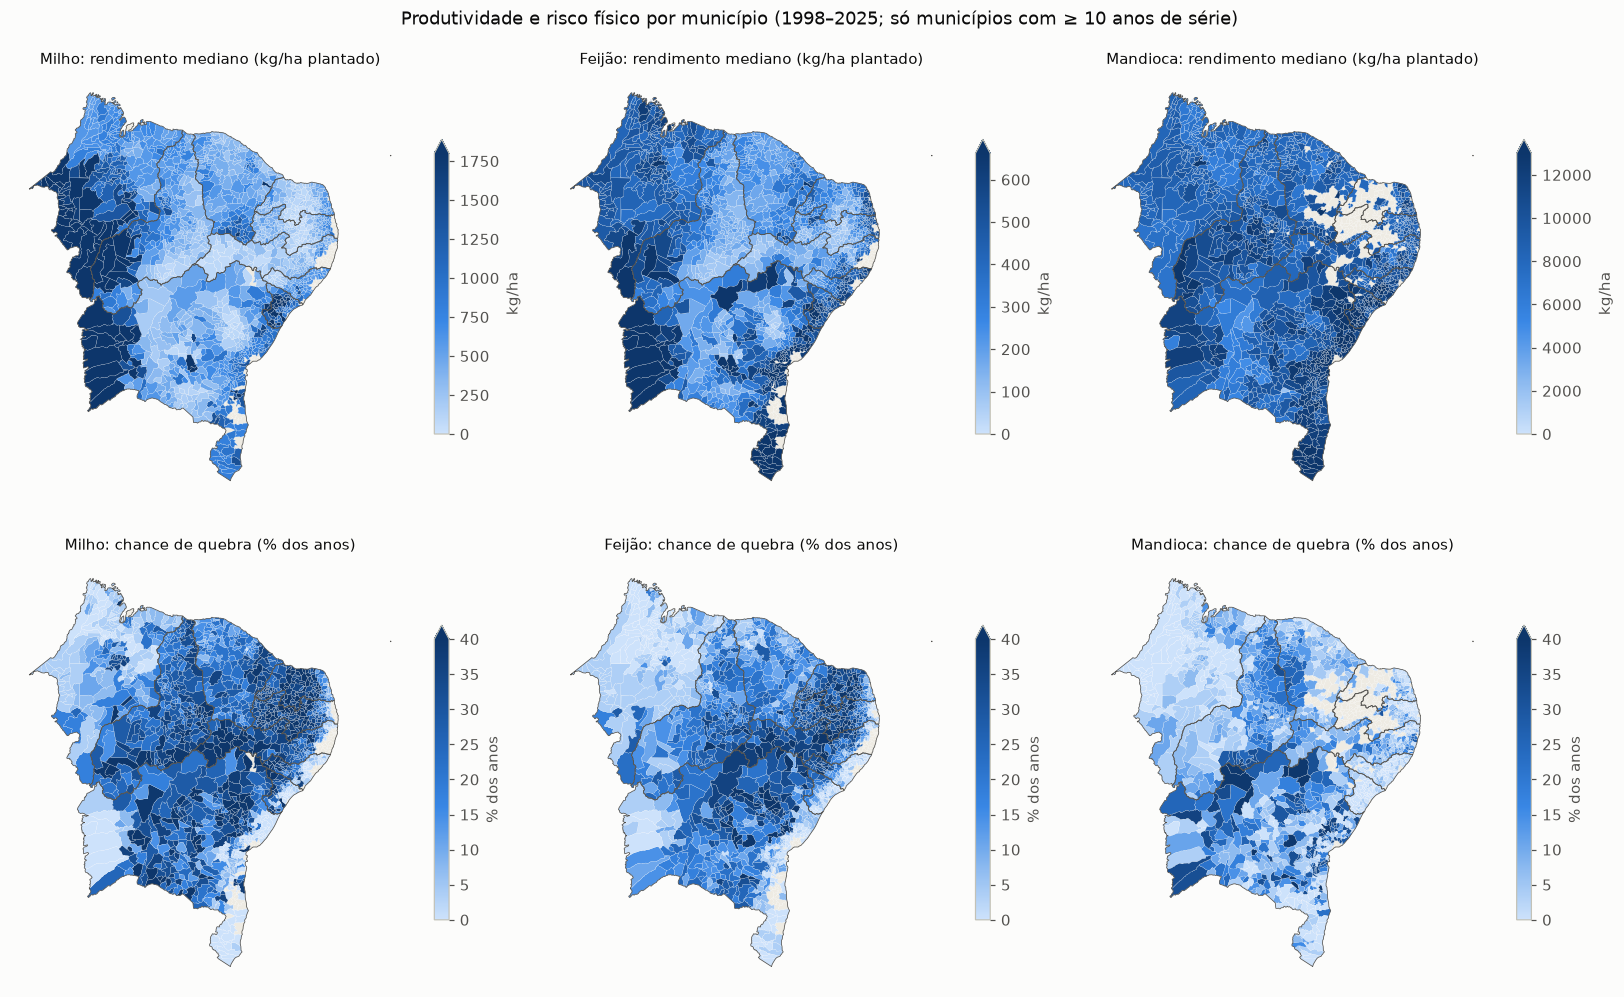

In [5]:
fig, axs = plt.subplots(2, 3, figsize=(15, 9.5))
for j, c in enumerate(["Milho", "Feijão", "Mandioca"]):
    m = mun[mun.produto == c].set_index("cod_mun")
    mapa_ne(axs[0, j], m.mediana, f"{c}: rendimento mediano (kg/ha plantado)", vmin=0, vmax=m.mediana.quantile(0.95), rotulo="kg/ha")
    mapa_ne(axs[1, j], m.p_quebra * 100, f"{c}: chance de quebra (% dos anos)", vmin=0, vmax=40, rotulo="% dos anos")
fig.suptitle("Produtividade e risco físico por município (1998–2025; só municípios com ≥ 10 anos de série)", fontsize=12)
plt.tight_layout()
plt.show()

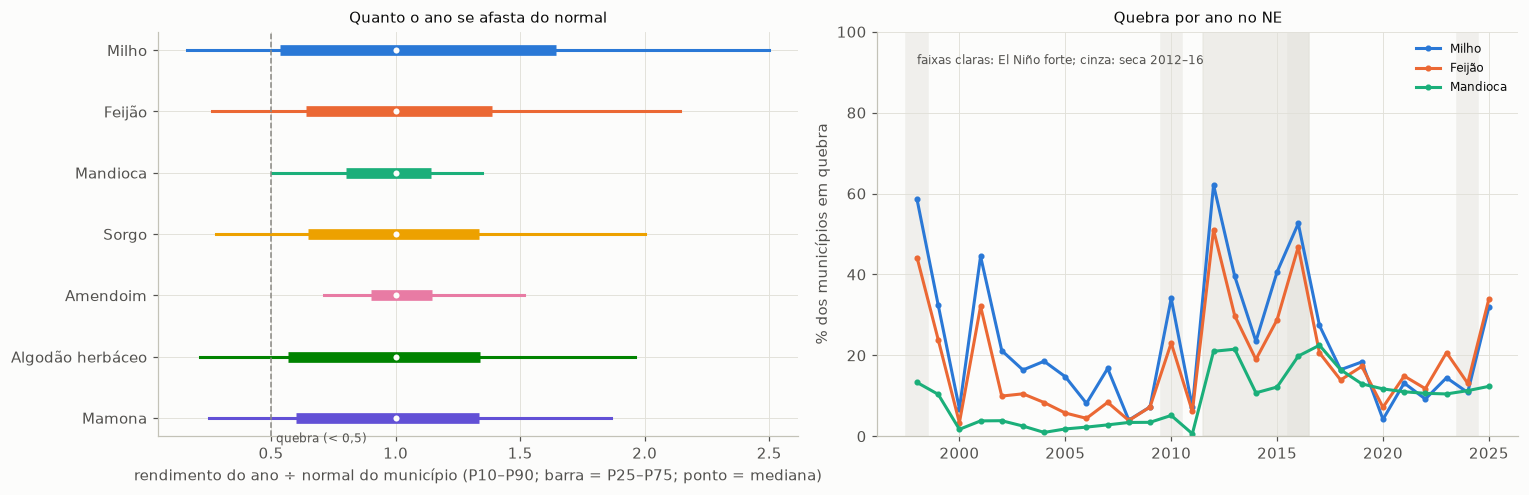

Quebra (% dos municípios) nos anos de El Niño forte e na seca:


ano,1998,2010,2016,2024,2012,2013,2014,2015,2016
produto,,,,,,,,,
Feijão,"44,00","23,00","47,00","13,00","51,00","30,00","19,00","29,00","47,00"
Mandioca,"13,00","5,00","20,00","11,00","21,00","22,00","11,00","12,00","20,00"
Milho,"59,00","34,00","53,00","11,00","62,00","40,00","23,00","41,00","53,00"


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
ordem = [c for c in CULT if c in tab.index]
for k, c in enumerate(ordem):
    r = S2[S2.produto == c].razao.clip(0, 2.5)
    q = r.quantile([0.1, 0.25, 0.5, 0.75, 0.9])
    axs[0].plot([q[0.1], q[0.9]], [k, k], color=COR[c], lw=2)
    axs[0].plot([q[0.25], q[0.75]], [k, k], color=COR[c], lw=7, solid_capstyle="butt")
    axs[0].plot(q[0.5], k, "o", color="#fcfcfb", ms=5, mec=COR[c])
axs[0].axvline(0.5, color=CINZA, ls="--", lw=1)
axs[0].text(0.52, len(ordem) - 0.6, "quebra (< 0,5)", fontsize=8, color="#52514e")
axs[0].set_yticks(range(len(ordem)), ordem)
axs[0].invert_yaxis()
axs[0].set_xlabel("rendimento do ano ÷ normal do município (P10–P90; barra = P25–P75; ponto = mediana)")
axs[0].set_title("Quanto o ano se afasta do normal", fontsize=10)
ano_q = S2[S2.produto.isin(["Milho", "Feijão", "Mandioca"])].groupby(["ano", "produto"]).quebra.mean().unstack() * 100
for c in ["Milho", "Feijão", "Mandioca"]:
    axs[1].plot(ano_q.index, ano_q[c], color=COR[c], label=c, marker="o", ms=3)
for a in EN_FORTE:
    axs[1].axvspan(a - 0.5, a + 0.5, color="#f0efec", zorder=0)
axs[1].axvspan(SECA[0] - 0.5, SECA[-1] + 0.5, color="#e1e0d9", alpha=0.5, zorder=0)
axs[1].text(EN_FORTE[0], 92, "faixas claras: El Niño forte; cinza: seca 2012–16", fontsize=8, color="#52514e")
axs[1].set_ylim(0, 100)
axs[1].set_ylabel("% dos municípios em quebra")
axs[1].legend(frameon=False, fontsize=8, loc="upper right")
axs[1].set_title("Quebra por ano no NE", fontsize=10)
plt.tight_layout()
plt.show()
anos_q = ano_q.round(0)
print("Quebra (% dos municípios) nos anos de El Niño forte e na seca:")
display(anos_q.loc[[a for a in EN_FORTE + SECA if a in anos_q.index]].T)

**Leitura.**
- **Conferência:** a quebra do milho em 2000–2024 dá **21,2% no NE e 20,2% no CE**, igual ao catálogo (21,0% e 20,2%).
- **Rendimento mediano por ha plantado:** milho 533 kg/ha, feijão 309, mandioca 9.289 kg de raiz, sorgo 1.061,
  amendoim 1.000, algodão 600, mamona 545.
- **Pior ano em 10 ÷ mediana:** 0,28 no milho, no algodão e na mamona; 0,35 no sorgo; 0,37 no feijão; **0,61 na
  mandioca**; 0,80 no amendoim.
- **Chance de quebra** (mediana dos municípios): milho 25% dos anos, algodão 23%, mamona 21%, feijão 18%, sorgo 17%,
  mandioca 6%, amendoim 0%.
- **O semiárido é outro mundo:** milho 421 contra 833 kg/ha fora dele, com quebra em 28% contra 8,5% dos anos;
  feijão 270 contra 500 kg/ha, quebra 23% contra 4%. A mandioca quase não muda (9.000 contra 9.500 kg/ha).
- **Por UF:** o RN tem a maior quebra de milho (36%) e de feijão (32%); MA, AL e SE, as menores (~7%).
- **Os anos ruins:** em 1998, 59% dos municípios quebraram o milho, 44% o feijão e 13% a mandioca. Em 2012: 62%, 51% e
  21%. Em 2016: 53%, 47% e 20%. Em 2024, El Niño forte, só 11%, 13% e 11%.
- **Qualidade do relato:** a mandioca repete o rendimento do ano anterior em 33% dos anos seguidos (25% nos anos em
  que o milho quebrou) e 73% dos valores são múltiplos de 100 kg/ha; o amendoim repete em 30%. Parte da estabilidade
  da mandioca e do amendoim é do relato, não da roça. As seções 6 e 7 herdam esse viés.

## 3. Preço: o que a família recebe, quanto varia e como se compara ao mercado

O preço implícito do PAM é o valor da produção ÷ a quantidade, em R$ de 2025 por kg (mandioca: kg de raiz). É uma
média municipal: não diz o preço de cada venda, nem separa o que foi vendido do que ficou para a família.

Medidas de volatilidade (2010–2025):
- **CV da série do NE**: desvio-padrão ÷ média da mediana anual do NE;
- **dp da variação anual**: desvio-padrão de ln(preço do ano ÷ preço do ano anterior);
- **CV dentro do município**: a mesma conta na série de cada município (mediana entre os municípios);
- **dispersão entre municípios**: no mesmo ano, (P75 − P25) ÷ mediana.

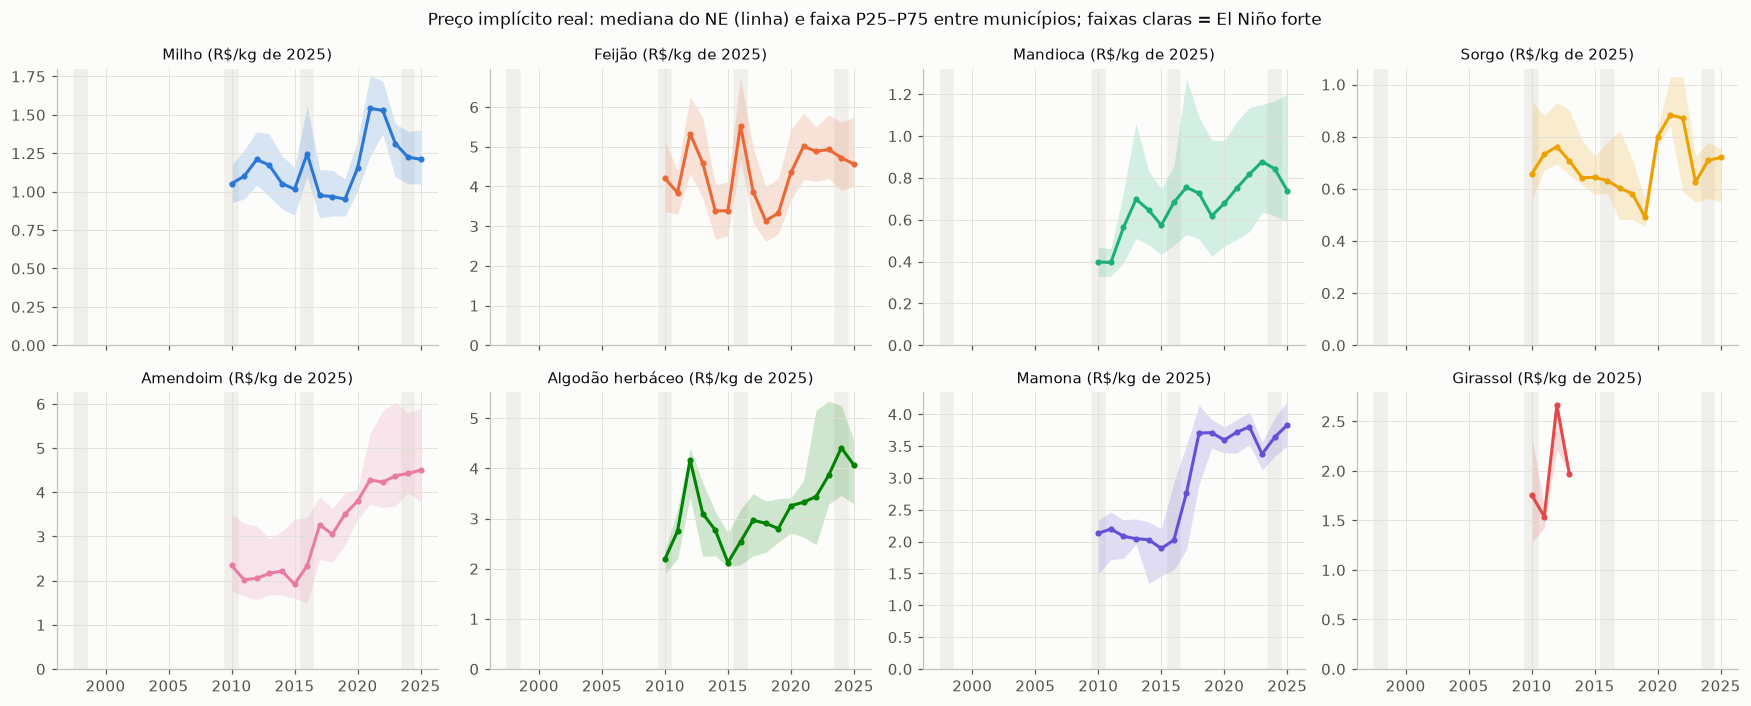

,preço mediano 2016–25 (R$/kg),CV da série do NE (%),dp da variação anual (ln),CV dentro do município (%),dispersão entre municípios,tendência real (%/ano)
produto,,,,,,
Milho,"1,18","15,32","0,14","22,93","0,29","1,36"
Feijão,"4,43","17,46","0,23","29,06","0,39","0,86"
Mandioca,"0,75","20,70","0,14","36,26","0,69","3,97"
Sorgo,"0,71","15,10","0,18","26,80","0,29","0,47"
Amendoim,"3,89","31,81","0,12","34,76","0,53","6,40"
Algodão herbáceo,"3,36","21,52","0,19","24,95","0,35","2,82"
Mamona,"3,49","27,98","0,12","30,80","0,24","5,26"
Girassol,NaN,"24,57","0,45",NaN,"0,17",NaN


Preço mediano 2016–2025 por UF (R$ de 2025/kg)


produto,Milho,Feijão,Mandioca,Sorgo,Amendoim,Algodão herbáceo,Mamona,Girassol
uf,,,,,,,,
MA,"0,97","3,31","0,54","0,55","2,87","3,54",NaN,NaN
PI,"1,23","4,80","0,47","0,53","5,01","2,09","2,03",NaN
CE,"1,23","5,32","0,84","1,01","5,68","3,24","1,94",NaN
RN,"1,45","5,25","0,73","0,85",NaN,"5,00",NaN,NaN
PB,"1,32","4,38","0,93",NaN,"6,26","3,43",NaN,NaN
PE,"1,34","4,82","1,27","1,04","3,17","5,43","3,13",NaN
AL,"1,33","4,20","1,09","1,19","4,57","2,38",NaN,NaN
SE,"1,22","3,80","0,80","0,55","2,42","2,10",NaN,NaN
BA,"1,05","4,48","0,91","0,72","3,79","3,73","3,62",NaN


In [7]:
PR = B[B.ano.between(2010, 2025) & B.preco.notna()]
serie = PR.groupby(["produto", "ano"]).preco.median().unstack(0).reindex(columns=CULT)
fig, axs = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True)
for ax, c in zip(axs.flat, CULT):
    s = serie[c].dropna()
    q = PR[PR.produto == c].groupby("ano").preco.quantile([0.25, 0.75]).unstack()
    ax.fill_between(q.index, q[0.25], q[0.75], color=COR[c], alpha=0.18, lw=0)
    ax.plot(s.index, s, color=COR[c], marker="o", ms=3)
    for a in EN_FORTE:
        ax.axvspan(a - 0.5, a + 0.5, color="#f0efec", zorder=0)
    ax.set_title(f"{c} (R$/kg de 2025)", fontsize=10)
    ax.set_ylim(0, None)
fig.suptitle("Preço implícito real: mediana do NE (linha) e faixa P25–P75 entre municípios; faixas claras = El Niño forte", fontsize=11)
plt.tight_layout()
plt.show()

vol = pd.DataFrame({
    "preço mediano 2016–25 (R$/kg)": PR[PR.ano.isin(PRECO_REF)].groupby("produto").preco.median(),
    "CV da série do NE (%)": serie.std() / serie.mean() * 100,
    "dp da variação anual (ln)": np.log(serie).diff().std(),
    "CV dentro do município (%)": PR.groupby(["produto", "cod_mun"]).preco.agg(lambda s: s.std() / s.mean() * 100 if len(s) >= 8 else np.nan).groupby("produto").median(),
    "dispersão entre municípios": PR.groupby(["produto", "ano"]).preco.agg(lambda s: (s.quantile(0.75) - s.quantile(0.25)) / s.median()).groupby("produto").median(),
    "tendência real (%/ano)": serie.apply(lambda s: np.polyfit(s.dropna().index, np.log(s.dropna()), 1)[0] * 100 if s.notna().sum() >= 5 else np.nan),
}).reindex(CULT)
display(vol.round(2))
puf = PR[PR.ano.isin(PRECO_REF)].pivot_table(index="uf", columns="produto", values="preco", aggfunc="median").reindex(index=UFS, columns=CULT)
print("Preço mediano 2016–2025 por UF (R$ de 2025/kg)")
display(puf.round(2))

**O preço sobe quando a safra cai?** Se sobe, o preço protege parte da renda no ano ruim (um "seguro natural").
Testamos em duas escalas: no NE inteiro (preço mediano do ano contra a produção total do NE) e dentro do município
(preço relativo à UF no ano contra a razão ao normal do rendimento do próprio município).

In [8]:
prod_ne = P[P.ano.between(2010, 2025)].groupby(["produto", "ano"]).producao_t.sum().unstack(0)
hedge = {}
for c in CULT:
    a = pd.concat([serie[c], prod_ne.get(c)], axis=1).dropna()
    rho_ne = a.corr(method="spearman").iloc[0, 1] if len(a) >= 8 else np.nan
    m = PR[PR.produto == c].copy()
    m["p_rel"] = np.log(m.preco / m.groupby(["uf", "ano"]).preco.transform("median"))
    m = m[m.razao.between(0.01, 5)]
    rho_mun = m[["p_rel", "razao"]].corr(method="spearman").iloc[0, 1] if len(m) > 50 else np.nan
    hedge[c] = {"ρ preço × produção do NE (anos)": rho_ne, "ρ preço relativo × razão do município": rho_mun, "n município-anos": len(m)}
display(pd.DataFrame(hedge).T.round(2))

# razão feijão ÷ milho por kg, semiárido do NE, 2010–2024 (o catálogo diz ≈ 3,61×, grau D)
fm = PR[PR.semiarido & PR.ano.between(2010, 2024) & PR.produto.isin(["Feijão", "Milho"])].pivot_table(index=["cod_mun", "ano"], columns="produto", values="preco")
fm = fm.dropna()
print(f"Preço do feijão ÷ milho no semiárido (2010–2024): mediana dos município-anos {num(np.median(fm.Feijão / fm.Milho))}× "
      f"(P25 {num((fm.Feijão / fm.Milho).quantile(.25))}, P75 {num((fm.Feijão / fm.Milho).quantile(.75))}); "
      f"razão das medianas {num(fm.Feijão.median() / fm.Milho.median())}×; n = {len(fm)}")

,ρ preço × produção do NE (anos),ρ preço relativo × razão do município,n município-anos
Milho,"0,36","-0,05","23.450,00"
Feijão,"-0,79","-0,08","24.659,00"
Mandioca,"-0,60","-0,01","21.691,00"
Sorgo,"-0,11","-0,02","1.276,00"
Amendoim,"0,54","0,05","2.133,00"
Algodão herbáceo,"0,52","0,01","1.764,00"
Mamona,"0,04","0,11","2.138,00"
Girassol,NaN,"-0,23","104,00"


Preço do feijão ÷ milho no semiárido (2010–2024): mediana dos município-anos 3,61× (P25 3,00, P75 4,51); razão das medianas 3,76×; n = 16672


**Comparação com o mercado.** A FAOSTAT publica o preço ao produtor do Brasil inteiro (moeda local por tonelada); o
Banco Mundial (Pink Sheet) publica o preço mundial em dólar. Usamos os dois só para comparar o nível (FAOSTAT,
deflacionado pelo mesmo IPCA) e a volatilidade (variação anual em ln, sem unidade), não como preço local.

In [9]:
FAO_ITEM = {"Maize (corn)": "Milho", "Beans, dry": "Feijão", "Cassava, fresh": "Mandioca", "Sorghum": "Sorgo",
            "Groundnuts, excluding shelled": "Amendoim", "Seed cotton, unginned": "Algodão herbáceo",
            "Castor oil seeds": "Mamona", "Sunflower seed": "Girassol"}
fao = pd.read_parquet(DERIV / "faostat_precos_produtor.parquet")
fao = fao[(fao.Area == "Brazil") & (fao.Element == "Producer Price (LCU/tonne)") & (fao.Months == "Annual value") & fao.Item.isin(FAO_ITEM)]
ipa = pd.read_csv(F / "ipca_anual.csv").set_index("ano").fator_r2025
fao = fao.assign(produto=fao.Item.map(FAO_ITEM), preco=fao.Value / 1000 * fao.Year.map(ipa))
fao = fao[fao.Year.between(2010, 2025)].pivot_table(index="Year", columns="produto", values="preco")
comp = pd.DataFrame({"PAM NE 2016–25 (R$/kg)": serie.loc[2016:2025].median(),
                     "FAOSTAT Brasil 2016–25 (R$/kg)": fao.loc[2016:2025].median(),
                     "anos FAOSTAT": fao.loc[2010:2025].notna().sum()}).reindex(CULT)
comp["NE ÷ Brasil"] = comp.iloc[:, 0] / comp.iloc[:, 1]
comp["ρ das variações anuais"] = [np.log(serie[c]).diff().corr(np.log(fao[c]).diff()) if c in fao and fao[c].notna().sum() >= 8 else np.nan for c in CULT]
display(comp.round(2))

pk = pd.read_parquet(DERIV / "mercado_precos_mensal.parquet")
PINK = {"Maize": "Milho", "Sorghum": "Sorgo", "Groundnuts": "Amendoim", "Cotton, A Index": "Algodão herbáceo (pluma)", "Sunflower oil": "Girassol (óleo)"}
pk = pk[pk.commodity.isin(PINK)]
pa = pk.assign(ano=pk.data.dt.year).groupby(["commodity", "ano"]).preco.mean().unstack(0)
pa = pa.loc[2010:2025]
vm = pd.DataFrame({"dp da variação anual (ln), mundo US$": np.log(pa).diff().std(), "anos": pa.notna().sum()})
vm.index = vm.index.map(PINK)
display(vm.round(2))

,PAM NE 2016–25 (R$/kg),FAOSTAT Brasil 2016–25 (R$/kg),anos FAOSTAT,NE ÷ Brasil,ρ das variações anuais
produto,,,,,
Milho,"1,22","0,90",14,"1,36","0,83"
Feijão,"4,64","4,62",14,"1,00","0,79"
Mandioca,"0,75","0,84",14,"0,88","0,15"
Sorgo,"0,67","0,69",7,"0,96",NaN
Amendoim,"4,01","3,49",7,"1,15",NaN
Algodão herbáceo,"3,29","4,13",14,"0,80","0,30"
Mamona,"3,67","3,59",7,"1,02",NaN
Girassol,NaN,"2,00",7,NaN,NaN


,"dp da variação anual (ln), mundo US$",anos
commodity,,
Algodão herbáceo (pluma),"0,24",16
Amendoim,"0,24",16
Milho,"0,23",16
Sorgo,"0,20",11
Girassol (óleo),"0,24",16


**Leitura.**
- **Preço mediano 2016–2025** (R$ de 2025/kg): feijão 4,43; amendoim 3,89; mamona 3,49; algodão 3,36; milho 1,18;
  mandioca 0,75; sorgo 0,71.
- **Feijão ÷ milho = 3,61×** no semiárido (2010–2024; P25 3,00, P75 4,51; n = 16.672). Confirma o 3,61 do catálogo.
- **Volatilidade:** a mediana do NE varia pouco de um ano para o outro (dp do ln de 0,12 a 0,23; a maior é a do
  feijão). O preço mundial em dólar varia mais (0,20–0,24 no milho, sorgo, amendoim e algodão). Dentro do município, o
  CV vai de 23% (milho) a 36% (mandioca). No mesmo ano, a mandioca tem a maior dispersão entre municípios (0,69): é
  mercado local.
- **Tendência real:** amendoim +6,4%/ano, mamona +5,3%, mandioca +4,0%, algodão +2,8%, milho +1,4%, feijão +0,9%.
- **"Seguro natural" só regional:** no NE inteiro, o preço do feijão sobe quando a produção cai (ρ −0,79), e o da
  mandioca também (ρ −0,60); o do milho, não (+0,36). Dentro do município, o preço relativo não acompanha a quebra
  local (ρ de −0,08 a +0,11). A família só ganha preço alto quando a região toda quebra.
- **FAOSTAT:** o feijão do NE vale o mesmo que o do Brasil (1,00×); o milho vale 1,36× (o NE compra milho de fora); a
  mandioca, 0,88×. As variações anuais do milho e do feijão andam com as do Brasil (ρ 0,83 e 0,79); as da mandioca,
  não (0,15).

## 4. Receita bruta por hectare: plantado, colhido e por mês de terra

**Receita observada** = valor da produção (R$ de 2025) ÷ área, 2010–2025. Por **ha plantado**, o ano de perda total
entra como receita zero; por **ha colhido**, ele some (a área colhida é zero). A diferença entre as duas mede o
quanto a perda de área esconde.

**Receita por hectare-mês** = receita por ha plantado ÷ meses de ocupação da terra (tabela `CICLO`, seção 1). Ela
responde a outra pergunta: com a mesma terra e o mesmo tempo, qual cultura gera mais dinheiro. Os ciclos são
parâmetros (só a mandioca tem a duração escrita numa fonte oficial lida, a planilha da CONAB), então a figura mostra a
faixa de cada um.

Receita observada, R$ de 2025 por ha (mediana entre os municípios da mediana 2010–2025 de cada um)


,municipios,plantado,colhido,p10,p90,anos_receita_zero_pct,colhido ÷ plantado,meses de ciclo,por ha-mês,por ha-mês (faixa do ciclo)
produto,,,,,,,,,,
Milho,1689,"597,55","675,44","171,03","1.222,75","4,70","1,13","3,62","165,14",R$ 151 a R$ 182
Feijão,1692,"1.181,77","1.368,62","499,07","2.217,05","2,62","1,16","2,30","513,22",R$ 479 a R$ 599
Mandioca,1523,"5.341,81","5.477,40","3.216,41","8.650,17","0,51","1,03","15,00","356,12",R$ 296 a R$ 445
Sorgo,94,"688,20","758,06","241,68","1.145,90","5,28","1,10","3,62","190,19",R$ 174 a R$ 209
Amendoim,165,"3.633,01","3.692,83","1.824,69","5.496,42","0,00","1,02","3,29","1.104,44",R$ 920 a R$ 1.227
Algodão herbáceo,297,"1.566,98","1.776,38","784,27","2.506,34","7,71","1,13","4,61","340,26",R$ 298 a R$ 397
Mamona,206,"735,31","886,55","254,24","1.293,23","6,22","1,21","5,92","124,19",R$ 93 a R$ 149


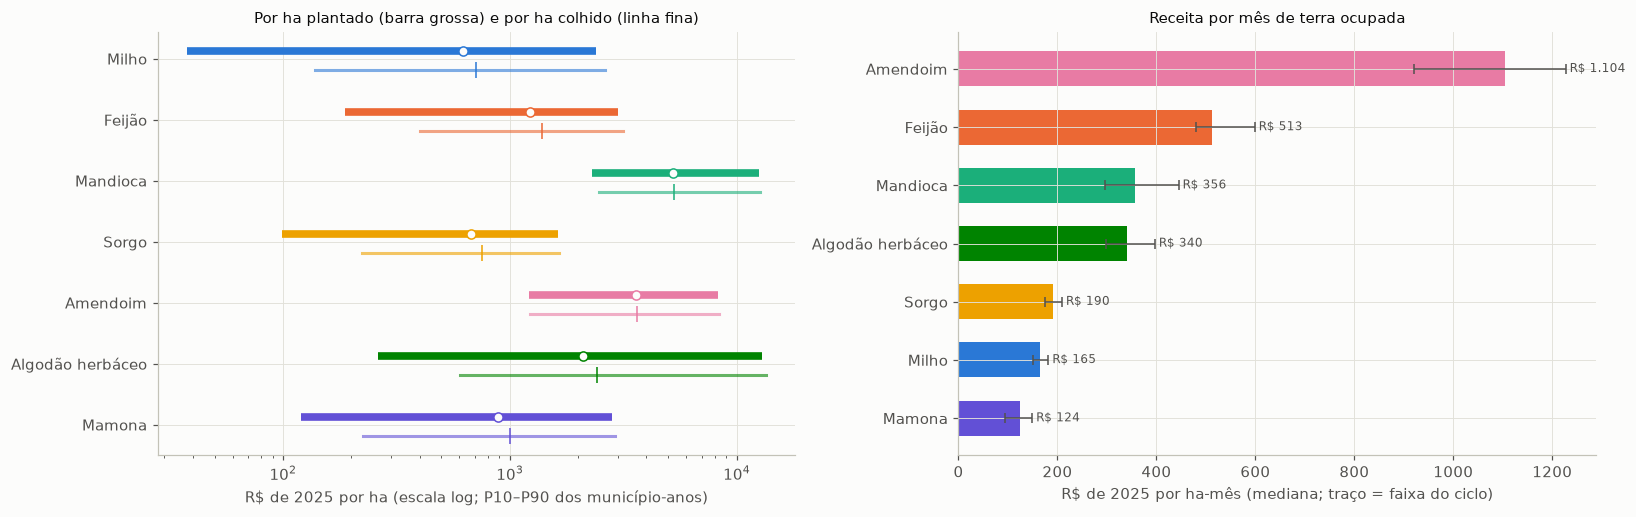

In [10]:
RO = B[B.ano.between(2010, 2025) & (B.n_anos >= ANOS_MIN)]
rm = RO.groupby(["produto", "cod_mun"]).agg(plantado=("R_obs", "median"), colhido=("R_obs_col", "median"),
                                            p10=("R_obs", lambda s: s.quantile(0.1)), p90=("R_obs", lambda s: s.quantile(0.9)),
                                            zero=("R_obs", lambda s: (s <= 0).mean())).reset_index()
rec = rm.groupby("produto").agg(municipios=("cod_mun", "size"), plantado=("plantado", "median"), colhido=("colhido", "median"),
                                p10=("p10", "median"), p90=("p90", "median"), anos_receita_zero_pct=("zero", lambda s: s.mean() * 100)).reindex(CULT).dropna(how="all")
rec["municipios"] = rec.municipios.astype(int)
rec["colhido ÷ plantado"] = rec.colhido / rec.plantado
rec["meses de ciclo"] = CICLO.dias.reindex(rec.index) / 30.4
rec["por ha-mês"] = rec.plantado / rec["meses de ciclo"]
rec["por ha-mês (faixa do ciclo)"] = [f"{brl(rec.plantado[c] / (CICLO.dias_max[c] / 30.4))} a {brl(rec.plantado[c] / (CICLO.dias_min[c] / 30.4))}" for c in rec.index]
print("Receita observada, R$ de 2025 por ha (mediana entre os municípios da mediana 2010–2025 de cada um)")
display(rec.round(2))

fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
ordem = list(rec.index)
for k, c in enumerate(ordem):
    s = RO[RO.produto == c]
    q = s.R_obs.quantile([0.1, 0.5, 0.9])
    qc = s.R_obs_col.quantile([0.1, 0.5, 0.9])
    axs[0].plot([max(q[0.1], 10), q[0.9]], [k - 0.12, k - 0.12], color=COR[c], lw=5, solid_capstyle="butt")
    axs[0].plot(q[0.5], k - 0.12, "o", color="#fcfcfb", mec=COR[c], ms=6)
    axs[0].plot([max(qc[0.1], 10), qc[0.9]], [k + 0.18, k + 0.18], color=COR[c], lw=2, alpha=0.6)
    axs[0].plot(qc[0.5], k + 0.18, "|", color=COR[c], ms=10)
axs[0].set_xscale("log")
axs[0].set_yticks(range(len(ordem)), ordem)
axs[0].invert_yaxis()
axs[0].set_xlabel("R$ de 2025 por ha (escala log; P10–P90 dos município-anos)")
axs[0].set_title("Por ha plantado (barra grossa) e por ha colhido (linha fina)", fontsize=10)
hm = rec["por ha-mês"].sort_values()
lo = [rec.plantado[c] / (CICLO.dias_max[c] / 30.4) for c in hm.index]
hi = [rec.plantado[c] / (CICLO.dias_min[c] / 30.4) for c in hm.index]
axs[1].barh(range(len(hm)), hm.values, color=[COR[c] for c in hm.index], height=0.6)
axs[1].errorbar(hm.values, range(len(hm)), xerr=[hm.values - lo, np.array(hi) - hm.values], fmt="none", ecolor="#52514e", capsize=3, lw=1)
for k, (c, v) in enumerate(hm.items()):
    axs[1].text(hi[k] + 8, k, brl(v), va="center", fontsize=8, color="#52514e")
axs[1].set_yticks(range(len(hm)), hm.index)
axs[1].set_xlabel("R$ de 2025 por ha-mês (mediana; traço = faixa do ciclo)")
axs[1].set_title("Receita por mês de terra ocupada", fontsize=10)
plt.tight_layout()
plt.show()

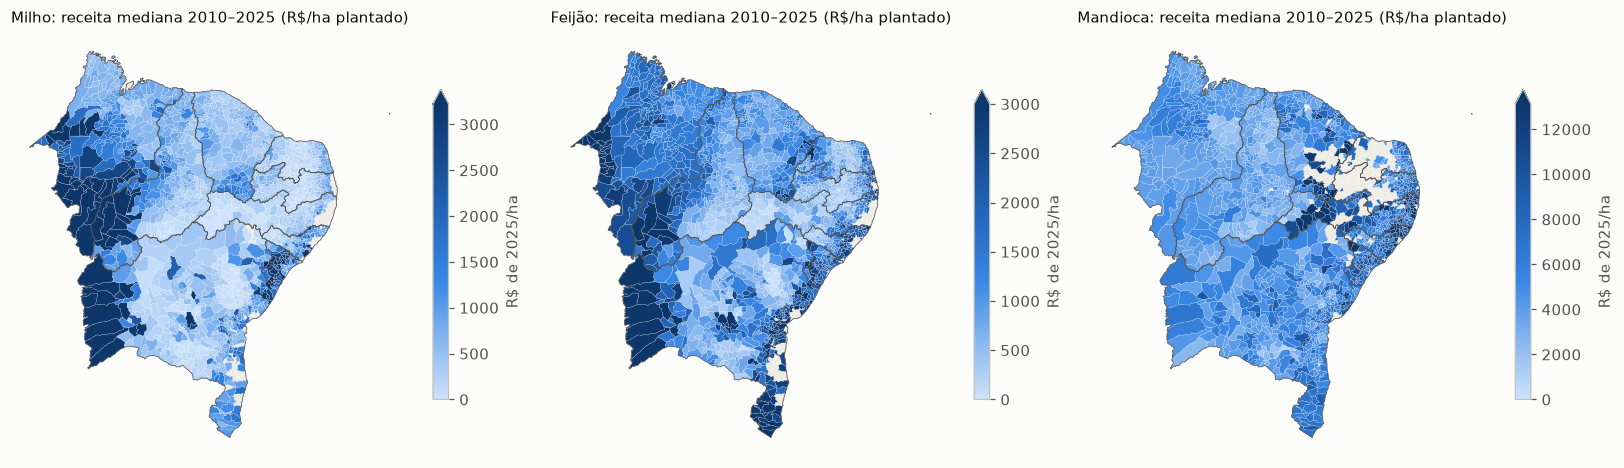

Receita observada mediana por UF (R$ de 2025 por ha plantado)


produto,Milho,Feijão,Mandioca,Sorgo,Amendoim,Algodão herbáceo,Mamona
uf,,,,,,,
MA,"1.153,00","1.664,00","4.248,00","1.131,00","4.515,00","13.659,00",NaN
PI,"709,00","1.003,00","3.522,00","1.085,00","3.302,00","748,00","230,00"
CE,"566,00","1.025,00","6.066,00","1.522,00","4.576,00","1.900,00","311,00"
RN,"303,00","977,00","5.968,00","1.263,00",NaN,"1.154,00",NaN
PB,"375,00","769,00","7.357,00",NaN,"4.518,00","2.198,00","659,00"
PE,"314,00","904,00","9.013,00","126,00","12.225,00","1.485,00","659,00"
AL,"868,00","1.769,00","9.248,00",NaN,"7.800,00","623,00",NaN
SE,"2.426,00","2.158,00","8.443,00",NaN,"3.754,00",NaN,NaN
BA,"539,00","1.267,00","5.245,00","508,00","2.506,00","1.995,00","1.060,00"


In [11]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, c in zip(axs, ["Milho", "Feijão", "Mandioca"]):
    m = rm[rm.produto == c].set_index("cod_mun").plantado
    mapa_ne(ax, m, f"{c}: receita mediana 2010–2025 (R$/ha plantado)", vmin=0, vmax=m.quantile(0.95), rotulo="R$ de 2025/ha")
plt.tight_layout()
plt.show()
ruf = rm.assign(uf=rm.cod_mun.str[:2].map(dict(zip(["21", "22", "23", "24", "25", "26", "27", "28", "29"], UFS)))).pivot_table(
    index="uf", columns="produto", values="plantado", aggfunc="median").reindex(index=UFS, columns=CULT).dropna(axis=1, how="all")
print("Receita observada mediana por UF (R$ de 2025 por ha plantado)")
display(ruf.round(0))

In [12]:
# conferência: a receita a preço de referência (usada nas seções 5 a 10) contra a observada, nos mesmos município-anos
cf = RO.dropna(subset=["R", "R_obs"])
c2 = pd.DataFrame({"mediana observada": cf.groupby("produto").R_obs.median(), "mediana a preço de ref.": cf.groupby("produto").R.median(),
                   "ρ de Spearman": cf.groupby("produto").apply(lambda g: g.R.corr(g.R_obs, method="spearman")),
                   "dp ln(observada ÷ ref.)": cf[(cf.R > 0) & (cf.R_obs > 0)].groupby("produto").apply(lambda g: np.log(g.R_obs / g.R).std())}).reindex(CULT)
display(c2.round(2))

,mediana observada,mediana a preço de ref.,ρ de Spearman,dp ln(observada ÷ ref.)
produto,,,,
Milho,"619,28","647,25","0,98","0,25"
Feijão,"1.230,15","1.338,18","0,91","0,34"
Mandioca,"5.229,40","6.142,34","0,72","0,45"
Sorgo,"677,59","712,38","0,94","0,29"
Amendoim,"3.614,03","3.970,17","0,78","0,45"
Algodão herbáceo,"2.109,73","2.592,51","0,96","0,37"
Mamona,"885,23","1.450,00","0,89","0,48"
Girassol,NaN,NaN,NaN,NaN


**Leitura.**
- **Receita observada mediana, 2010–2025, por ha plantado:** mandioca R$ 5.342; amendoim R$ 3.633; algodão R$ 1.567;
  feijão R$ 1.182; mamona R$ 735; sorgo R$ 688; milho R$ 598.
- **Por ha colhido**, milho, feijão, algodão e mamona ficam 13% a 21% acima: o PAM por área colhida esconde a perda de
  área. Na mandioca e no amendoim a diferença é de 2–3%.
- **Por ha-mês, a ordem muda:** amendoim R$ 1.104; **feijão R$ 513** (R$ 479 a 599 com ciclo de 60 a 75 dias);
  mandioca R$ 356 (R$ 296 a 445 para 12 a 18 meses); algodão R$ 340; sorgo R$ 190; milho R$ 165; mamona R$ 124. O
  caupi precoce é o que mais rende por mês de terra entre as culturas do roçado; a mandioca rende muito por hectare,
  mas prende a terra por mais de um ano.
- **Por UF:** a mandioca rende R$ 9.248/ha em AL e R$ 9.013 em PE, contra R$ 3.522 no PI; o milho rende R$ 2.426 em SE
  e R$ 1.153 no MA, contra R$ 303 no RN e R$ 314 em PE.
- **Conferência:** a receita a preço de referência acompanha a observada (ρ de 0,72 a 0,98). Fica acima na mandioca
  (+17%), no algodão (+23%) e na mamona (+64%), porque o preço real dessas culturas subiu desde 2010 e a referência é
  a de 2016–2025.

## 5. Custo, margem bruta e ponto de equilíbrio

**Fonte do custo.** A CONAB publica séries históricas de custo de produção estimado, por cultura e município
(www.gov.br/conab → Planilhas de custos de produção → Agrícolas; baixadas em 14/11/2026 com TLS verificado). O script
extraiu só as folhas do Nordeste. Cada planilha traz o local, a safra, o sistema (agricultura familiar ou empresarial),
a produtividade esperada, o mês dos preços e as linhas de custo em R$/ha. Deflacionamos pelo IPCA do mês dos preços.

**Três níveis de custo, todos da mesma planilha (nenhum número novo):**
1. **Semente** (ou maniva): o mínimo que sai do bolso se a família comprar a semente e fizer todo o resto sozinha;
2. **Desembolso** = custo operacional − mão de obra (inclui a "gestão da propriedade familiar" e o administrador):
   o que a planilha manda pagar em dinheiro (aluguel de máquina ou animal, defensivo, juros, manutenção);
3. **Custo operacional** (CONAB): o desembolso mais a mão de obra paga à diária. É o custo de quem contrata tudo, ou a
   régua de quanto a lavoura remunera o dia de trabalho da família.

**Quais planilhas valem para o sertão.** Só as de agricultura familiar e sequeiro do NE: feijão (9 locais, BA, CE, PI,
SE), mandioca (12 locais, MA, PI, BA, AL), mamona (Irecê-BA e São Raimundo Nonato-PI) e milho (Carira-SE, média
tecnologia, 6 t/ha). Para o milho do sertão usamos também a de **Crateús-CE** (milho "2ª safra", agricultura
empresarial de média tecnologia, 1,8 t/ha), que é a mais próxima do roçado cearense. Para cada local, a mediana das
últimas 5 planilhas. **Central** = mediana dos locais com planilha de 2019 em diante (no milho, o central é Crateús-CE
e Carira-SE fica como teto); **faixa** = do menor ao maior local.

**Sem planilha da CONAB no NE:** sorgo (só Barreiras-BA, alta tecnologia), algodão (só Barreiras-BA, empresarial),
amendoim (só SP) e girassol (só MT e RS). Para eles o custo é **suposição**: o de uma lavoura anual manual do NE pela
CONAB (mediana dos locais de feijão, mamona e milho de Crateús), com a faixa do menor ao maior local. O ponto de
equilíbrio (seção 5.3) não depende dessa suposição.

In [13]:
C = pd.read_csv(F / "conab_custos_ne.csv", parse_dates=["mes_precos"])
C["lugar"] = C.folha.str.rsplit("-", n=1).str[0].str.replace("Giral do Ponciano", "Girau do Ponciano")
C["produto"] = C.cultura_arquivo.map({"Feijão 1ª safra": "Feijão", "Mandioca": "Mandioca", "Mamona": "Mamona", "Milho 1ª safra": "Milho"})
crateus = (C.cultura_arquivo == "Milho 2ª safra") & C.lugar.str.startswith("Crateús")
C.loc[crateus, "produto"] = "Milho"
usa = C.produto.notna() & ~C.irrigado & (C.familiar | crateus)
U = C[usa].sort_values("ano_folha").groupby(["produto", "lugar"]).tail(5)
loc = U.groupby(["produto", "lugar", "uf"]).agg(
    planilhas=("folha", "size"), de=("ano_folha", "min"), ate=("ano_folha", "max"), sistema=("sistema", "first"),
    produtividade_conab_kg_ha=("produtividade_kg_ha", "median"), semente=("sementes_r_ha_r2025", "median"),
    mao_de_obra=("mao_de_obra_r_ha_r2025", "median"), desembolso=("desembolso_r_ha_r2025", "median"),
    custo_operacional=("custo_operacional_r_ha_r2025", "median")).reset_index()
print("Planilhas da CONAB usadas (R$ de 2025 por ha; mediana das últimas 5 de cada local)")
display(loc.round(0))


def custo_central(g):
    rec = g[g.ate >= 2019]
    base = rec if len(rec) else g
    return pd.Series({"semente": base.semente.median(), "desembolso": base.desembolso.median(), "custo_operacional": base.custo_operacional.median(),
                      "op_min": g.custo_operacional.min(), "op_max": g.custo_operacional.max(), "des_min": g.desembolso.min(), "des_max": g.desembolso.max(),
                      "produtividade_conab": base.produtividade_conab_kg_ha.median(), "locais": len(g), "locais_recentes": len(rec)})


CUSTO = loc.groupby("produto").apply(custo_central)
CUSTO["origem"] = "CONAB, NE"
# milho: o central é Crateús-CE (1,8 t/ha, o mais perto do roçado do sertão); Carira-SE (6 t/ha, OGM, adubado) fica como teto
cr = loc[(loc.produto == "Milho") & loc.lugar.str.startswith("Crateús")].iloc[0]
CUSTO.loc["Milho", ["semente", "desembolso", "custo_operacional", "produtividade_conab"]] = [cr.semente, cr.desembolso, cr.custo_operacional, cr.produtividade_conab_kg_ha]
CUSTO.loc["Milho", "origem"] = "CONAB, Crateús-CE (teto: Carira-SE)"
anual = loc[loc.produto.isin(["Feijão", "Mamona"]) | loc.lugar.str.startswith("Crateús")]
sup = custo_central(anual)
for c in ["Sorgo", "Amendoim", "Algodão herbáceo", "Girassol"]:
    CUSTO.loc[c] = sup
    CUSTO.loc[c, "origem"] = "suposição: lavoura anual manual do NE (CONAB)"
    CUSTO.loc[c, "produtividade_conab"] = np.nan
CUSTO = CUSTO.reindex(CULT)
display(CUSTO.round(0))

Planilhas da CONAB usadas (R$ de 2025 por ha; mediana das últimas 5 de cada local)


,produto,lugar,uf,planilhas,de,ate,sistema,produtividade_conab_kg_ha,semente,mao_de_obra,desembolso,custo_operacional
0,Feijão,Brejo Santo-CE,CE,5,2020,2024,"agricultura familiar, sequeiro","800,00","142,00","1.855,00","1.992,00","3.847,00"
1,Feijão,Crateús-CE,CE,5,2010,2014,"agricultura familiar, sequeiro","1.000,00","229,00","1.785,00","1.271,00","3.055,00"
2,Feijão,Guanambi-BA,BA,5,2020,2024,"agricultura familiar, sequeiro","540,00","114,00","1.540,00","3.212,00","4.701,00"
3,Feijão,Irecê-BA,BA,5,2011,2019,"agricultura familiar, sequeiro","720,00","345,00","956,00","1.346,00","2.499,00"
4,Feijão,Macaúbas-BA,BA,5,2010,2014,"agricultura familiar, sequeiro","600,00","93,00","1.526,00","590,00","2.134,00"
5,Feijão,Poço Redondo-SE,SE,4,2011,2014,"agricultura familiar, sequeiro","750,00","107,00","1.132,00","1.067,00","2.222,00"
6,Feijão,Poço Verde-SE,SE,5,2014,2018,"agricultura familiar, sequeiro","1.200,00","142,00","678,00","1.826,00","2.510,00"
7,Feijão,R. do Pombal-BA,BA,5,2014,2018,"agricultura familiar, sequeiro","1.000,00","239,00","1.034,00","1.766,00","2.764,00"
8,Feijão,S.R.Nonato-PI,PI,5,2010,2014,"agricultura familiar, sequeiro","700,00","141,00","2.358,00","1.701,00","4.060,00"
9,Mamona,1º Ciclo-S. R. Nonato-PI,PI,5,2010,2014,"agricultura familiar, sequeiro","800,00","94,00","1.145,00","722,00","1.867,00"


,semente,desembolso,custo_operacional,op_min,op_max,des_min,des_max,produtividade_conab,locais,locais_recentes,origem
produto,,,,,,,,,,,
Milho,"284,00","1.136,00","1.845,00","1.845,00","5.178,00","1.136,00","4.476,00","1.800,00","2,00","2,00","CONAB, Crateús-CE (teto: Carira-SE)"
Feijão,"142,00","1.992,00","3.847,00","2.134,00","4.701,00","590,00","3.212,00","720,00","9,00","3,00","CONAB, NE"
Mandioca,"0,00","4.387,00","8.678,00","2.617,00","13.002,00","229,00","5.602,00","16.000,00","12,00","4,00","CONAB, NE"
Sorgo,"142,00","1.992,00","3.847,00","1.845,00","4.701,00","491,00","3.212,00",NaN,"13,00","5,00",suposição: lavoura anual manual do NE (CONAB)
Amendoim,"142,00","1.992,00","3.847,00","1.845,00","4.701,00","491,00","3.212,00",NaN,"13,00","5,00",suposição: lavoura anual manual do NE (CONAB)
Algodão herbáceo,"142,00","1.992,00","3.847,00","1.845,00","4.701,00","491,00","3.212,00",NaN,"13,00","5,00",suposição: lavoura anual manual do NE (CONAB)
Mamona,"39,00","2.656,00","4.089,00","1.867,00","4.089,00","491,00","2.656,00","1.200,00","3,00","1,00","CONAB, NE"
Girassol,"142,00","1.992,00","3.847,00","1.845,00","4.701,00","491,00","3.212,00",NaN,"13,00","5,00",suposição: lavoura anual manual do NE (CONAB)


### 5.1 Margem bruta e chance de não pagar o custo

Margem = receita a preço de referência (rendimento do ano × preço de referência do município) − custo. A receita
varia de ano para ano; o custo fica fixo no valor central (a faixa entra na seção 5.4). A chance de não pagar é a
fração dos anos (1998–2025) em que a receita ficou abaixo do custo.

,municipios,receita_mediana,margem (semente),margem (desembolso),margem (custo operacional),não paga semente (% dos anos),não paga desembolso (% dos anos),não paga custo operacional (% dos anos),"municípios com margem > 0 (semente, %)","municípios com margem > 0 (desembolso, %)","municípios com margem > 0 (custo operacional, %)"
produto,,,,,,,,,,,
Milho,1690,"616,80","333,00","-519,20","-1.228,40","17,90","85,70","100,00","83,40","15,30","6,00"
Feijão,1693,"1.408,50","1.267,00","-583,60","-2.438,50","0,00","75,00","100,00","99,90","24,10","1,20"
Mandioca,1528,"7.648,10","7.648,10","3.261,30","-1.030,00","0,00","10,70","67,90","100,00","83,20","40,10"
Sorgo,95,"825,40","683,90","-1.166,70","-3.021,60","3,70","100,00","100,00","100,00","8,40","0,00"
Amendoim,165,"3.757,00","3.615,50","1.764,90","-90,00","0,00","0,00","62,50","100,00","93,90","43,00"
Algodão herbáceo,324,"2.323,50","2.182,00","331,40","-1.523,50","0,00","40,00","88,30","100,00","64,20","17,00"
Mamona,207,"1.973,90","1.935,20","-682,60","-2.114,90","0,00","81,50","100,00","100,00","11,60","0,00"


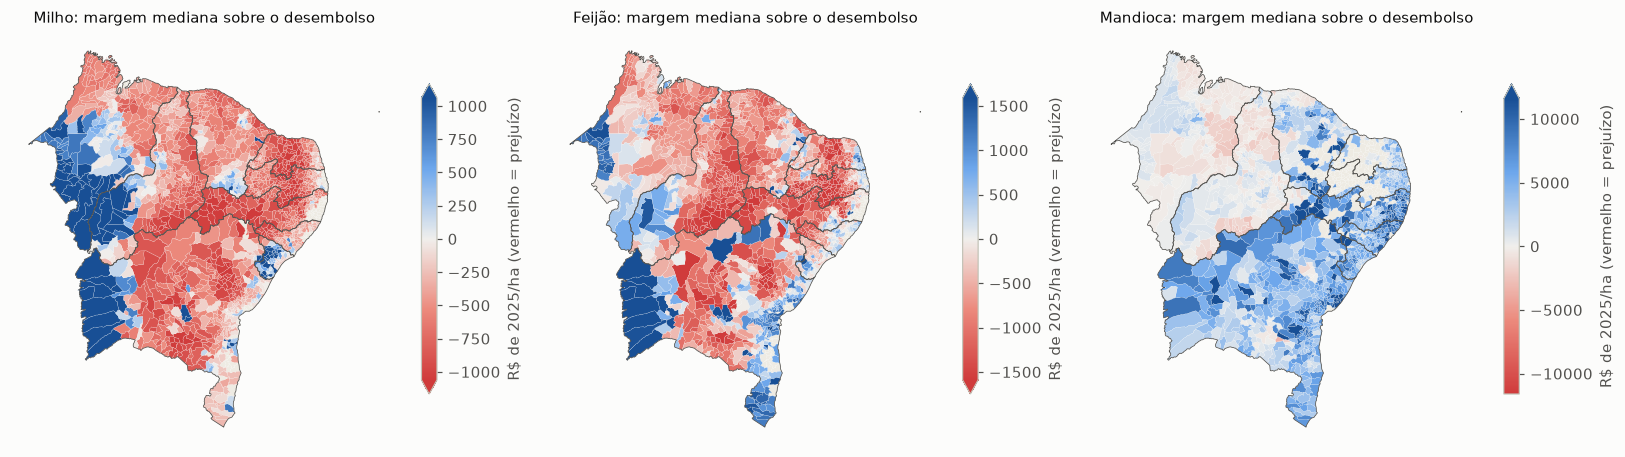

In [14]:
NIV = ["semente", "desembolso", "custo_operacional"]
NOME_NIV = {"semente": "semente", "desembolso": "desembolso", "custo_operacional": "custo operacional"}
M = B[B.n_anos >= ANOS_MIN].copy()
for n in NIV:
    M[f"marg_{n}"] = M.R - M.produto.map(CUSTO[n])
    M[f"falha_{n}"] = M.R < M.produto.map(CUSTO[n])
mm = M.groupby(["produto", "cod_mun"]).agg(R=("R", "median"), **{f"marg_{n}": (f"marg_{n}", "median") for n in NIV},
                                         **{f"falha_{n}": (f"falha_{n}", "mean") for n in NIV}, rend=("rend_plantado_kg_ha", "median"),
                                         preco=("preco_ref", "first")).reset_index()
res = mm.groupby("produto").agg(municipios=("cod_mun", "size"), receita_mediana=("R", "median"),
                                **{f"margem ({NOME_NIV[n]})": (f"marg_{n}", "median") for n in NIV},
                                **{f"não paga {NOME_NIV[n]} (% dos anos)": (f"falha_{n}", lambda s: s.median() * 100) for n in NIV},
                                **{f"municípios com margem > 0 ({NOME_NIV[n]}, %)": (f"marg_{n}", lambda s: (s > 0).mean() * 100) for n in NIV}).reindex(CULT).dropna(how="all")
res["municipios"] = res.municipios.astype(int)
display(res.round(1))

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, c in zip(axs, ["Milho", "Feijão", "Mandioca"]):
    m = mm[mm.produto == c].set_index("cod_mun").marg_desembolso
    lim = np.nanpercentile(np.abs(m), 95)
    mapa_ne(ax, m, f"{c}: margem mediana sobre o desembolso", cmap=DIV, vmin=-lim, vmax=lim, rotulo="R$ de 2025/ha (vermelho = prejuízo)")
plt.tight_layout()
plt.show()

### 5.2 A curva que não depende do custo

Para cada cultura, a curva mostra a fração dos município-anos (1998–2025) com receita abaixo de cada valor de custo.
Qualquer custo que a família tenha, a chance de não pagá-lo se lê na curva. As marcas são os três níveis da CONAB.

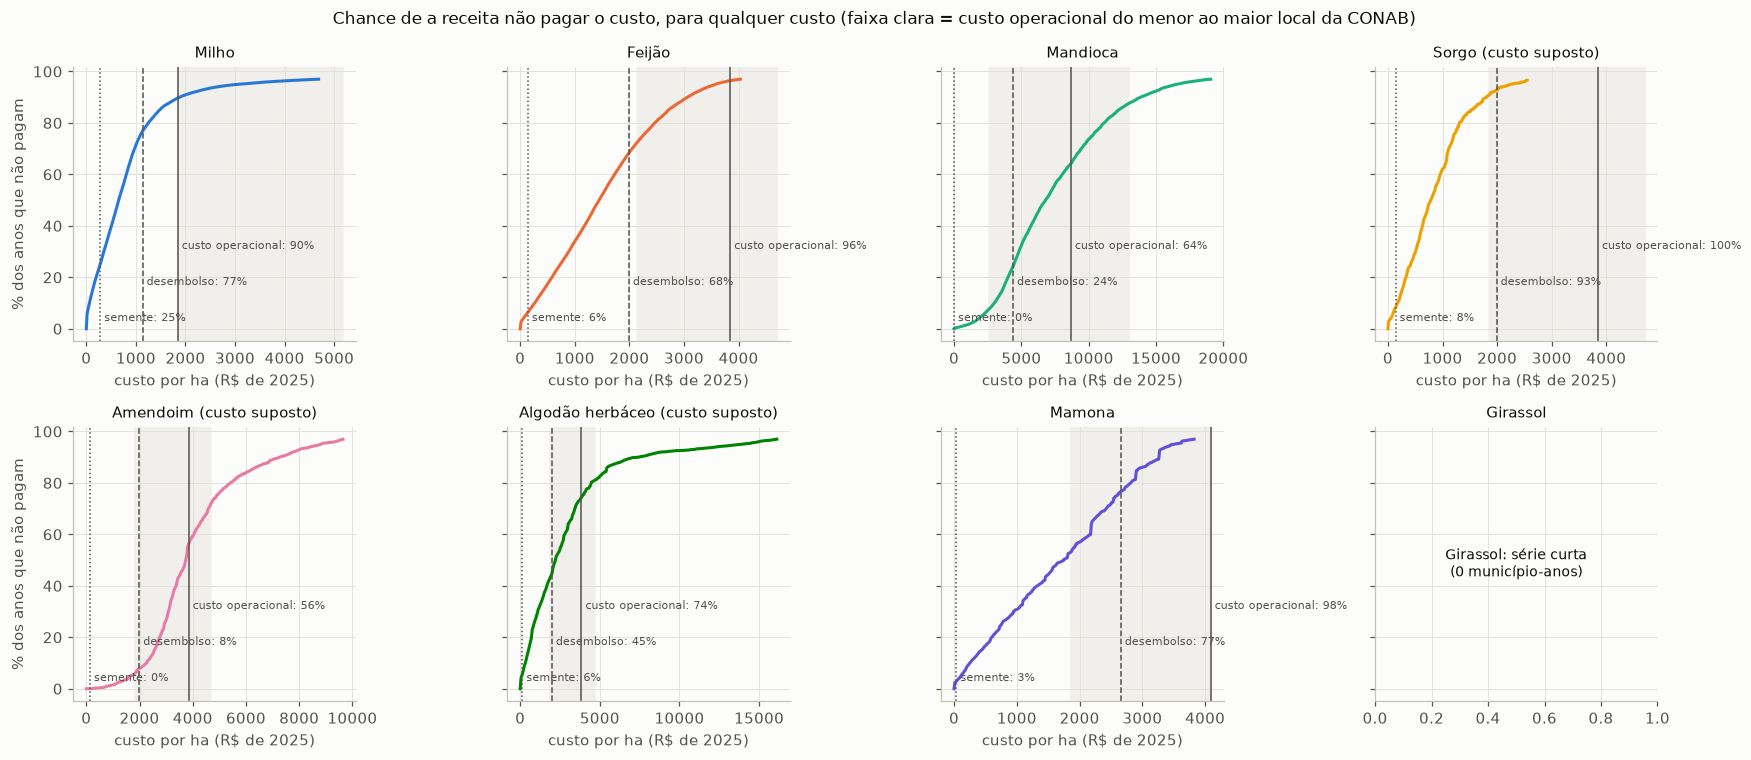

In [15]:
fig, axs = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
for ax, c in zip(axs.flat, CULT):
    r = np.sort(M[M.produto == c].R.dropna().to_numpy())
    if len(r) < 30:
        ax.text(0.5, 0.5, f"{c}: série curta\n({len(r)} município-anos)", ha="center", va="center", transform=ax.transAxes, fontsize=9)
        ax.set_title(c, fontsize=10)
        continue
    x = np.linspace(0, np.quantile(r, 0.97), 300)
    ax.plot(x, np.searchsorted(r, x) / len(r) * 100, color=COR[c])
    for n, ls in zip(NIV, [":", "--", "-"]):
        v = CUSTO.loc[c, n]
        p = np.searchsorted(r, v) / len(r) * 100
        ax.axvline(v, color="#52514e", ls=ls, lw=1)
        ax.text(v, 3 + 14 * NIV.index(n), f" {NOME_NIV[n]}: {p:.0f}%", fontsize=7, color="#52514e")
    ax.axvspan(CUSTO.loc[c, "op_min"], CUSTO.loc[c, "op_max"], color="#f0efec", zorder=0)
    ax.set_title(c + (" (custo suposto)" if CUSTO.loc[c, "origem"].startswith("suposição") else ""), fontsize=10)
    ax.set_xlabel("custo por ha (R$ de 2025)")
axs[0, 0].set_ylabel("% dos anos que não pagam")
axs[1, 0].set_ylabel("% dos anos que não pagam")
fig.suptitle("Chance de a receita não pagar o custo, para qualquer custo (faixa clara = custo operacional do menor ao maior local da CONAB)", fontsize=11)
plt.tight_layout()
plt.show()

### 5.3 Ponto de equilíbrio

- **Rendimento de equilíbrio** = custo ÷ preço de referência do município. Comparado com o rendimento mediano do
  próprio município, diz quantas vezes a lavoura teria de render mais para pagar o custo.
- **Preço de equilíbrio** = custo ÷ rendimento mediano do município. Comparado com o preço de referência, diz quanto o
  preço teria de subir.
- **Produtividade da planilha**: a CONAB calcula o custo para uma produtividade esperada. Se ela for muito maior que a
  do PAM, o custo da planilha é de uma lavoura mais tecnificada que a média.

In [16]:
eq = []
for c in CULT:
    m = mm[(mm.produto == c) & (mm.rend > 0)]
    if not len(m):
        continue
    linha = {"cultura": c, "municípios": len(m), "rendimento mediano (kg/ha)": m.rend.median(), "preço de ref. (R$/kg)": m.preco.median(),
             "produtividade da planilha CONAB (kg/ha)": CUSTO.loc[c, "produtividade_conab"]}
    for n in ["desembolso", "custo_operacional"]:
        k = CUSTO.loc[c, n]
        linha[f"rend. de equilíbrio, {NOME_NIV[n]} (kg/ha)"] = (k / m.preco).median()
        linha[f"× o rendimento mediano ({NOME_NIV[n]})"] = (k / m.preco / m.rend).median()
        linha[f"preço de equilíbrio, {NOME_NIV[n]} (R$/kg)"] = (k / m.rend).median()
    eq.append(linha)
EQ = pd.DataFrame(eq).set_index("cultura")
EQ["planilha ÷ PAM"] = EQ["produtividade da planilha CONAB (kg/ha)"] / EQ["rendimento mediano (kg/ha)"]
display(EQ.round(2))

,municípios,rendimento mediano (kg/ha),preço de ref. (R$/kg),produtividade da planilha CONAB (kg/ha),"rend. de equilíbrio, desembolso (kg/ha)",× o rendimento mediano (desembolso),"preço de equilíbrio, desembolso (R$/kg)","rend. de equilíbrio, custo operacional (kg/ha)",× o rendimento mediano (custo operacional),"preço de equilíbrio, custo operacional (R$/kg)",planilha ÷ PAM
cultura,,,,,,,,,,,
Milho,1690,"533,17","1,21","1.800,00","935,29","1,84","2,13","1.519,17","2,99","3,46","3,38"
Feijão,1693,"309,07","4,53","720,00","439,66","1,41","6,45","849,03","2,73","12,45","2,33"
Mandioca,1528,"9.288,75","0,80","16.000,00","5.493,69","0,57","0,47","10.867,87","1,13","0,93","1,72"
Sorgo,95,"1.060,61","0,72",NaN,"2.759,24","2,41","1,88","5.328,40","4,66","3,63",NaN
Amendoim,165,"1.000,00","3,79",NaN,"525,51","0,53","1,99","1.014,82","1,02","3,85",NaN
Algodão herbáceo,324,"600,00","3,43",NaN,"580,04","0,86","3,32","1.120,12","1,66","6,41",NaN
Mamona,207,"545,00","3,62","1.200,00","732,82","1,35","4,87","1.127,94","2,07","7,50","2,20"


### 5.4 Sensibilidade ao custo

O custo central é um ponto. A figura mostra a fração dos municípios em que a margem mediana fica positiva quando o
custo vai de 0 a 2 vezes o desembolso central (o eixo é o multiplicador). Para as culturas de custo suposto, é a única
leitura honesta.

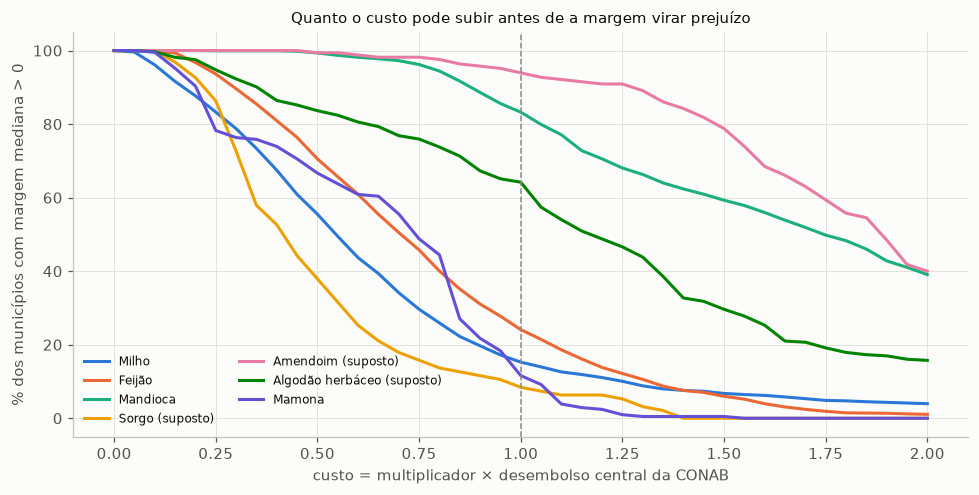

In [17]:
mult = np.linspace(0, 2, 41)
fig, ax = plt.subplots(figsize=(9, 4.6))
for c in CULT:
    m = mm[mm.produto == c]
    if len(m) < 20:
        continue
    k = CUSTO.loc[c, "desembolso"]
    y = [(m.R > k * f).mean() * 100 for f in mult]
    ax.plot(mult, y, color=COR[c], label=c + (" (suposto)" if CUSTO.loc[c, "origem"].startswith("suposição") else ""))
ax.axvline(1, color=CINZA, ls="--", lw=1)
ax.set_xlabel("custo = multiplicador × desembolso central da CONAB")
ax.set_ylabel("% dos municípios com margem mediana > 0")
ax.legend(frameon=False, fontsize=8, ncol=2)
ax.set_title("Quanto o custo pode subir antes de a margem virar prejuízo", fontsize=10)
plt.tight_layout()
plt.show()

### 5.5 Culturas sem preço de mercado na base

Guandu, sorgo forrageiro, milheto, palma forrageira, gliricídia e mucuna-preta não têm série de preço nem de produção no
PAM. O valor delas é **de uso**: forragem que substitui ração ou volumoso comprado, nitrogênio, cobertura do solo.
Não achamos fonte de preço de forragem no NE com série; por isso **o notebook não põe número de receita nelas**. A
única referência lida com custo é Lima et al. (2018a, Rev. Caatinga 31(1):191), em Serra Talhada-PE, irrigado (a lâmina
"0%" recebeu 583 mm): consórcio palma + sorgo de R$ 12.422–12.564/ha contra R$ 11.893–12.034/ha da palma solteira,
com B/C > 1,5 a partir do 2º ano, em reais correntes de 2012–2013 (`pesquisa/viabilidade_artigos_nordeste.md`, grau C).
Não usamos esse número no cálculo: é ensaio único e irrigado.

O que dá para dizer em reais é o **custo de oportunidade**: a forragem numa faixa precisa valer, por hectare, pelo menos
a margem que o caupi ou o milho dariam na mesma faixa. A tabela mostra esse piso.

In [18]:
op = mm[mm.produto.isin(["Feijão", "Milho"])].groupby("produto").agg(
    receita_mediana=("R", "median"), margem_semente_mediana=("marg_semente", "median"),
    margem_desembolso_mediana=("marg_desembolso", "median"))
op["a forragem empata se valer (R$/ha), família que só compra semente"] = op.margem_semente_mediana.clip(lower=0)
op["a forragem empata se valer (R$/ha), desembolso da CONAB"] = op.margem_desembolso_mediana.clip(lower=0)
display(op.round(0))
q_op = mm[(mm.cod_mun == QUIXADA) & mm.produto.isin(["Feijão", "Milho"])].set_index("produto")[["R", "marg_semente", "marg_desembolso"]]
print("Quixadá (mediana 1998–2025):")
display(q_op.round(0))

,receita_mediana,margem_semente_mediana,margem_desembolso_mediana,"a forragem empata se valer (R$/ha), família que só compra semente","a forragem empata se valer (R$/ha), desembolso da CONAB"
produto,,,,,
Feijão,"1.408,00","1.267,00","-584,00","1.267,00","0,00"
Milho,"617,00","333,00","-519,00","333,00","0,00"


Quixadá (mediana 1998–2025):


,R,marg_semente,marg_desembolso
produto,,,
Feijão,"1.506,00","1.364,00","-486,00"
Milho,"651,00","367,00","-485,00"


**Leitura.**
- **Custo da CONAB (R$ de 2025/ha):** feijão familiar de sequeiro, custo operacional central R$ 3.847 (faixa R$ 2.134
  a 4.701), desembolso R$ 1.992 e semente R$ 142. Milho de Crateús-CE: R$ 1.845, R$ 1.136 e R$ 284. Mandioca:
  R$ 8.678, R$ 4.387 e maniva sem custo na maioria das planilhas. Mamona de Irecê-BA: R$ 4.089 e R$ 2.656.
- **A planilha é de uma lavoura melhor que a média:** ela supõe 3,4 vezes o rendimento mediano do PAM no milho, 2,3 no
  feijão, 2,2 na mamona e 1,7 na mandioca.
- **Margem mediana sobre o desembolso:** mandioca +R$ 3.261/ha; amendoim +R$ 1.765 e algodão +R$ 331 (custo
  suposto); milho −R$ 519; feijão −R$ 584; mamona −R$ 683; sorgo −R$ 1.167 (suposto). **Sobre a semente, todas ficam
  positivas:** feijão +R$ 1.267, milho +R$ 333.
- **Chance de não pagar o desembolso** (mediana dos municípios): milho 86% dos anos, mamona 81%, feijão 75%, mandioca
  11%. O custo operacional completo (com a diária) não é pago no ano mediano de milho, feijão, sorgo e mamona; a
  mandioca o paga em 32% dos anos.
- **Ponto de equilíbrio sobre o desembolso:** o feijão precisaria de 440 kg/ha (1,41 vez o mediano) ou de R$ 6,45/kg
  (contra R$ 4,53); o milho, de 935 kg/ha (1,84 vez) ou R$ 2,13/kg (contra R$ 1,21). A mandioca paga o desembolso com
  57% do rendimento mediano.
- **O que isso quer dizer:** o roçado de milho e feijão do sertão **não paga a planilha da CONAB; paga a semente**. Ele
  se sustenta porque a família não paga a própria diária (a CONAB a valoriza em ~R$ 1.855/ha no feijão), não aluga
  máquina e consome boa parte da colheita como comida e forragem.
- **Forragem:** numa faixa, a forragem empata com o caupi se valer pelo menos R$ 1.267/ha para a família que só compra
  semente (R$ 333/ha contra o milho). Sobre o desembolso, qualquer valor positivo já empata, porque caupi e milho dão
  prejuízo na mediana.

## 6. Risco e retorno

Medidas por município e cultura, na receita a preço de referência (R$ de 2025 por ha plantado, 1998–2025):
- **média** e **CV** (desvio-padrão ÷ média);
- **pior ano em 10** = P10 da série do município; **CVaR10** = média dos anos abaixo do P10 (os ~3 piores de 28);
- **chance de não pagar o desembolso** (seção 5).

Depois, a mesma receita em dois grupos de anos que importam para 2027: os **El Niños fortes** (ONI de OND–NDJ ≥ 1,5:
quadras de 1998, 2010, 2016 e 2024) e a **seca longa de 2012–2016**. Por fim, a "fronteira": a média contra o pior
decil, cultura a cultura.

In [19]:
def cvar10(s):
    s = s.dropna()
    return s[s <= s.quantile(0.1)].mean()


RR = M.groupby(["produto", "cod_mun"]).agg(
    media=("R", "mean"), mediana=("R", "median"), dp=("R", "std"), p10=("R", lambda s: s.quantile(0.1)), cvar10=("R", cvar10),
    falha_des=("falha_desembolso", "mean"), anos=("R", "size")).reset_index()
RR["cv"] = RR.dp / RR.media
RR["p10_rel"] = RR.p10 / RR.mediana
RR["cvar10_rel"] = RR.cvar10 / RR.mediana
risco = RR.groupby("produto").agg(municipios=("cod_mun", "size"), media=("media", "median"), mediana=("mediana", "median"),
                                  cv=("cv", "median"), p10=("p10", "median"), cvar10=("cvar10", "median"),
                                  p10_rel=("p10_rel", "median"), cvar10_rel=("cvar10_rel", "median"),
                                  nao_paga_desembolso_pct=("falha_des", lambda s: s.median() * 100)).reindex(CULT).dropna(how="all")
risco["municipios"] = risco.municipios.astype(int)
print("Risco e retorno por cultura (mediana entre os municípios com série; R$ de 2025 por ha plantado)")
display(risco.round(2))

# o preço protege? CV da receita observada (com o preço do ano) contra a receita a preço fixo, mesmos anos 2010–2025
pp = M[M.ano.between(2010, 2025)].dropna(subset=["R_obs"]).groupby(["produto", "cod_mun"]).filter(lambda g: len(g) >= 10)
cvp = pp.groupby(["produto", "cod_mun"]).agg(cv_fixo=("R", lambda s: s.std() / s.mean()), cv_obs=("R_obs", lambda s: s.std() / s.mean())).groupby("produto").median().reindex(CULT).dropna()
cvp["o preço do ano muda o CV em"] = cvp.cv_obs - cvp.cv_fixo
print("CV da receita, 2010–2025: a preço fixo (só clima) e observada (clima + preço do ano)")
display(cvp.round(3))

Risco e retorno por cultura (mediana entre os municípios com série; R$ de 2025 por ha plantado)


,municipios,media,mediana,cv,p10,cvar10,p10_rel,cvar10_rel,nao_paga_desembolso_pct
produto,,,,,,,,,
Milho,1690,"678,38","616,79","0,73","176,36","97,99","0,27","0,14","85,71"
Feijão,1693,"1.474,18","1.408,49","0,54","544,63","351,63","0,40","0,24","75,00"
Mandioca,1528,"7.476,42","7.648,08","0,30","4.470,60","3.344,75","0,62","0,47","10,71"
Sorgo,95,"802,23","825,42","0,53","295,52","181,43","0,40","0,26","100,00"
Amendoim,165,"3.900,31","3.757,01","0,25","2.922,71","2.624,00","0,83","0,73","0,00"
Algodão herbáceo,324,"2.268,73","2.323,51","0,58","588,90","317,30","0,31","0,16","40,00"
Mamona,207,"1.877,44","1.973,86","0,54","531,94","255,98","0,31","0,18","81,48"


CV da receita, 2010–2025: a preço fixo (só clima) e observada (clima + preço do ano)


,cv_fixo,cv_obs,o preço do ano muda o CV em
produto,,,
Milho,"0,73","0,79","0,06"
Feijão,"0,58","0,62","0,04"
Mandioca,"0,30","0,45","0,14"
Sorgo,"0,58","0,64","0,06"
Amendoim,"0,25","0,50","0,26"
Algodão herbáceo,"0,48","0,57","0,09"
Mamona,"0,51","0,60","0,09"


Receita (R$ de 2025/ha plantado, mediana dos município-anos) e risco por grupo de anos


,"receita, demais anos","receita, El Niño forte","receita, seca 2012–16","razão ao normal, El Niño forte","razão ao normal, seca","quebra %, demais","quebra %, El Niño forte","quebra %, seca","não paga desembolso %, demais","não paga desembolso %, El Niño forte"
Milho,"728,96","425,24","406,67","0,75","0,71","16,58","39,03","41,34","74,83","81,92"
Feijão,"1.560,14","1.050,47","1.085,41","0,82","0,86","13,08","31,75","31,98","65,66","76,72"
Mandioca,"7.009,83","6.391,99","6.064,06","1,00","0,98","7,00","12,19","16,46","22,19","28,58"
Sorgo,"865,52","692,51","350,02","0,96","0,52","9,04","28,64","50,41","91,04","97,27"
Amendoim,"3.787,63","3.618,18","3.401,83","1,00","1,00","2,25","4,89","9,74","6,66","7,87"
Algodão herbáceo,"2.424,87","1.123,42","1.110,78","0,71","0,53","16,03","41,52","48,79","40,65","60,26"
Mamona,"1.913,25","1.510,42","652,50","0,88","0,48","11,66","28,13","52,32","73,08","83,62"


Razão ao normal da receita, mediana dos municípios, em cada El Niño forte


produto,Feijão,Mandioca,Milho
ano,,,
1998,"0,61","0,84","0,38"
2010,"0,94","1,00","0,80"
2016,"0,57","0,96","0,47"
2024,"1,00","1,00","1,27"


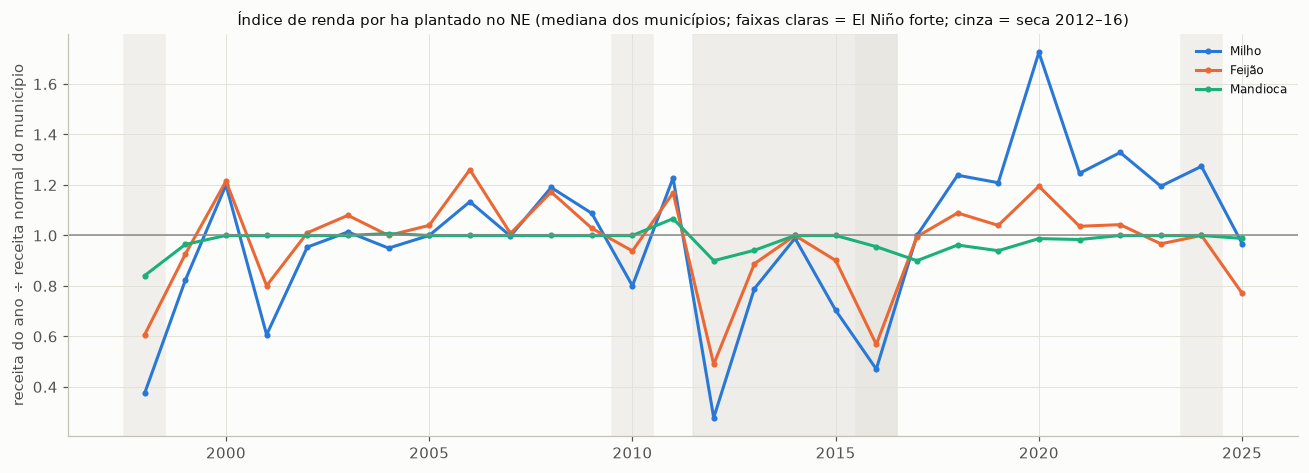

In [20]:
def grupo(a):
    return "El Niño forte" if a in EN_FORTE else ("seca 2012–16" if a in SECA else "demais anos")


M["grupo"] = M.ano.map(grupo)
M["R_rel"] = M.R / M.groupby(["produto", "cod_mun"]).R.transform("median")
eg = M.groupby(["produto", "grupo"]).agg(R=("R", "median"), R_rel=("R_rel", "median"), quebra=("quebra", "mean"),
                                         nao_paga=("falha_desembolso", "mean")).unstack()
lin = {}
for c in CULT:
    if c not in eg.index:
        continue
    e = eg.loc[c]
    lin[c] = {"receita, demais anos": e[("R", "demais anos")], "receita, El Niño forte": e[("R", "El Niño forte")],
              "receita, seca 2012–16": e[("R", "seca 2012–16")],
              "razão ao normal, El Niño forte": e[("R_rel", "El Niño forte")], "razão ao normal, seca": e[("R_rel", "seca 2012–16")],
              "quebra %, demais": e[("quebra", "demais anos")] * 100, "quebra %, El Niño forte": e[("quebra", "El Niño forte")] * 100,
              "quebra %, seca": e[("quebra", "seca 2012–16")] * 100,
              "não paga desembolso %, demais": e[("nao_paga", "demais anos")] * 100,
              "não paga desembolso %, El Niño forte": e[("nao_paga", "El Niño forte")] * 100}
EN = pd.DataFrame(lin).T
print("Receita (R$ de 2025/ha plantado, mediana dos município-anos) e risco por grupo de anos")
display(EN.round(2))
pa = M[M.produto.isin(["Milho", "Feijão", "Mandioca"]) & M.ano.isin(EN_FORTE)].groupby(["ano", "produto"]).R_rel.median().unstack()
print("Razão ao normal da receita, mediana dos municípios, em cada El Niño forte")
display(pa.round(2))

fig, ax = plt.subplots(figsize=(12, 4.4))
ix = M[M.produto.isin(["Milho", "Feijão", "Mandioca"])].groupby(["ano", "produto"]).R_rel.median().unstack()
for c in ["Milho", "Feijão", "Mandioca"]:
    ax.plot(ix.index, ix[c], color=COR[c], marker="o", ms=3, label=c)
for a in EN_FORTE:
    ax.axvspan(a - 0.5, a + 0.5, color="#f0efec", zorder=0)
ax.axvspan(SECA[0] - 0.5, SECA[-1] + 0.5, color="#e1e0d9", alpha=0.5, zorder=0)
ax.axhline(1, color=CINZA, lw=1)
ax.set_ylabel("receita do ano ÷ receita normal do município")
ax.set_title("Índice de renda por ha plantado no NE (mediana dos municípios; faixas claras = El Niño forte; cinza = seca 2012–16)", fontsize=10)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

### 6.1 A fronteira: retorno médio contra o pior decil

Cada ponto é uma cultura (mediana entre os municípios). Mais à direita, mais receita média; mais acima, mais receita no
pior ano em 10 (CVaR10). Como as culturas existem em municípios diferentes, o painel da direita repete a conta só nos
municípios que têm as três culturas principais, para comparar o mesmo chão.

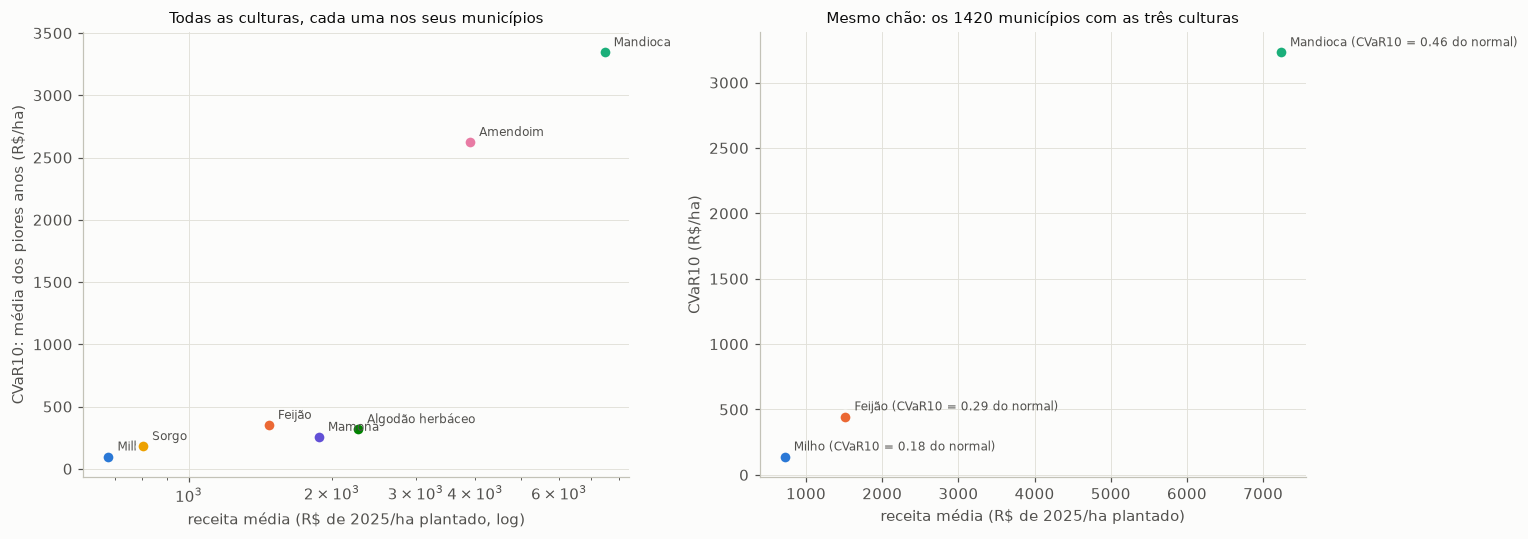

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for c in risco.index:
    r = risco.loc[c]
    axs[0].scatter(r.media, r.cvar10, s=70, color=COR[c], edgecolor="#fcfcfb", lw=2, zorder=3)
    axs[0].annotate(c, (r.media, r.cvar10), xytext=(6, 4), textcoords="offset points", fontsize=8, color="#52514e")
axs[0].set_xscale("log")
axs[0].set_xlabel("receita média (R$ de 2025/ha plantado, log)")
axs[0].set_ylabel("CVaR10: média dos piores anos (R$/ha)")
axs[0].set_title("Todas as culturas, cada uma nos seus municípios", fontsize=10)
tres = set.intersection(*[set(RR[RR.produto == c].cod_mun) for c in ["Milho", "Feijão", "Mandioca"]])
r3 = RR[RR.cod_mun.isin(tres)].groupby("produto")[["media", "cvar10", "cvar10_rel"]].median()
for c in ["Milho", "Feijão", "Mandioca"]:
    axs[1].scatter(r3.loc[c, "media"], r3.loc[c, "cvar10"], s=70, color=COR[c], edgecolor="#fcfcfb", lw=2, zorder=3)
    axs[1].annotate(f"{c} (CVaR10 = {r3.loc[c, 'cvar10_rel']:.2f} do normal)", (r3.loc[c, "media"], r3.loc[c, "cvar10"]),
                    xytext=(6, 4), textcoords="offset points", fontsize=8, color="#52514e")
axs[1].set_xlabel("receita média (R$ de 2025/ha plantado)")
axs[1].set_ylabel("CVaR10 (R$/ha)")
axs[1].set_title(f"Mesmo chão: os {len(tres)} municípios com as três culturas", fontsize=10)
plt.tight_layout()
plt.show()
TRES = sorted(tres)

**Leitura.**
- **CV da receita:** milho 0,73; algodão 0,58; feijão e mamona 0,54; sorgo 0,53; mandioca 0,30; amendoim 0,25.
- **Pior decil (CVaR10) ÷ mediana:** milho 0,14; algodão 0,16; mamona 0,18; feijão 0,24; sorgo 0,26; **mandioca
  0,47**; amendoim 0,73 (com o viés do relato da seção 2).
- **O preço do ano não reduz o risco:** a receita observada tem CV maior que a de preço fixo em todas as culturas
  (+0,04 no feijão a +0,26 no amendoim).
- **El Niño forte (1998, 2010, 2016, 2024):** a receita mediana do milho cai de R$ 729 para R$ 425/ha (razão ao normal
  0,75); a quebra do milho sobe de 17% para 39% dos município-anos; a do feijão, de 13% para 32%; a do algodão, de 16%
  para 42%. A mandioca fica em 1,00 do normal, com quebra de 7% para 12%.
- **Ano a ano:** o milho ficou em 0,38 do normal em 1998, 0,47 em 2016, 0,80 em 2010 e **1,27 em 2024**; o feijão em
  0,61, 0,57, 0,94 e 1,00; a mandioca em 0,84, 0,96, 1,00 e 1,00. O El Niño forte aumenta a chance de perda, mas não é
  sentença: 2024 foi bom.
- **Seca de 2012–2015** (2016 conta como El Niño): milho 0,71 do normal, feijão 0,86, mandioca 0,98, sorgo 0,52,
  algodão 0,53, mamona 0,48.
- **Chance de não pagar o desembolso em El Niño forte:** milho 82%, mamona 84%, feijão 77%, algodão 60%, mandioca 29%.
- **Fronteira:** nos 1.420 municípios com as três culturas, a mandioca tem mais receita média e mais receita no pior
  decil que o milho e o feijão. Não há troca entre retorno e risco: a mandioca ganha nos dois eixos.

## 7. Diversificação: correlação entre culturas e carteiras em R$/ha

**Correlação.** Para cada par de culturas e cada município com ≥ 10 anos em comum, a correlação de Spearman entre as
receitas por ha dos dois (a preço de referência, 1998–2025). A tabela é a mediana entre os municípios. Correlação
baixa ou negativa = uma cultura segura a outra no ano ruim.

**Carteiras** (áreas iguais; receita da carteira = média das receitas por ha):
- **S0**: ½ milho + ½ feijão (o consórcio de hoje, na convenção da proposta);
- **1/3**: milho, feijão e mandioca, a mandioca colhida todo ano (a conta da proposta, seção M4);
- **1/3, mandioca a cada 2 quadras**: o terço de mandioca só colhe um ano sim, outro não (ciclo de 18 meses, como no
  plano). Por ano, rende metade;
- **Faixas do plano** (regime permanente da seção 6.4 da proposta): a cada ano, uma faixa colhe mandioca, uma recebe
  maniva nova (sem receita no ano) e uma tem caupi. Por ha de faixa: (mandioca + caupi + 0) ÷ 3;
- **Plano da família**: 2/3 da área em faixas e 1/3 em baixio com milho + caupi (como a S0).

Primeiro, a conferência: refazemos a conta da proposta em razão ao normal (CE, área plantada ≥ 50 ha) para ver se
saem os mesmos 0,26 → 0,36. Depois, a mesma conta em reais.

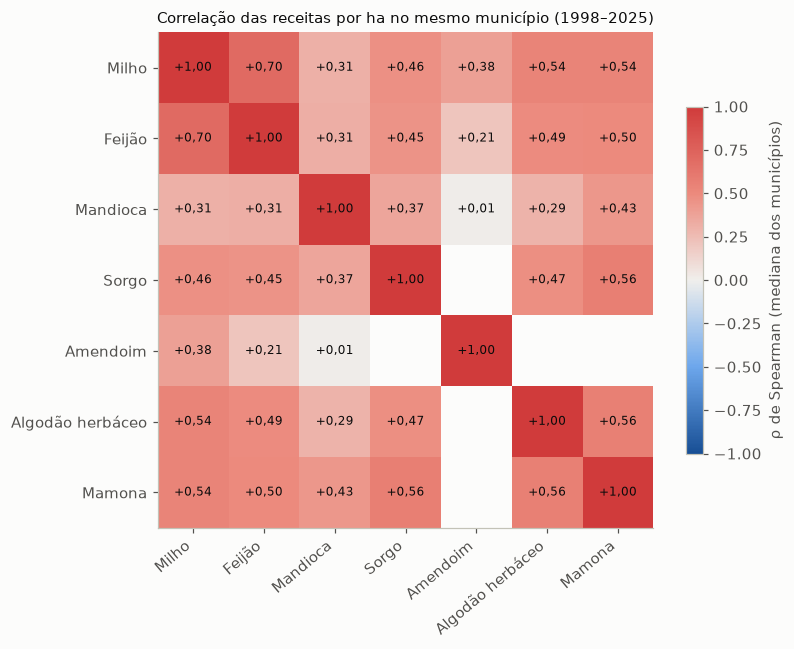

Correlação (mediana dos municípios) e número de municípios por par:


,Milho,Feijão,Mandioca,Sorgo,Amendoim,Algodão herbáceo,Mamona
Milho,"1,00","0,70","0,31","0,46","0,38","0,54","0,54"
Feijão,"0,70","1,00","0,31","0,45","0,21","0,49","0,50"
Mandioca,"0,31","0,31","1,00","0,37","0,01","0,29","0,43"
Sorgo,"0,46","0,45","0,37","1,00",NaN,"0,47","0,56"
Amendoim,"0,38","0,21","0,01",NaN,"1,00",NaN,NaN
Algodão herbáceo,"0,54","0,49","0,29","0,47",NaN,"1,00","0,56"
Mamona,"0,54","0,50","0,43","0,56",NaN,"0,56","1,00"


,Milho,Feijão,Mandioca,Sorgo,Amendoim,Algodão herbáceo,Mamona
Milho,0,1667,1431,91,161,321,204
Feijão,1667,0,1434,93,158,324,205
Mandioca,1431,1434,0,83,160,211,194
Sorgo,91,93,83,0,0,41,43
Amendoim,161,158,160,0,0,0,0
Algodão herbáceo,321,324,211,41,0,0,53
Mamona,204,205,194,43,0,53,0


In [22]:
W = M.pivot_table(index=["cod_mun", "ano"], columns="produto", values="R")
cults = [c for c in CULT if c in W.columns and W[c].notna().sum() > 500]
COR_M = pd.DataFrame(np.nan, index=cults, columns=cults)
N_M = pd.DataFrame(0, index=cults, columns=cults)
for i, a in enumerate(cults):
    COR_M.loc[a, a] = 1
    for b in cults[i + 1:]:
        sub = W[[a, b]].dropna()
        rh = sub.groupby(level=0).apply(lambda d: d[a].corr(d[b], method="spearman") if len(d) >= 10 else np.nan).dropna()
        if len(rh) >= 20:
            COR_M.loc[a, b] = COR_M.loc[b, a] = rh.median()
            N_M.loc[a, b] = N_M.loc[b, a] = len(rh)
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(COR_M.to_numpy(dtype=float), cmap=DIV.reversed(), vmin=-1, vmax=1)
for i in range(len(cults)):
    for j in range(len(cults)):
        v = COR_M.iloc[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:+.2f}".replace(".", ","), ha="center", va="center", fontsize=8, color="#0b0b0b")
ax.set_xticks(range(len(cults)), cults, rotation=40, ha="right")
ax.set_yticks(range(len(cults)), cults)
ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.7, label="ρ de Spearman (mediana dos municípios)")
ax.set_title("Correlação das receitas por ha no mesmo município (1998–2025)", fontsize=10)
plt.tight_layout()
plt.show()
print("Correlação (mediana dos municípios) e número de municípios por par:")
display(COR_M.round(2))
display(N_M)

In [23]:
# conferência com a proposta (definição canônica b: CE, produção ÷ área plantada ≥ 50 ha, razão à mediana dos outros anos)
Q = P[(P.uf == "CE") & (P.area_plantada_ha >= 50) & P.produto.isin(["Milho", "Feijão", "Mandioca"])].copy()
Q["razao"] = Q.rend_plantado_kg_ha / Q.groupby(["cod_mun", "produto"]).rend_plantado_kg_ha.transform(mediana_outros)
YQ = Q.pivot_table(index=["cod_mun", "ano"], columns="produto", values="razao").dropna()


def metr(s):
    s = s.dropna()
    return pd.Series({"CVaR10 (razão)": s[s <= s.quantile(0.1)].mean(), "P(< 0,5) %": (s < 0.5).mean() * 100, "n": len(s)})


conf_c = pd.DataFrame({"100% milho": metr(YQ.Milho), "S0: milho + feijão": metr(YQ[["Milho", "Feijão"]].mean(axis=1)),
                       "1/3 com mandioca": metr(YQ.mean(axis=1))}).T
print("Conferência (CE, 1998–2025). Proposta: 0,15 / 0,26 / 0,36 e 21% / 15% / 11% (2.495 município-anos)")
conf_c["n"] = conf_c.n.astype(int)
display(conf_c.round(3))

Conferência (CE, 1998–2025). Proposta: 0,15 / 0,26 / 0,36 e 21% / 15% / 11% (2.495 município-anos)


,CVaR10 (razão),"P(< 0,5) %",n
100% milho,"0,15","21,08",2495
S0: milho + feijão,"0,26","14,63",2495
1/3 com mandioca,"0,36","10,78",2495


In [24]:
# carteiras em R$ nos municípios com as três culturas (seção 6), anos em que as três existem
T3 = W.loc[W.index.get_level_values(0).isin(TRES), ["Milho", "Feijão", "Mandioca"]].dropna()
CART = pd.DataFrame({
    "100% milho": T3.Milho, "100% feijão": T3.Feijão, "100% mandioca": T3.Mandioca,
    "S0: ½ milho + ½ feijão": (T3.Milho + T3.Feijão) / 2,
    "1/3 (mandioca todo ano)": T3.mean(axis=1),
    "1/3 (mandioca a cada 2 quadras)": (T3.Milho + T3.Feijão + T3.Mandioca / 2) / 3,
    "Faixas do plano": (T3.Mandioca + T3.Feijão) / 3,
    "Plano da família (2/3 faixas + 1/3 baixio)": 2 / 3 * (T3.Mandioca + T3.Feijão) / 3 + 1 / 3 * (T3.Milho + T3.Feijão) / 2,
})
K = CUSTO.desembolso
K_CART = {"100% milho": K.Milho, "100% feijão": K.Feijão, "100% mandioca": K.Mandioca, "S0: ½ milho + ½ feijão": (K.Milho + K.Feijão) / 2,
          "1/3 (mandioca todo ano)": (K.Milho + K.Feijão + K.Mandioca) / 3, "1/3 (mandioca a cada 2 quadras)": (K.Milho + K.Feijão + K.Mandioca / 2) / 3,
          "Faixas do plano": (K.Mandioca + K.Feijão) / 3, "Plano da família (2/3 faixas + 1/3 baixio)": 2 / 3 * (K.Mandioca + K.Feijão) / 3 + 1 / 3 * (K.Milho + K.Feijão) / 2}
KS = CUSTO.semente
KS_CART = {k: v for k, v in zip(K_CART, [KS.Milho, KS.Feijão, KS.Mandioca, (KS.Milho + KS.Feijão) / 2, (KS.Milho + KS.Feijão + KS.Mandioca) / 3,
                                         (KS.Milho + KS.Feijão + KS.Mandioca / 2) / 3, (KS.Mandioca + KS.Feijão) / 3,
                                         2 / 3 * (KS.Mandioca + KS.Feijão) / 3 + 1 / 3 * (KS.Milho + KS.Feijão) / 2])}


def resumo_cart(X, kc=K_CART, ks=KS_CART):
    out = {}
    en = X.index.get_level_values(1).isin(EN_FORTE)
    for c in X.columns:
        s = X[c]
        rel = s / s.groupby(level=0).transform(mediana_outros)
        por_mun = s.groupby(level=0).agg(["mean", cvar10])
        out[c] = {"receita média (R$/ha)": por_mun["mean"].median(), "CVaR10 (R$/ha)": por_mun["cvar10"].median(),
                  "CVaR10 (razão)": rel[rel <= rel.quantile(0.1)].mean(), "P(< 0,5 do normal) %": (rel < 0.5).mean() * 100,
                  "razão mediana, El Niño forte": rel[en].median(), "não paga a semente %": (s < ks[c]).mean() * 100,
                  "não paga o desembolso %": (s < kc[c]).mean() * 100,
                  "não paga o desembolso %, El Niño forte": (s[en] < kc[c]).mean() * 100}
    return pd.DataFrame(out).T


RC = resumo_cart(CART)
print(f"Carteiras em R$ de 2025 (preço de referência), {T3.index.get_level_values(0).nunique()} municípios, {len(T3)} município-anos")
display(RC.round(2))

Carteiras em R$ de 2025 (preço de referência), 1420 municípios, 34895 município-anos


,receita média (R$/ha),CVaR10 (R$/ha),CVaR10 (razão),"P(< 0,5 do normal) %","razão mediana, El Niño forte",não paga a semente %,não paga o desembolso %,"não paga o desembolso %, El Niño forte"
100% milho,"715,97","145,65","0,09","20,37","0,79","21,19","75,50","79,48"
100% feijão,"1.547,89","453,75","0,16","15,59","0,84","4,29","66,79","74,55"
100% mandioca,"7.240,54","3.337,52","0,34","8,69","0,98","0,00","26,00","31,44"
S0: ½ milho + ½ feijão,"1.158,85","351,00","0,16","16,01","0,82","7,82","67,83","74,88"
1/3 (mandioca todo ano),"3.306,89","1.584,31","0,37","7,78","0,93","0,36","35,60","43,80"
1/3 (mandioca a cada 2 quadras),"2.029,93","963,75","0,37","8,02","0,91","0,52","42,43","51,80"
Faixas do plano,"2.962,24","1.431,23","0,37","7,88","0,94","0,22","33,66","40,94"
Plano da família (2/3 faixas + 1/3 baixio),"2.405,46","1.155,03","0,38","7,64","0,92","0,36","38,78","47,55"


**Placebo e piso, em reais.** O placebo da proposta troca o terço de mandioca pelo **feijão de um dos 5 municípios
vizinhos mais próximos**, no mesmo ano: é só "mais uma série com ruído independente". Se o placebo já dá quase o mesmo
ganho, a parte própria da mandioca é pequena. O piso conta como perda total (receita 0) os anos em que a mandioca
sumiu do município (menos de 10 ha), justo os anos secos em que a maniva falta.

In [25]:
pts = MUN_NE.set_index("cod").geometry.representative_point()
xy = np.c_[pts.x, pts.y]
cods = pts.index.to_numpy()
d2 = ((xy[:, None, :] - xy[None, :, :]) ** 2).sum(-1)
np.fill_diagonal(d2, np.inf)
VIZ = {c: cods[np.argsort(d2[i])[:5]] for i, c in enumerate(cods)}
Wf = W["Feijão"].dropna()
Wfr = (Wf / Wf.groupby(level=0).transform(mediana_outros))
rng = np.random.default_rng(14)


def placebo(T, base, sorteios=50):
    """CVaR10 da carteira 1/3 com o feijão de um vizinho (sorteado entre os 5 mais próximos, mesmo ano) no lugar da mandioca."""
    fv = base.to_dict()
    opcoes = [[o for o in (fv.get((v, a)) for v in VIZ.get(c, [])) if o is not None and not np.isnan(o)] for (c, a) in T.index]
    tem = np.array([len(o) > 0 for o in opcoes])
    resto = T.drop(columns="Mandioca").to_numpy()[tem]
    opcoes = [o for o in opcoes if o]
    res = []
    for _ in range(sorteios):
        viz = np.array([o[rng.integers(len(o))] for o in opcoes])
        s = np.c_[resto, viz].mean(axis=1)
        s = s[~np.isnan(s)]
        res.append(s[s <= np.quantile(s, 0.1)].mean())
    return np.mean(res), np.quantile(res, 0.05), np.quantile(res, 0.95)


TR = T3 / T3.groupby(level=0).transform(mediana_outros)
pl_r = placebo(TR, Wfr)
s13 = TR.mean(axis=1)
s0 = TR[["Milho", "Feijão"]].mean(axis=1)
print(f"Razão ao normal (NE, {len(TR)} município-anos): S0 {num(s0[s0 <= s0.quantile(.1)].mean(), 3)} | 1/3 {num(s13[s13 <= s13.quantile(.1)].mean(), 3)} | "
      f"placebo do vizinho {num(pl_r[0], 3)} (90% dos sorteios: {num(pl_r[1], 3)}–{num(pl_r[2], 3)})")
YR = YQ.copy()
Qf = Q[Q.produto == "Feijão"].set_index(["cod_mun", "ano"]).razao
pl_ce = placebo(YR, Qf)
print(f"Conferência no CE (proposta: placebo 0,335, faixa 0,323–0,347): {num(pl_ce[0], 3)} ({num(pl_ce[1], 3)}–{num(pl_ce[2], 3)})")

# piso: anos sem mandioca contam como perda total
Wall = W.loc[W.index.get_level_values(0).isin(TRES), ["Milho", "Feijão", "Mandioca"]].dropna(subset=["Milho", "Feijão"])
falta = Wall.Mandioca.isna()
def razao_piso(s):
    """Razão ao normal; o normal é a mediana dos outros anos COM mandioca; ano sem mandioca = 0."""
    v = s.to_numpy()
    tem = ~np.isnan(v)
    out = []
    for i in range(len(v)):
        outros = v[tem & (np.arange(len(v)) != i)]
        out.append(0.0 if not tem[i] else (v[i] / np.median(outros) if len(outros) else np.nan))
    return pd.Series(out, index=s.index)


rel_p = pd.DataFrame({"Milho": Wall.Milho / Wall.Milho.groupby(level=0).transform(mediana_outros),
                      "Feijão": Wall.Feijão / Wall.Feijão.groupby(level=0).transform(mediana_outros),
                      "Mandioca": Wall.Mandioca.groupby(level=0).transform(razao_piso)})
s_piso = rel_p.mean(axis=1)
print(f"Piso: {num(falta.mean() * 100, 1)}% dos município-anos sem mandioca; CVaR10 (razão) da 1/3 contando esses anos como zero = "
      f"{num(s_piso[s_piso <= s_piso.quantile(.1)].mean(), 3)}")
pl_rs = placebo(T3, Wf)
s13r = T3.mean(axis=1)
s0r = ((T3.Milho + T3.Feijão) / 2)
print(f"Em R$ por ha (CVaR10 agrupado dos município-anos): S0 {brl(s0r[s0r <= s0r.quantile(.1)].mean())} | 1/3 {brl(s13r[s13r <= s13r.quantile(.1)].mean())} | "
      f"placebo {brl(pl_rs[0])} ({brl(pl_rs[1])}–{brl(pl_rs[2])})")

Razão ao normal (NE, 34895 município-anos): S0 0,165 | 1/3 0,321 | placebo do vizinho 0,229 (90% dos sorteios: 0,227–0,230)


Conferência no CE (proposta: placebo 0,335, faixa 0,323–0,347): 0,325 (0,318–0,331)


Piso: 6,8% dos município-anos sem mandioca; CVaR10 (razão) da 1/3 contando esses anos como zero = 0,260


Em R$ por ha (CVaR10 agrupado dos município-anos): S0 R$ 127 | 1/3 R$ 956 | placebo R$ 198 (R$ 195–R$ 200)


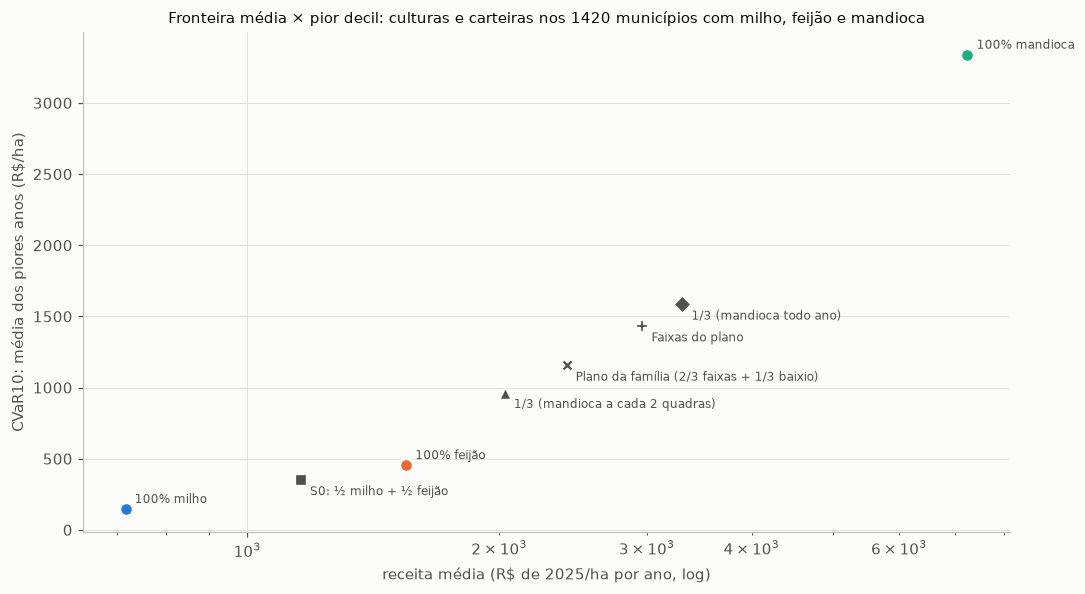

In [26]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for c in ["Milho", "Feijão", "Mandioca"]:
    r = RC.loc[f"100% {c.lower()}"]
    ax.scatter(r["receita média (R$/ha)"], r["CVaR10 (R$/ha)"], s=80, color=COR[c], edgecolor="#fcfcfb", lw=2, zorder=3)
    ax.annotate(f"100% {c.lower()}", (r["receita média (R$/ha)"], r["CVaR10 (R$/ha)"]), xytext=(6, 4), textcoords="offset points", fontsize=8, color="#52514e")
for k, mk in zip([c for c in RC.index if not c.startswith("100%")], ["s", "D", "^", "P", "X"]):
    r = RC.loc[k]
    ax.scatter(r["receita média (R$/ha)"], r["CVaR10 (R$/ha)"], s=70, marker=mk, color="#52514e", edgecolor="#fcfcfb", lw=1.5, zorder=3)
    ax.annotate(k, (r["receita média (R$/ha)"], r["CVaR10 (R$/ha)"]), xytext=(6, -10), textcoords="offset points", fontsize=8, color="#52514e")
ax.set_xscale("log")
ax.set_xlabel("receita média (R$ de 2025/ha por ano, log)")
ax.set_ylabel("CVaR10: média dos piores anos (R$/ha)")
ax.set_title(f"Fronteira média × pior decil: culturas e carteiras nos {len(TRES)} municípios com milho, feijão e mandioca", fontsize=10)
plt.tight_layout()
plt.show()

In [27]:
# a mesma comparação com a receita observada (preço do ano), 2010–2025
Wo = M[M.ano.between(2010, 2025)].pivot_table(index=["cod_mun", "ano"], columns="produto", values="R_obs")
T3o = Wo.loc[Wo.index.get_level_values(0).isin(TRES), ["Milho", "Feijão", "Mandioca"]].dropna()
CO = pd.DataFrame({"S0: ½ milho + ½ feijão": (T3o.Milho + T3o.Feijão) / 2, "1/3 (mandioca todo ano)": T3o.mean(axis=1),
                   "Faixas do plano": (T3o.Mandioca + T3o.Feijão) / 3})
print(f"Receita observada (com o preço do ano), 2010–2025, {len(T3o)} município-anos")
display(resumo_cart(CO).round(2))

Receita observada (com o preço do ano), 2010–2025, 18804 município-anos


,receita média (R$/ha),CVaR10 (R$/ha),CVaR10 (razão),"P(< 0,5 do normal) %","razão mediana, El Niño forte",não paga a semente %,não paga o desembolso %,"não paga o desembolso %, El Niño forte"
S0: ½ milho + ½ feijão,"1.109,29","363,24","0,16","16,42","0,96","10,38","69,54","70,76"
1/3 (mandioca todo ano),"2.843,56","1.338,86","0,32","10,64","0,95","0,65","47,33","51,32"
Faixas do plano,"2.467,76","1.191,93","0,32","10,28","0,96","0,30","46,54","49,83"


**Leitura.**
- **Correlação mediana no mesmo município:** milho × feijão **+0,70** (quebram juntos); milho × mandioca e feijão ×
  mandioca +0,31; mandioca × amendoim +0,01. Todas são positivas: nenhuma cultura do PAM é seguro natural de outra, mas
  a mandioca e o amendoim são as menos ligadas ao roçado.
- **Conferência:** a conta da proposta sai igual: pior ano em 10 de **0,15 / 0,26 / 0,36** e P(< 0,5) de 21% / 15% /
  11%, nos mesmos 2.495 município-anos do CE.
- **Placebo:** no CE, o feijão do vizinho no lugar da mandioca dá 0,325 (0,318–0,331), perto dos 0,335 da proposta; a
  parte própria da mandioca fica em ~+0,035. No NE (34.895 município-anos): S0 0,165, carteira 1/3 0,321, placebo
  0,229; parte própria ~+0,09. **Piso** (ano sem mandioca = perda total; 6,8% dos município-anos): 0,260, ainda acima
  da S0.
- **Em reais, o ganho é de nível, não só de diversificação.** A carteira 1/3 rende R$ 3.307/ha por ano, contra R$ 1.159
  da S0, e o pior decil sobe de R$ 351 para R$ 1.584/ha. No pior decil agrupado, a S0 fica em R$ 127/ha; a carteira
  com o feijão do vizinho no lugar da mandioca, em R$ 198; com a mandioca, em R$ 956. Quase todo o ganho vem da
  receita alta da mandioca (R$ 7.241/ha).
- **Ciclo:** se o terço de mandioca só colhe a cada 2 quadras, a carteira rende R$ 2.030/ha e o pior decil cai para
  R$ 964/ha; ainda 2,7 vezes a S0.
- **Faixas do plano:** R$ 2.962/ha por ano, pior decil R$ 1.431. **Plano da família** (com o baixio): R$ 2.405 e
  R$ 1.155. Chance de não pagar o desembolso: 39% dos município-anos, contra 68% da S0; em El Niño forte, 48% contra 75%.
- **Com o preço do ano** (2010–2025), a vantagem continua: pior ano em 10 de 0,16 (S0) para 0,32 (1/3); chance de não
  pagar o desembolso de 70% para 47%.

## 8. Rotação em reais: o bônus da leguminosa e o cenário honesto

Dois cartões do catálogo de rotações (`pesquisa/catalogo_rotacoes_comprovadas.md`) viram dinheiro aqui:
- **`ne_lg_cereal_sequeiro_quente`**: caupi (ou outra leguminosa de grão) antes de milho ou sorgo **solteiro**, em
  sequeiro quente e sem adubo: **+24% no rendimento do cereal, faixa +2% a +49%, só no ano colhido** (B·T1). No ano
  de quebra (rendimento < 0,5 do normal), o bônus é ~0;
- **`ne_s0_para_rotacao_tempo`**: contra o consórcio milho + feijão de hoje (S0), a troca para rotação no tempo **nunca
  foi medida**: central 0, sensibilidade **0 a +9%** no milho seguinte (D·T3).

Conta: bônus (R$/ha) = efeito × receita do milho no ano, só nos anos sem quebra. A receita é a preço de referência
(1998–2025), por município. O plano do protótipo tem uma só passagem leguminosa → cereal em 2027–2029: a faixa 2
(caupi em 2027 → milho em 2028, se o ano for bom). No baixio, o caupi entra em revezamento no milho em pé, e o catálogo
não dá bônus de grão para isso (Melo et al. 2013).

Valor do bônus no milho do ano seguinte (R$ de 2025 por ha de milho; 1690 municípios). Anos sem quebra: 76.8% (El Niño forte: 61.0%)


,bônus médio (R$/ha·ano),P10 entre municípios,P90 entre municípios,bônus médio em El Niño forte,Quixadá,"Quixadá, El Niño forte"
cenário,,,,,,
honesto contra a S0: 0%,"0,00","0,00","0,00","0,00","0,00","0,00"
honesto contra a S0: +9%,"58,00","27,00","158,00","39,00","74,00","12,00"
leguminosa → cereal solteiro: +2%,"13,00","6,00","35,00","9,00","16,00","3,00"
leguminosa → cereal solteiro: +24%,"153,00","72,00","421,00","105,00","196,00","31,00"
leguminosa → cereal solteiro: +49%,"313,00","148,00","859,00","215,00","401,00","64,00"


Quixadá: receita mediana do milho R$ 651/ha; quebra em 29% dos anos (8 de 28); desembolso do milho (Crateús) R$ 1.136/ha


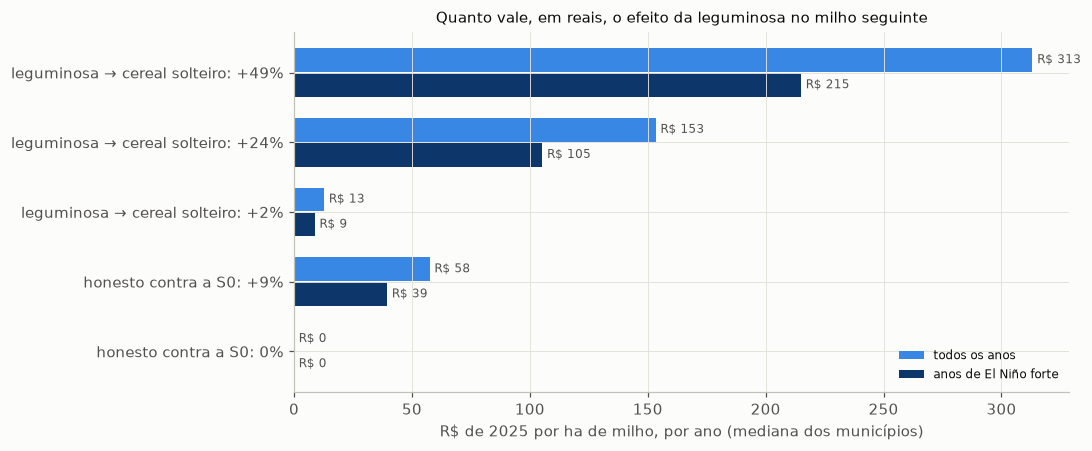

In [28]:
EFEITOS = {"honesto contra a S0: 0%": 0.0, "honesto contra a S0: +9%": 0.09, "leguminosa → cereal solteiro: +2%": 0.02,
           "leguminosa → cereal solteiro: +24%": 0.24, "leguminosa → cereal solteiro: +49%": 0.49}
Mi = M[M.produto == "Milho"].copy()
Mi["colhe"] = ~Mi.quebra
bon = []
for nome, e in EFEITOS.items():
    v = (e * Mi.R * Mi.colhe)
    por_mun = v.groupby(Mi.cod_mun).mean()
    por_mun_en = v[Mi.ano.isin(EN_FORTE)].groupby(Mi.cod_mun[Mi.ano.isin(EN_FORTE)]).mean()
    bon.append({"cenário": nome, "bônus médio (R$/ha·ano)": por_mun.median(), "P10 entre municípios": por_mun.quantile(0.1),
                "P90 entre municípios": por_mun.quantile(0.9), "bônus médio em El Niño forte": por_mun_en.median(),
                "Quixadá": por_mun.get(QUIXADA, np.nan), "Quixadá, El Niño forte": por_mun_en.get(QUIXADA, np.nan)})
BON = pd.DataFrame(bon).set_index("cenário")
print(f"Valor do bônus no milho do ano seguinte (R$ de 2025 por ha de milho; {Mi.cod_mun.nunique()} municípios). "
      f"Anos sem quebra: {Mi.colhe.mean() * 100:.1f}% (El Niño forte: {Mi[Mi.ano.isin(EN_FORTE)].colhe.mean() * 100:.1f}%)")
display(BON.round(0))
mi_q = Mi[Mi.cod_mun == QUIXADA]
print(f"Quixadá: receita mediana do milho {brl(mi_q.R.median())}/ha; quebra em {mi_q.quebra.mean() * 100:.0f}% dos anos "
      f"({int(mi_q.quebra.sum())} de {len(mi_q)}); desembolso do milho (Crateús) {brl(CUSTO.loc['Milho', 'desembolso'])}/ha")

fig, ax = plt.subplots(figsize=(10, 4.2))
nomes = list(EFEITOS)
y = np.arange(len(nomes))
ax.barh(y + 0.18, BON["bônus médio (R$/ha·ano)"], height=0.34, color="#3987e5", label="todos os anos")
ax.barh(y - 0.18, BON["bônus médio em El Niño forte"], height=0.34, color="#0d366b", label="anos de El Niño forte")
for k in range(len(nomes)):
    ax.text(BON.iloc[k, 0] + 2, k + 0.18, brl(BON.iloc[k, 0]), va="center", fontsize=8, color="#52514e")
    ax.text(BON.iloc[k, 3] + 2, k - 0.18, brl(BON.iloc[k, 3]), va="center", fontsize=8, color="#52514e")
ax.set_yticks(y, nomes)
ax.set_xlabel("R$ de 2025 por ha de milho, por ano (mediana dos municípios)")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("Quanto vale, em reais, o efeito da leguminosa no milho seguinte", fontsize=10)
plt.tight_layout()
plt.show()

**A sequência inteira.** O catálogo (item 12, grau D) já comparou, no semiárido de 2010–2024, feijão → milho contra
milho → milho: a sequência com feijão dá 0,80–0,94 da massa, mas 1,55–1,69 vez a receita. Refazemos em R$ de 2025
(receita observada, os dois anos somados), com e sem o bônus. A conta mostra de onde vem o dinheiro: do preço do
feijão (≈ 3,6 vezes o do milho por kg, seção 3), não do nitrogênio.

In [29]:
base_sa = M[M.semiarido & M.ano.between(2010, 2025) & M.produto.isin(["Milho", "Feijão"])].pivot_table(index=["cod_mun", "ano"], columns="produto", values="R_obs")
nxt = base_sa.reindex([(c, a + 1) for c, a in base_sa.index])
nxt.index = base_sa.index
SA = base_sa.join(nxt.add_suffix("_t1")).dropna()
SA = SA[SA.index.get_level_values(1) <= 2024]
qm = M[M.produto == "Milho"].set_index(["cod_mun", "ano"]).quebra
SA["colhe_t1"] = ~qm.reindex([(c, a + 1) for c, a in SA.index]).fillna(False).astype(bool).to_numpy()
seq = {}
for nome, e in [("sem bônus", 0.0), ("bônus +24%", 0.24)]:
    fm_ = SA.Feijão + SA.Milho_t1 * (1 + e * SA.colhe_t1)
    mm_ = SA.Milho + SA.Milho_t1
    r = fm_ / mm_
    seq[nome] = {"receita de 2 anos, feijão → milho (R$/ha)": fm_.median(), "receita de 2 anos, milho → milho (R$/ha)": mm_.median(),
                 "razão mediana": r.median(), "acima do milho → milho (%)": (r > 1).mean() * 100}
print(f"Sequência de 2 anos no semiárido, 2010–2024 ({len(SA)} pares município-ano)")
display(pd.DataFrame(seq).T.round(2))

Sequência de 2 anos no semiárido, 2010–2024 (17396 pares município-ano)


,"receita de 2 anos, feijão → milho (R$/ha)","receita de 2 anos, milho → milho (R$/ha)",razão mediana,acima do milho → milho (%)
sem bônus,"1.589,51","996,02","1,44","80,74"
bônus +24%,"1.707,11","996,02","1,56","87,03"


**Em três anos (2027–2029), para a faixa 2 do plano.** O caupi de 2027 só paga o bônus em 2028, e só se 2028 não for
ano de quebra. A tabela usa a distribuição do próprio município: o bônus esperado em 2028 é o efeito × a receita média
do milho nos anos sem quebra × a chance de não quebrar. Em Quixadá, por ha e para a faixa de 2/3 ha da família (a
largura da faixa é suposição da seção 10).

In [30]:
q = Mi[Mi.cod_mun == QUIXADA]
p_colhe = q.colhe.mean()
p_colhe_en = q[q.ano.isin(EN_FORTE)].colhe.mean()
r_colhe = q[q.colhe].R.mean()
lin = []
for nome, e in EFEITOS.items():
    lin.append({"cenário": nome, "2028 normal: R$/ha": e * r_colhe * p_colhe, "2028 normal: faixa de 2/3 ha": e * r_colhe * p_colhe * 2 / 3,
                "2028 como El Niño forte: R$/ha": e * r_colhe * p_colhe_en, "2028 como El Niño forte: faixa de 2/3 ha": e * r_colhe * p_colhe_en * 2 / 3})
ROT3 = pd.DataFrame(lin).set_index("cenário")
print(f"Quixadá: chance de o milho não quebrar {p_colhe * 100:.0f}% (em El Niño forte {p_colhe_en * 100:.0f}%); receita média do milho nos anos colhidos {brl(r_colhe)}/ha")
display(ROT3.round(0))

Quixadá: chance de o milho não quebrar 71% (em El Niño forte 25%); receita média do milho nos anos colhidos R$ 1.144/ha


,2028 normal: R$/ha,2028 normal: faixa de 2/3 ha,2028 como El Niño forte: R$/ha,2028 como El Niño forte: faixa de 2/3 ha
cenário,,,,
honesto contra a S0: 0%,"0,00","0,00","0,00","0,00"
honesto contra a S0: +9%,"74,00","49,00","26,00","17,00"
leguminosa → cereal solteiro: +2%,"16,00","11,00","6,00","4,00"
leguminosa → cereal solteiro: +24%,"196,00","131,00","69,00","46,00"
leguminosa → cereal solteiro: +49%,"401,00","267,00","140,00","93,00"


**Leitura.**
- O milho **não quebra em 76,8%** dos município-anos (61,0% em El Niño forte); só nesses anos o bônus vale.
- **Bônus de +24%** (leguminosa → cereal solteiro): **R$ 153 por ha de milho por ano** na mediana dos municípios (P10
  R$ 72; P90 R$ 421); R$ 105 em El Niño forte. Na faixa de +2% a +49%: de R$ 13 a R$ 313.
- **Cenário honesto contra a S0:** central 0; com +9%, R$ 58/ha por ano (R$ 39 em El Niño forte).
- O bônus de +24% é cerca de 1/4 da receita mediana do milho e **não chega ao desembolso** do milho (R$ 1.136/ha): a
  rotação não faz o milho pagar a planilha.
- **Sequência de 2 anos:** feijão → milho rende 1,44 vez a receita de milho → milho sem bônus (acima em 81% dos pares)
  e 1,56 vez com +24% (87%). Reproduz o catálogo (1,55–1,69 vez; 82–90%). O dinheiro vem do preço do feijão.
- **Quixadá, faixa 2 (2/3 ha), 2028:** o milho não quebra em 71% dos anos (25% em El Niño forte). Bônus esperado de
  R$ 131 com +24%, R$ 49 com +9% e R$ 0 no central honesto; se 2028 for como um El Niño forte, R$ 46 com +24%. **Em 3
  anos, a rotação em si vale menos de R$ 300 para a família.** O valor do plano está em outro lugar (seções 7 e 10).

## 9. O cardápio do protótipo em reais, município a município

O motor do protótipo decide, para cada município, a situação de cada cultura (`E:/campeonato-nasa/dados/gaez_zarc/
nordeste_2026-2027.csv`, versão regerada em 14/11): onde a cultura tem ZARC no município, o ZARC decide ("indicada" =
risco de 20% em algum solo e ciclo; "com risco" = só 30% ou 40%); sem ZARC, o GAEZ v4 com insumo baixo filtra
(aptidão > 40 = "só aptidão"; classes oficiais do GAEZ v4: > 85 muito alta, > 70 alta, > 55 boa, > 40 média,
> 25 moderada, > 10 marginal). Aqui cruzamos essa situação com o dinheiro das seções 4 a 6.

**A mandioca e o ZARC.** A tábua aberta do ZARC 2026/27 não traz a mandioca, então o motor a filtra pelo GAEZ. No CE,
a mandioca tem ZARC em portaria plurianual (Port. 11/2020; em Quixadá, a janela vai até 31/03), fora da tábua.

- **Disponível** = "indicada" ou "só aptidão". O feijão do PAM vale para o caupi e para o feijão comum: conta a melhor
  situação dos dois.
- **Com série** = o município tem ≥ 10 anos válidos da cultura no PAM. Sem série, a cultura fica no cardápio, mas sem
  número de dinheiro (o produto mostra "sem histórico de produção no município").
- **Maior margem esperada** = maior margem mediana sobre o desembolso (seção 5; custo suposto onde não há CONAB).
- **Menor risco** = maior receita no pior decil (CVaR10 em R$/ha): a cultura que mais deixa dinheiro no ano ruim.
- **Melhor por mês de terra** = maior receita mediana por ha-mês (ciclo central da seção 1).

In [31]:
GZN = pd.read_csv(DADOS / "gaez_zarc" / "nordeste_2026-2027.csv", dtype={"geocodigo": str})
MAPA_C = {"Milho 1ª Safra": "Milho", "Feijão Caupi": "Feijão", "Feijão 2ª Safra": "Feijão", "Sorgo Granífero": "Sorgo",
          "Algodão Herbáceo": "Algodão herbáceo", "Amendoim": "Amendoim", "Girassol": "Girassol", "Mamona": "Mamona", "mandioca": "Mandioca"}
ORD_SIT = {"indicada": 0, "só aptidão": 1, "com risco": 2, "fora": 3}
g = GZN.assign(produto=GZN.cultura.map(MAPA_C)).dropna(subset=["produto"])
g["o"] = g.situacao.map(ORD_SIT)
SIT = g.sort_values("o").groupby(["geocodigo", "produto"]).situacao.first().unstack()
CARD = ["Feijão Caupi", "Milho 1ª Safra", "Feijão 2ª Safra", "mandioca", "Amendoim", "Sorgo Granífero", "guandu", "Sorgo Forrageiro",
        "milheto", "Algodão Herbáceo", "Mamona", "Girassol"]
n_card = GZN[GZN.cultura.isin(CARD) & GZN.situacao.isin(["indicada", "só aptidão"])].groupby("geocodigo").cultura.nunique()
print(f"Culturas do cardápio com camada (12 de 15) disponíveis por município: mediana {n_card.median():.0f} (P10 {n_card.quantile(.1):.0f}, "
      f"P90 {n_card.quantile(.9):.0f}); {GZN.geocodigo.nunique()} municípios")
display(pd.crosstab(g.produto, g.situacao).reindex(index=CULT, columns=list(ORD_SIT)).fillna(0).astype(int))

met = mm.merge(RR[["produto", "cod_mun", "cvar10", "cvar10_rel"]], on=["produto", "cod_mun"], how="left")
met["por_ha_mes"] = met.R / met.produto.map(CICLO.dias / 30.4)
met["situacao"] = [SIT.at[c, p] if c in SIT.index and p in SIT.columns else np.nan for c, p in zip(met.cod_mun, met.produto)]
cand = met[met.situacao.isin(["indicada", "só aptidão"])]
print(f"Pares município × cultura com série: {len(met)}; disponíveis no cardápio: {len(cand)} ({len(cand) / len(met) * 100:.0f}%)")
fora = met[~met.situacao.isin(["indicada", "só aptidão"])]
print("Com série no PAM, mas fora do cardápio (o produtor planta onde o motor não indica):")
display(fora.groupby(["produto", "situacao"]).size().unstack(fill_value=0).reindex(CULT).dropna(how="all").astype(int))

Culturas do cardápio com camada (12 de 15) disponíveis por município: mediana 9 (P10 5, P90 11); 1794 municípios


situacao,indicada,só aptidão,com risco,fora
produto,,,,
Milho,1154,144,370,126
Feijão,2538,135,830,85
Mandioca,0,1203,0,591
Sorgo,1410,16,288,80
Amendoim,1363,0,312,119
Algodão herbáceo,1355,21,305,113
Mamona,1730,0,64,0
Girassol,793,57,370,574


Pares município × cultura com série: 5702; disponíveis no cardápio: 4297 (75%)
Com série no PAM, mas fora do cardápio (o produtor planta onde o motor não indica):


situacao,com risco,fora
produto,,
Milho,369,124
Feijão,232,5
Mandioca,0,480
Sorgo,21,0
Amendoim,8,10
Algodão herbáceo,91,22
Mamona,43,0


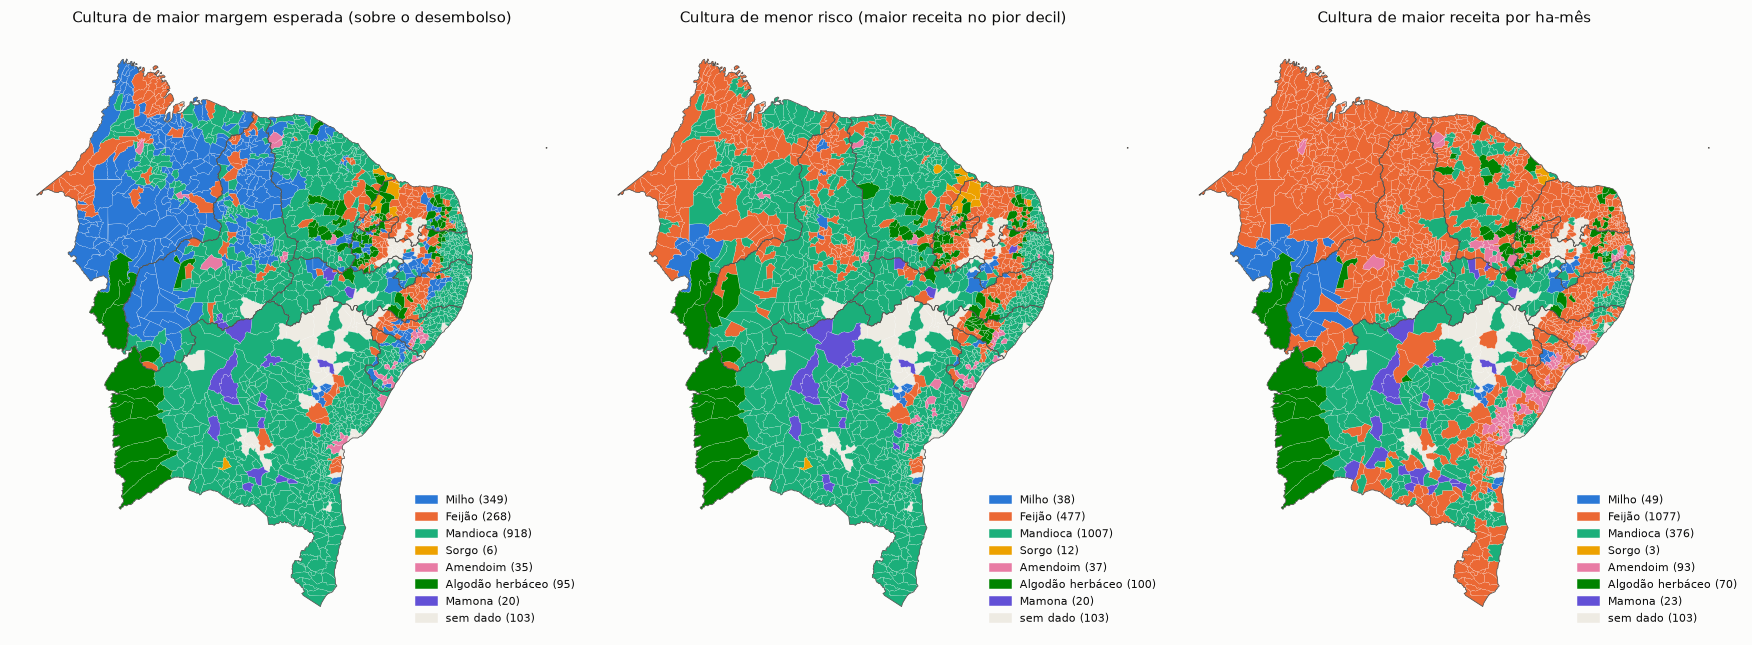

Número de municípios em que cada cultura vence: NE inteiro | só o semiárido (delimitação 2022)


NE                           semiárido                       
                 maior margem menor risco por ha-mês maior margem menor risco por ha-mês
produto                                                                                 
Milho                     349          38         49          227          28         30
Feijão                    268         477       1077          215         350        727
Mandioca                  918        1007        376          602         655        281
Sorgo                       6          12          3            6          12          3
Amendoim                   35          37         93           11          13         42
Algodão herbáceo           95         100         70           91          94         66
Mamona                     20          20         23           20          20         23
Girassol                    0           0          0            0           0          0

Aviso: no cerrado (oeste da BA, sul do MA e do PI), milho e algodão são lavoura empresarial (CONAB Barreiras-BA: algodão R$ 10.517/ha de custo operacional); o custo de lavoura familiar usado aqui não vale lá, e a vitória do algodão e do milho nesses municípios é otimista.
Municípios com ≥ 1 cultura disponível e com série: 1691 de 1794; a de maior margem é 'indicada' pelo ZARC em 43% deles
Margem mediana da melhor cultura > 0 (sobre o desembolso) em 67% dos municípios; sobre a semente em 97%
Sem a mandioca, a cultura de maior margem seria:


produto
Milho               597
Feijão              587
Sorgo                13
Amendoim            131
Algodão herbáceo    141
Mamona               88
Name: count, dtype: int64

produto,Milho,Feijão,Mandioca,Sorgo,Amendoim,Algodão herbáceo,Mamona
uf,,,,,,,
MA,120,44,45,0,3,3,0
PI,96,20,98,0,4,2,3
CE,24,15,121,1,4,19,0
RN,14,72,39,4,0,25,0
PB,38,47,77,0,0,32,0
PE,17,32,117,0,0,6,2
AL,15,21,50,0,10,0,0
SE,16,4,43,0,10,0,0
BA,9,13,328,1,4,8,15


In [32]:
best_m = cand.loc[cand.groupby("cod_mun").marg_desembolso.idxmax()].set_index("cod_mun")
best_r = cand.loc[cand.groupby("cod_mun").cvar10.idxmax()].set_index("cod_mun")
best_h = cand.loc[cand.groupby("cod_mun").por_ha_mes.idxmax()].set_index("cod_mun")
fig, axs = plt.subplots(1, 3, figsize=(16, 6.2))
mapa_ne(axs[0], best_m.produto, "Cultura de maior margem esperada (sobre o desembolso)", cores=COR, ordem=CULT)
mapa_ne(axs[1], best_r.produto, "Cultura de menor risco (maior receita no pior decil)", cores=COR, ordem=CULT)
mapa_ne(axs[2], best_h.produto, "Cultura de maior receita por ha-mês", cores=COR, ordem=CULT)
plt.tight_layout()
plt.show()
venc = pd.DataFrame({"maior margem": best_m.produto.value_counts(), "menor risco": best_r.produto.value_counts(),
                     "por ha-mês": best_h.produto.value_counts()}).reindex(CULT).fillna(0).astype(int)
sa_m = REFM.semiarido_2022
venc_sa = pd.DataFrame({"maior margem": best_m[best_m.index.map(sa_m) == True].produto.value_counts(),
                        "menor risco": best_r[best_r.index.map(sa_m) == True].produto.value_counts(),
                        "por ha-mês": best_h[best_h.index.map(sa_m) == True].produto.value_counts()}).reindex(CULT).fillna(0).astype(int)
print("Número de municípios em que cada cultura vence: NE inteiro | só o semiárido (delimitação 2022)")
display(pd.concat({"NE": venc, "semiárido": venc_sa}, axis=1))
print("Aviso: no cerrado (oeste da BA, sul do MA e do PI), milho e algodão são lavoura empresarial (CONAB Barreiras-BA: algodão "
      f"{brl(C[C.cultura_arquivo.eq('Algodão')].custo_operacional_r_ha_r2025.median())}/ha de custo operacional); o custo de lavoura "
      "familiar usado aqui não vale lá, e a vitória do algodão e do milho nesses municípios é otimista.")
print(f"Municípios com ≥ 1 cultura disponível e com série: {cand.cod_mun.nunique()} de {GZN.geocodigo.nunique()}; "
      f"a de maior margem é 'indicada' pelo ZARC em {(best_m.situacao == 'indicada').mean() * 100:.0f}% deles")
print(f"Margem mediana da melhor cultura > 0 (sobre o desembolso) em {(best_m.marg_desembolso > 0).mean() * 100:.0f}% dos municípios; "
      f"sobre a semente em {(best_m.marg_semente > 0).mean() * 100:.0f}%")
sem_mand = cand[cand.produto != "Mandioca"]
best_sm = sem_mand.loc[sem_mand.groupby("cod_mun").marg_desembolso.idxmax()].set_index("cod_mun")
print("Sem a mandioca, a cultura de maior margem seria:")
display(best_sm.produto.value_counts().reindex(CULT).dropna().astype(int))
uf_w = best_m.assign(uf=best_m.index.str[:2].map(dict(zip(["21", "22", "23", "24", "25", "26", "27", "28", "29"], UFS))))
display(pd.crosstab(uf_w.uf, uf_w.produto).reindex(index=UFS, columns=[c for c in CULT if c in uf_w.produto.unique()]).fillna(0).astype(int))

In [33]:
qx = met[met.cod_mun == QUIXADA].set_index("produto")[["situacao", "R", "marg_semente", "marg_desembolso", "falha_desembolso", "cvar10", "cvar10_rel", "por_ha_mes"]]
qx.columns = ["situação no cardápio", "receita mediana", "margem (semente)", "margem (desembolso)", "não paga desembolso (frac.)", "CVaR10 (R$/ha)",
              "CVaR10 ÷ mediana", "R$ por ha-mês"]
print("Quixadá: culturas com série no PAM, situação no cardápio e dinheiro (R$ de 2025/ha plantado)")
display(qx.reindex([c for c in CULT if c in qx.index]).round(2))
print("Cardápio de Quixadá no motor:", ", ".join(f"{r.cultura} ({r.situacao})" for r in GZN[GZN.geocodigo == QUIXADA].itertuples()))

Quixadá: culturas com série no PAM, situação no cardápio e dinheiro (R$ de 2025/ha plantado)


,situação no cardápio,receita mediana,margem (semente),margem (desembolso),não paga desembolso (frac.),CVaR10 (R$/ha),CVaR10 ÷ mediana,R$ por ha-mês
produto,,,,,,,,
Milho,com risco,"650,63","366,85","-485,37","0,68","63,51","0,10","179,81"
Feijão,indicada,"1.505,88","1.364,36","-486,25","0,57","332,86","0,22","653,98"
Mandioca,só aptidão,"12.895,59","12.895,59","8.508,85","0,00","5.895,66","0,46","859,71"
Algodão herbáceo,indicada,"2.034,62","1.893,09","42,49","0,46","410,71","0,20","441,80"
Mamona,indicada,"590,85","552,19","-2.065,62","0,92","116,15","0,20","99,79"


Cardápio de Quixadá no motor: Milho 1ª Safra (com risco), Milho 1ª Safra consorciado com Braquiária (com risco), Feijão Caupi (indicada), Feijão 2ª Safra (com risco), Sorgo Granífero (indicada), Sorgo Forrageiro (indicada), Algodão Herbáceo (indicada), Amendoim (indicada), Girassol (fora), mandioca (só aptidão), milheto (só aptidão), guandu (só aptidão), soja (só aptidão), Mamona (indicada)


**Leitura.**
- O motor deixa **9 culturas** com camada disponíveis no município mediano (P10 5, P90 11), de 12.
- **75%** dos pares município × cultura com 10 anos ou mais de produção no PAM estão disponíveis no cardápio.
- **O cardápio corta a mandioca onde ela é plantada:** 480 municípios com 10 anos ou mais de mandioca no PAM ficam
  "fora" (GAEZ ≤ 40 e sem ZARC na tábua). No milho, 369 ficam "com risco" e 124 "fora"; no feijão, 232 "com risco".
- **Cultura de maior margem esperada** (sobre o desembolso): mandioca em 918 municípios, milho em 349, feijão em 268,
  algodão em 95, amendoim em 35, mamona em 20, sorgo em 6. No semiárido: mandioca 602, milho 227, feijão 215,
  algodão 91. Sem a mandioca, o milho venceria em 597 e o feijão em 587.
- **Cultura de menor risco** (mais receita no pior decil): mandioca em 1.007 municípios, feijão em 477.
- **Por ha-mês, o feijão/caupi vence em 1.077 municípios** (727 no semiárido); a mandioca em 376; o amendoim em 93.
- 1.691 de 1.794 municípios têm ao menos uma cultura disponível e com série. A margem mediana da melhor delas é
  positiva sobre o desembolso em 67% dos municípios e sobre a semente em 97%. A melhor é "indicada" pelo ZARC em só
  43%: a mandioca, que mais vence, não está na tábua aberta do ZARC.
- **Quixadá:** mandioca ("só aptidão") rende R$ 12.896/ha na mediana, com margem de +R$ 8.509 sobre o desembolso e
  R$ 5.896 no pior decil (com o preço de pouco volume da seção 10); feijão ("indicada") R$ 1.506 e −R$ 486; milho
  ("com risco") R$ 651 e −R$ 485; algodão ("indicada") R$ 2.035 e +R$ 42; mamona ("indicada") −R$ 2.066.
- No cerrado (oeste da BA, sul do MA e do PI), a vitória do milho e do algodão é otimista: o custo usado é o de lavoura
  familiar, e a CONAB de Barreiras-BA dá R$ 10.517/ha no algodão.

## 10. A família de Quixadá: fluxo de caixa 2027–2029

**A família é a da proposta (fictícia e rotulada como tal):** Dona Francisca, Quixadá-CE, 3 ha (1 ha de baixio), 8
cabras, semente própria de milho e feijão, **sem mandioca no chão hoje**. O plano é o da seção 6.4 da proposta:

| Talhão | 2027 | 2028 | 2029 |
|---|---|---|---|
| Faixa 1 | maniva (fev até o fim da janela ZARC da mandioca, em geral março) | mandioca = tampão (colheita) | caupi precoce |
| Faixa 2 | caupi precoce (metade guardada até ~10/mar) | ano bom: milho depois do caupi · ano seco: sorgo forrageiro | maniva |
| Faixa 3 | sorgo forrageiro | maniva | mandioca = tampão (colheita) |
| Baixio (1 ha) | milho + caupi em revezamento | o mesmo | o mesmo |
| Bordas | palma + gliricídia | ficam | ficam |

**O que é medido e o que é suposição nesta conta:**

| Item | Valor | Tipo |
|---|---|---|
| Receita por ha de milho, feijão e mandioca em Quixadá | mediana do próprio município no grupo de anos do cenário, a preço de referência (PAM 1998–2025) | medido |
| Cenários de ano | normal = anos sem El Niño forte e fora da seca; El Niño forte = 1998, 2010, 2016, 2024; seca = 2012–2015 | medido (o grupo); a escolha do cenário é suposição |
| Mandioca em ano de seca | Quixadá não tem mandioca ≥ 10 ha em 2012–2015: usamos a razão ao normal mediana da mesorregião (Sertão Cearense) | suposição com dado vizinho |
| Faixas | três faixas iguais de 2/3 ha; as bordas (palma + gliricídia) não tiram área | **suposição** (a proposta deixa o tamanho para a família e o técnico) |
| Baixio | milho + caupi = ½ receita do milho + ½ do feijão por ha (a convenção da S0) | suposição de convenção |
| Bônus da leguminosa no milho de 2028 | 0% (honesto contra a S0), +9% e +24% (contra cereal solteiro) | literatura (D·T3 e B·T1) |
| Custo | dois níveis da CONAB: só semente, e desembolso; a mão de obra da família não entra | CONAB (Crateús-CE no milho; mediana NE no feijão e na mandioca) |
| Mandioca: quando conta o custo | todo no ano da maniva; a receita, no ano da colheita | suposição conservadora para o caixa |
| Sorgo forrageiro, palma, gliricídia | sem receita em dinheiro (valor de uso para as cabras, não medido); o sorgo forrageiro tem o custo suposto de lavoura anual | suposição; qualitativo |
| Garantia-Safra | não entra (o valor do benefício não está nas fontes lidas) | fora da conta |

In [34]:
REG = REFM.mesorregiao.to_dict()
meso_q = REG[QUIXADA]


def grupo_ano(a):
    return "El Niño forte" if a in EN_FORTE else ("seca" if a in SECA else "normal")


Mq = M[M.produto.isin(["Milho", "Feijão", "Mandioca"])].copy()
Mq["g"] = Mq.ano.map(grupo_ano)
REC_Q, ORIG = {}, {}
for c in ["Milho", "Feijão", "Mandioca"]:
    sq = Mq[(Mq.cod_mun == QUIXADA) & (Mq.produto == c)]
    base = sq.R.median()
    for gr in ["normal", "El Niño forte", "seca"]:
        s = sq[sq.g == gr].R
        if len(s) >= 2:
            REC_Q[(c, gr)], ORIG[(c, gr)] = s.median(), f"Quixadá, {len(s)} anos"
        else:
            viz = Mq[(Mq.produto == c) & (Mq.cod_mun.map(REG) == meso_q) & (Mq.g == gr)].R_rel.median()
            REC_Q[(c, gr)], ORIG[(c, gr)] = base * viz, f"mesorregião ({meso_q}), razão {viz:.2f}"
rq = pd.DataFrame({"R$/ha": pd.Series(REC_Q), "origem": pd.Series(ORIG)})
print("Receita por ha plantado em Quixadá, por cenário (R$ de 2025, preço de referência)")
display(rq)

A_F, A_B = 2 / 3, 1.0  # área de cada faixa e do baixio (ha) — suposição
MULT_MAND = 1.0  # preço da raiz = preço de referência de Quixadá (a seção final testa outros)
KS_, KD_ = CUSTO.semente, CUSTO.desembolso


def ano_plano(ano, cen, bonus, ano_seco_f2=False):
    """Receita e custos (semente, desembolso) do plano no ano, por talhão."""
    r = lambda c: REC_Q[(c, cen)]
    t = []
    s0b = ((r("Milho") + r("Feijão")) / 2 * A_B, (KS_.Milho + KS_.Feijão) / 2 * A_B, (KD_.Milho + KD_.Feijão) / 2 * A_B)
    if ano == 2027:
        t += [("Faixa 1: maniva", 0, KS_.Mandioca * A_F, KD_.Mandioca * A_F), ("Faixa 2: caupi", r("Feijão") * A_F, KS_.Feijão * A_F, KD_.Feijão * A_F),
              ("Faixa 3: sorgo forrageiro", 0, KS_.Sorgo * A_F, KD_.Sorgo * A_F)]
    elif ano == 2028:
        f2 = (("Faixa 2: sorgo forrageiro (ano seco)", 0, KS_.Sorgo * A_F, KD_.Sorgo * A_F) if ano_seco_f2 else
              ("Faixa 2: milho depois do caupi", r("Milho") * (1 + bonus) * A_F, KS_.Milho * A_F, KD_.Milho * A_F))
        t += [("Faixa 1: mandioca (colheita)", r("Mandioca") * MULT_MAND * A_F, 0, 0), f2, ("Faixa 3: maniva", 0, KS_.Mandioca * A_F, KD_.Mandioca * A_F)]
    else:
        t += [("Faixa 1: caupi", r("Feijão") * A_F, KS_.Feijão * A_F, KD_.Feijão * A_F), ("Faixa 2: maniva", 0, KS_.Mandioca * A_F, KD_.Mandioca * A_F),
              ("Faixa 3: mandioca (colheita)", r("Mandioca") * MULT_MAND * A_F, 0, 0)]
    t.append(("Baixio: milho + caupi", *s0b))
    return pd.DataFrame(t, columns=["talhão", "receita", "custo_semente", "custo_desembolso"])


def ano_s0(cen):
    r = lambda c: REC_Q[(c, cen)]
    return pd.DataFrame([("S0: 3 ha de milho + feijão", (r("Milho") + r("Feijão")) / 2 * 3, (KS_.Milho + KS_.Feijão) / 2 * 3,
                          (KD_.Milho + KD_.Feijão) / 2 * 3)], columns=["talhão", "receita", "custo_semente", "custo_desembolso"])


CENARIOS = {"A. três anos normais": ["normal", "normal", "normal"],
            "B. El Niño forte em 2027, depois normal": ["El Niño forte", "normal", "normal"],
            "C. El Niño forte em 2027 e seca em 2028": ["El Niño forte", "seca", "normal"]}
linhas, detalhe = [], {}
for nome, cens in CENARIOS.items():
    for bonus in [0.0, 0.24]:
        for ano, cen in zip([2027, 2028, 2029], cens):
            seco = cen == "seca" and ano == 2028
            pl = ano_plano(ano, cen, bonus, ano_seco_f2=seco)
            s0 = ano_s0(cen)
            detalhe[(nome, bonus, ano)] = pl
            for rot, d in [("Plano", pl), ("S0", s0)]:
                linhas.append({"cenário": nome, "bônus": bonus, "ano": ano, "quadra": cen, "sistema": rot, "receita": d.receita.sum(),
                               "custo semente": d.custo_semente.sum(), "custo desembolso": d.custo_desembolso.sum()})
FC = pd.DataFrame(linhas)
FC["margem sobre a semente"] = FC.receita - FC["custo semente"]
FC["margem sobre o desembolso"] = FC.receita - FC["custo desembolso"]
print("Talhões do plano no cenário B (bônus 0), ano a ano (R$ de 2025)")
for ano in [2027, 2028, 2029]:
    print(f"— {ano}")
    display(detalhe[("B. El Niño forte em 2027, depois normal", 0.0, ano)].round(0))
print("Fluxo de caixa da família, 3 ha (R$ de 2025; bônus 0 = cenário honesto contra a S0)")
display(FC[FC.bônus == 0].pivot_table(index=["cenário", "ano", "quadra"], columns="sistema",
                                      values=["receita", "margem sobre a semente", "margem sobre o desembolso"]).round(0))

Receita por ha plantado em Quixadá, por cenário (R$ de 2025, preço de referência)


R$/ha                                       origem
Milho    normal           966,98                             Quixadá, 20 anos
         El Niño forte    190,44                              Quixadá, 4 anos
         seca             455,03                              Quixadá, 4 anos
Feijão   normal         2.141,91                             Quixadá, 20 anos
         El Niño forte    830,59                              Quixadá, 4 anos
         seca           1.200,77                              Quixadá, 4 anos
Mandioca normal        13.340,27                             Quixadá, 20 anos
         El Niño forte  6.936,94                              Quixadá, 4 anos
         seca           5.429,72  mesorregião (Sertões Cearenses), razão 0.42

Talhões do plano no cenário B (bônus 0), ano a ano (R$ de 2025)
— 2027


,talhão,receita,custo_semente,custo_desembolso
0,Faixa 1: maniva,"0,00","0,00","2.924,00"
1,Faixa 2: caupi,"554,00","94,00","1.328,00"
2,Faixa 3: sorgo forrageiro,"0,00","94,00","1.328,00"
3,Baixio: milho + caupi,"511,00","213,00","1.564,00"


— 2028


,talhão,receita,custo_semente,custo_desembolso
0,Faixa 1: mandioca (colheita),"8.894,00","0,00","0,00"
1,Faixa 2: milho depois do caupi,"645,00","189,00","757,00"
2,Faixa 3: maniva,"0,00","0,00","2.924,00"
3,Baixio: milho + caupi,"1.554,00","213,00","1.564,00"


— 2029


,talhão,receita,custo_semente,custo_desembolso
0,Faixa 1: caupi,"1.428,00","94,00","1.328,00"
1,Faixa 2: maniva,"0,00","0,00","2.924,00"
2,Faixa 3: mandioca (colheita),"8.894,00","0,00","0,00"
3,Baixio: milho + caupi,"1.554,00","213,00","1.564,00"


Fluxo de caixa da família, 3 ha (R$ de 2025; bônus 0 = cenário honesto contra a S0)


margem sobre a semente          margem sobre o desembolso             receita         
sistema                                                                     Plano       S0                     Plano        S0     Plano       S0
cenário                                 ano  quadra                                                                                              
A. três anos normais                    2027 normal                      2.581,00 4.025,00                 -4.162,00    -29,00  2.982,00 4.663,00
                                        2028 normal                     10.691,00 4.025,00                  5.847,00    -29,00 11.093,00 4.663,00
                                        2029 normal                     11.569,00 4.025,00                  6.059,00    -29,00 11.876,00 4.663,00
B. El Niño forte em 2027, depois normal 2027 El Niño forte                 663,00   894,00                 -6.080,00 -3.161,00  1.064,00 1.532,00
                                        2028 normal                     10.691,00 4.025,00                  5.847,00    -29,00 11.093,00 4.663,00
                                        2029 normal                     11.569,00 4.025,00                  6.059,00    -29,00 11.876,00 4.663,00
C. El Niño forte em 2027 e seca em 2028 2027 El Niño forte                 663,00   894,00                 -6.080,00 -3.161,00  1.064,00 1.532,00
                                        2028 seca                        4.141,00 1.846,00                 -1.369,00 -2.208,00  4.448,00 2.484,00
                                        2029 normal                     11.569,00 4.025,00                  6.059,00    -29,00 11.876,00 4.663,00

Totais de 2027–2029 (R$ de 2025, 3 ha)


receita  custo semente  custo desembolso  margem sobre a semente  margem sobre o desembolso
cenário                                 bônus sistema                                                                                              
A. três anos normais                    0,00  Plano   25.951,00       1.110,00         18.207,00               24.841,00                   7.744,00
                                              S0      13.990,00       1.914,00         14.077,00               12.076,00                     -87,00
                                        0,24  Plano   26.106,00       1.110,00         18.207,00               24.995,00                   7.898,00
                                              S0      13.990,00       1.914,00         14.077,00               12.076,00                     -87,00
B. El Niño forte em 2027, depois normal 0,00  Plano   24.033,00       1.110,00         18.207,00               22.923,00                   5.825,00
                                              S0      10.858,00       1.914,00         14.077,00                8.944,00                  -3.218,00
                                        0,24  Plano   24.187,00       1.110,00         18.207,00               23.077,00                   5.980,00
                                              S0      10.858,00       1.914,00         14.077,00                8.944,00                  -3.218,00
C. El Niño forte em 2027 e seca em 2028 0,00  Plano   17.388,00       1.015,00         18.778,00               16.373,00                  -1.390,00
                                              S0       8.679,00       1.914,00         14.077,00                6.765,00                  -5.398,00
                                        0,24  Plano   17.388,00       1.015,00         18.778,00               16.373,00                  -1.390,00
                                              S0       8.679,00       1.914,00         14.077,00                6.765,00                  -5.398,00

Plano − S0, em 3 anos (R$ de 2025)


receita  custo semente  custo desembolso  margem sobre a semente  margem sobre o desembolso
cenário                                 bônus                                                                                              
A. três anos normais                    0,00  11.961,00        -804,00          4.131,00               12.765,00                   7.830,00
                                        0,24  12.116,00        -804,00          4.131,00               12.919,00                   7.985,00
B. El Niño forte em 2027, depois normal 0,00  13.175,00        -804,00          4.131,00               13.978,00                   9.044,00
                                        0,24  13.329,00        -804,00          4.131,00               14.133,00                   9.199,00
C. El Niño forte em 2027 e seca em 2028 0,00   8.709,00        -899,00          4.701,00                9.608,00                   4.008,00
                                        0,24   8.709,00        -899,00          4.701,00                9.608,00                   4.008,00

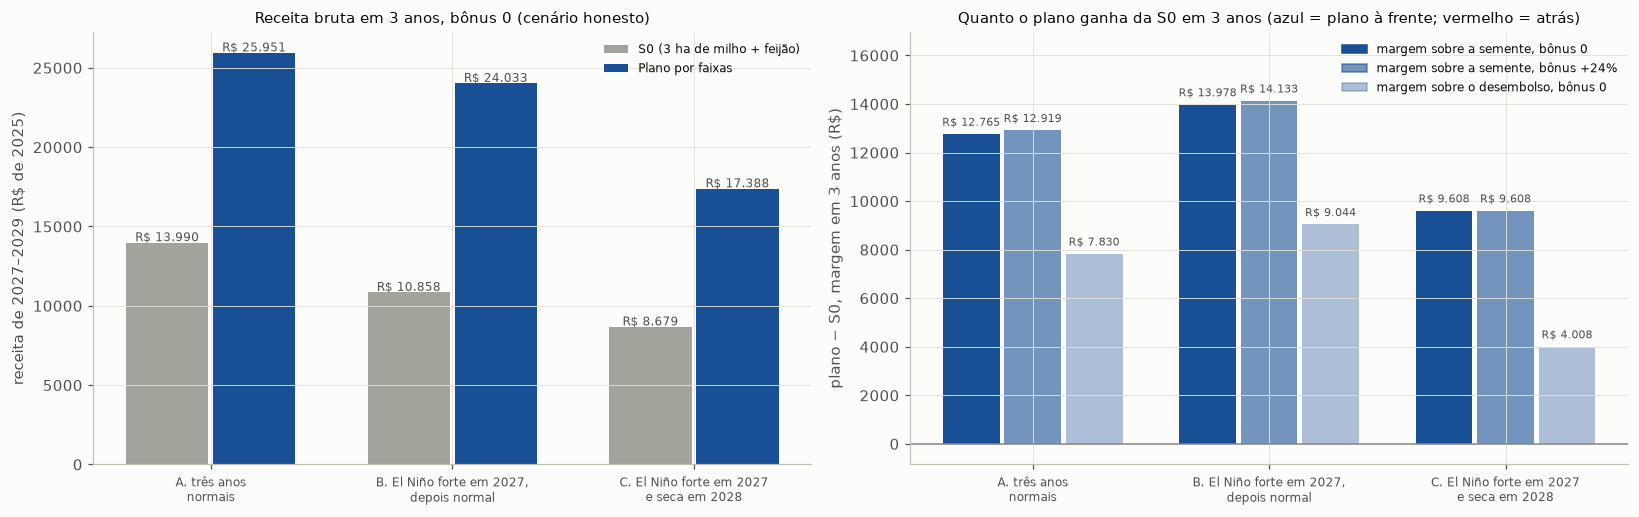

In [35]:
TOT = FC.groupby(["cenário", "bônus", "sistema"])[["receita", "custo semente", "custo desembolso", "margem sobre a semente", "margem sobre o desembolso"]].sum()
dif = (TOT.xs("Plano", level="sistema") - TOT.xs("S0", level="sistema"))
print("Totais de 2027–2029 (R$ de 2025, 3 ha)")
display(TOT.round(0))
print("Plano − S0, em 3 anos (R$ de 2025)")
display(dif.round(0))

fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
cn = list(CENARIOS)
x = np.arange(len(cn))
for k, (rot, cor) in enumerate([("S0", "#a3a29b"), ("Plano", "#184f95")]):
    v = [TOT.loc[(c, 0.0, rot), "receita"] for c in cn]
    axs[0].bar(x + (k - 0.5) * 0.36, v, width=0.34, color=cor, label=rot + (" (3 ha de milho + feijão)" if rot == "S0" else " por faixas"))
    for xi, vi in zip(x, v):
        axs[0].text(xi + (k - 0.5) * 0.36, vi + 80, brl(vi), ha="center", fontsize=8, color="#52514e")
ROT_CEN = ["A. três anos\nnormais", "B. El Niño forte em 2027,\ndepois normal", "C. El Niño forte em 2027\ne seca em 2028"]
axs[0].set_xticks(x, ROT_CEN, fontsize=8)
axs[0].set_ylabel("receita de 2027–2029 (R$ de 2025)")
axs[0].legend(frameon=False, fontsize=8)
axs[0].set_title("Receita bruta em 3 anos, bônus 0 (cenário honesto)", fontsize=10)
d0 = [dif.loc[(c, 0.0), "margem sobre a semente"] for c in cn]
d24 = [dif.loc[(c, 0.24), "margem sobre a semente"] for c in cn]
dd = [dif.loc[(c, 0.0), "margem sobre o desembolso"] for c in cn]
todos = np.array(d0 + d24 + dd)
lim = np.abs(todos).max() * 1.2
alc = []
for k, (v, rot) in enumerate([(d0, "margem sobre a semente, bônus 0"), (d24, "margem sobre a semente, bônus +24%"), (dd, "margem sobre o desembolso, bônus 0")]):
    cores = ["#184f95" if vi >= 0 else "#d03b3b" for vi in v]
    axs[1].bar(x + (k - 1) * 0.26, v, width=0.24, color=cores, alpha=[1, 0.6, 0.35][k])
    alc.append(Patch(color="#184f95", alpha=[1, 0.6, 0.35][k], label=rot))
    for xi, vi in zip(x, v):
        axs[1].text(xi + (k - 1) * 0.26, vi + (lim * 0.02 if vi >= 0 else -lim * 0.06), brl(vi), ha="center", fontsize=7, color="#52514e")
axs[1].axhline(0, color=CINZA, lw=1)
axs[1].set_ylim(min(0, todos.min()) * 1.3 - lim * 0.05, lim)
axs[1].set_xticks(x, ROT_CEN, fontsize=8)
axs[1].set_ylabel("plano − S0, margem em 3 anos (R$)")
axs[1].legend(handles=alc, frameon=False, fontsize=8, loc="upper right")
axs[1].set_title("Quanto o plano ganha da S0 em 3 anos (azul = plano à frente; vermelho = atrás)", fontsize=10)
plt.tight_layout()
plt.show()

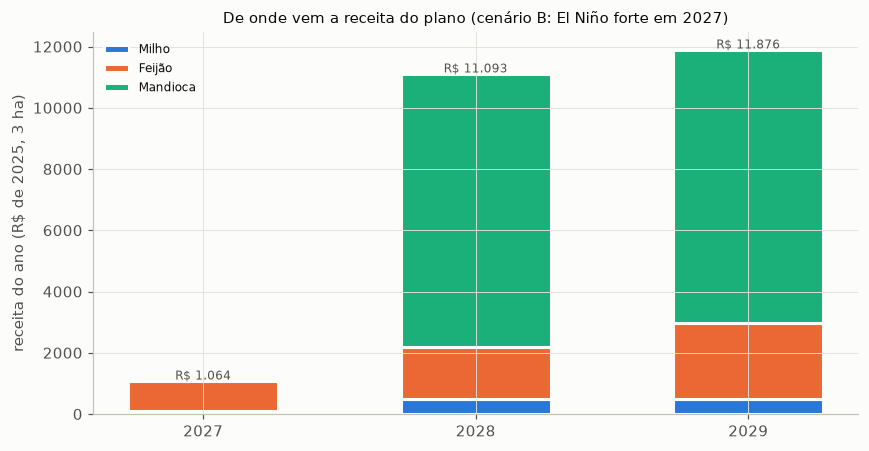

,Milho,Feijão,Mandioca
ano,,,
2027,"95,00","969,00","0,00"
2028,"483,00","1.716,00","8.894,00"
2029,"483,00","2.499,00","8.894,00"


In [36]:
# composição da receita do plano por cultura, cenário B, bônus 0
comp = []
for ano in [2027, 2028, 2029]:
    d = detalhe[("B. El Niño forte em 2027, depois normal", 0.0, ano)]
    cen = CENARIOS["B. El Niño forte em 2027, depois normal"][ano - 2027]
    lin = {"ano": ano, "Milho": 0.0, "Feijão": 0.0, "Mandioca": 0.0}
    for t in d.itertuples():
        if "mandioca (colheita)" in t.talhão:
            lin["Mandioca"] += t.receita
        elif "caupi" in t.talhão and "Baixio" not in t.talhão:
            lin["Feijão"] += t.receita
        elif "milho depois" in t.talhão:
            lin["Milho"] += t.receita
        elif "Baixio" in t.talhão:
            lin["Milho"] += REC_Q[("Milho", cen)] / 2 * A_B
            lin["Feijão"] += REC_Q[("Feijão", cen)] / 2 * A_B
    comp.append(lin)
comp = pd.DataFrame(comp).set_index("ano")
fig, ax = plt.subplots(figsize=(8, 4.2))
base = np.zeros(len(comp))
for c in ["Milho", "Feijão", "Mandioca"]:
    ax.bar(comp.index, comp[c], bottom=base, color=COR[c], width=0.55, edgecolor="#fcfcfb", linewidth=2, label=c)
    base += comp[c].to_numpy()
for a, v in zip(comp.index, base):
    ax.text(a, v + 60, brl(v), ha="center", fontsize=8, color="#52514e")
ax.set_xticks(comp.index)
ax.set_ylabel("receita do ano (R$ de 2025, 3 ha)")
ax.legend(frameon=False, fontsize=8)
ax.set_title("De onde vem a receita do plano (cenário B: El Niño forte em 2027)", fontsize=10)
plt.tight_layout()
plt.show()
display(comp.round(0))

### 10.1 O plano depende do preço da raiz

Em Quixadá, a mandioca quase sumiu depois de 2012 (13 a 40 ha por ano) e o preço implícito de 2016–2025 ficou alto
(R$ 1,00 a 1,96/kg de 2025). Esse preço é de pouco volume. Uma faixa nova de mandioca por família, em muitas famílias,
pode não achar esse preço. A tabela refaz o cenário B (bônus 0) com o preço da raiz de Quixadá, a mediana e o P25 do CE
em 2016–2025, e mostra o **preço de equilíbrio da raiz**: o preço em que o plano empata com a S0 em 3 anos.

In [37]:
pq = B[(B.cod_mun == QUIXADA) & (B.produto == "Mandioca")].preco_ref.iloc[0]
ce_m = B[(B.uf == "CE") & (B.produto == "Mandioca") & B.ano.isin(PRECO_REF)].preco
opcoes = {"preço de referência de Quixadá": pq, "mediana do CE, 2016–2025": ce_m.median(), "P25 do CE, 2016–2025": ce_m.quantile(0.25)}
sens = []
cen_b = CENARIOS["B. El Niño forte em 2027, depois normal"]


def tot_b(mult):
    global MULT_MAND
    MULT_MAND = mult
    pl = pd.concat([ano_plano(a, c, 0.0) for a, c in zip([2027, 2028, 2029], cen_b)])
    s0 = pd.concat([ano_s0(c) for c in cen_b])
    MULT_MAND = 1.0
    return pl, s0


for nome, p in opcoes.items():
    pl, s0 = tot_b(p / pq)
    sens.append({"preço da raiz": nome, "R$/kg": p, "receita do plano (3 anos)": pl.receita.sum(), "receita da S0": s0.receita.sum(),
                 "plano − S0, margem sobre a semente": (pl.receita.sum() - pl.custo_semente.sum()) - (s0.receita.sum() - s0.custo_semente.sum()),
                 "plano − S0, margem sobre o desembolso": (pl.receita.sum() - pl.custo_desembolso.sum()) - (s0.receita.sum() - s0.custo_desembolso.sum())})
SENS = pd.DataFrame(sens).set_index("preço da raiz")
display(SENS.round(2))
pl0, s00 = tot_b(0.0)
pl1, _ = tot_b(1.0)
mand_rev = pl1.receita.sum() - pl0.receita.sum()  # receita da mandioca no preço de Quixadá
for nivel, col in [("semente", "custo_semente"), ("desembolso", "custo_desembolso")]:
    falta = (s00.receita.sum() - s00[col].sum()) - (pl0.receita.sum() - pl0[col].sum())
    print(f"Preço de equilíbrio da raiz (plano = S0 em 3 anos, cenário B, margem sobre o {nivel}): "
          f"{brl(max(falta, 0) / mand_rev * pq, 2)}/kg (Quixadá hoje: {brl(pq, 2)}; CE mediana {brl(ce_m.median(), 2)})")

,R$/kg,receita do plano (3 anos),receita da S0,"plano − S0, margem sobre a semente","plano − S0, margem sobre o desembolso"
preço da raiz,,,,,
preço de referência de Quixadá,"1,33","24.032,75","10.858,21","13.978,22","9.043,83"
"mediana do CE, 2016–2025","0,84","17.387,61","10.858,21","7.333,07","2.398,69"
"P25 do CE, 2016–2025","0,59","14.063,94","10.858,21","4.009,41","-924,98"


Preço de equilíbrio da raiz (plano = S0 em 3 anos, cenário B, margem sobre o semente): R$ 0,29/kg (Quixadá hoje: R$ 1,33; CE mediana R$ 0,84)
Preço de equilíbrio da raiz (plano = S0 em 3 anos, cenário B, margem sobre o desembolso): R$ 0,66/kg (Quixadá hoje: R$ 1,33; CE mediana R$ 0,84)


**Leitura.**
- **Receita por ha em Quixadá** (normal / El Niño forte / seca): milho R$ 967 / R$ 190 / R$ 455 (−80% no El Niño
  forte); feijão R$ 2.142 / R$ 831 / R$ 1.201; mandioca R$ 13.340 / R$ 6.937 / R$ 5.430 (a seca pela mesorregião).
- **2027 é o ano caro.** Com El Niño forte, o plano fatura R$ 1.064 contra R$ 1.532 da S0, porque 2/3 ha viram maniva e
  2/3 ha viram sorgo forrageiro (sem venda). Sobre a semente, +R$ 663 contra +R$ 894; sobre o desembolso, −R$ 6.080
  contra −R$ 3.161.
- **2028 e 2029 pagam o plano:** a colheita da mandioca (R$ 8.894 por faixa) leva a receita a R$ 11.093 e R$ 11.876,
  contra R$ 4.663 da S0.
- **Em 3 anos (cenário B, bônus 0):** receita de R$ 24.033 contra R$ 10.858. O plano fica **R$ 13.978 acima da S0** na
  margem sobre a semente e R$ 9.044 acima sobre o desembolso (plano +R$ 5.825; S0 −R$ 3.218).
- **Cenário C (seca em 2028):** o plano fica R$ 9.608 (semente) e R$ 4.008 (desembolso) acima da S0; sobre o
  desembolso, o plano perde R$ 1.390 e a S0, R$ 5.398.
- **O bônus de +24% acrescenta só R$ 155 em 3 anos.**
- **Tudo depende do preço da raiz.** Com o preço de Quixadá (R$ 1,33/kg, de pouco volume), o plano ganha R$ 13.978 da
  S0 (semente); com a mediana do CE (R$ 0,84), R$ 7.333; com o P25 do CE (R$ 0,59), R$ 4.009, e sobre o desembolso
  passa a perder R$ 925. **O plano empata com a S0 se a raiz valer R$ 0,29/kg** (semente) ou R$ 0,66/kg (desembolso).
- **Fora da conta:** a forragem do sorgo e da palma para as 8 cabras (valor de uso), o Garantia-Safra, a diária da
  família, a casa de farinha e o frete. O plano pede caixa e trabalho em 2027 e devolve em 2028–2029.

## 11. Síntese: o que paga mais, o que protege mais e o que falta medir

A tabela junta os números de cada seção, cultura a cultura, na mesma unidade (R$ de 2025 por ha plantado, mediana dos
municípios com série). "Suposto" marca as culturas cujo custo não tem planilha da CONAB no NE.

In [38]:
SINT = pd.DataFrame({
    "receita observada (R$/ha plantado)": rec.plantado,
    "R$ por ha-mês": rec["por ha-mês"],
    "chance de quebra (%)": tab.quebra_pct,
    "pior ano em 10 ÷ mediana": risco.p10_rel,
    "razão ao normal em El Niño forte": EN["razão ao normal, El Niño forte"],
    "desembolso (R$/ha)": CUSTO.desembolso,
    "margem sobre o desembolso": res["margem (desembolso)"],
    "margem sobre a semente": res["margem (semente)"],
    "não paga o desembolso (% dos anos)": res["não paga desembolso (% dos anos)"],
    "rend. de equilíbrio ÷ mediano (desembolso)": EQ["× o rendimento mediano (desembolso)"],
    "custo": CUSTO.origem.map(lambda o: "suposto" if str(o).startswith("suposição") else "CONAB"),
}).reindex(CULT).dropna(subset=["receita observada (R$/ha plantado)"])
display(SINT.round(2))
CH = RC.loc[["S0: ½ milho + ½ feijão", "1/3 (mandioca todo ano)", "1/3 (mandioca a cada 2 quadras)", "Faixas do plano",
             "Plano da família (2/3 faixas + 1/3 baixio)"], ["receita média (R$/ha)", "CVaR10 (R$/ha)", "CVaR10 (razão)", "não paga o desembolso %",
                                                              "não paga o desembolso %, El Niño forte"]]
display(CH.round(2))

,receita observada (R$/ha plantado),R$ por ha-mês,chance de quebra (%),pior ano em 10 ÷ mediana,razão ao normal em El Niño forte,desembolso (R$/ha),margem sobre o desembolso,margem sobre a semente,não paga o desembolso (% dos anos),rend. de equilíbrio ÷ mediano (desembolso),custo
Milho,"597,55","165,14","25,00","0,27","0,75","1.135,99","-519,20","333,01","85,71","1,84",CONAB
Feijão,"1.181,77","513,22","17,86","0,40","0,82","1.992,13","-583,63","1.266,97","75,00","1,41",CONAB
Mandioca,"5.341,81","356,12","6,46","0,62","1,00","4.386,74","3.261,34","7.648,08","10,71","0,57",CONAB
Sorgo,"688,20","190,19","16,67","0,40","0,96","1.992,13","-1.166,70","683,90","100,00","2,41",suposto
Amendoim,"3.633,01","1.104,44","0,00","0,83","1,00","1.992,13","1.764,88","3.615,49","0,00","0,53",suposto
Algodão herbáceo,"1.566,98","340,26","23,08","0,31","0,71","1.992,13","331,38","2.181,98","40,00","0,86",suposto
Mamona,"735,31","124,19","20,83","0,31","0,88","2.656,48","-682,61","1.935,20","81,48","1,35",CONAB


,receita média (R$/ha),CVaR10 (R$/ha),CVaR10 (razão),não paga o desembolso %,"não paga o desembolso %, El Niño forte"
S0: ½ milho + ½ feijão,"1.158,85","351,00","0,16","67,83","74,88"
1/3 (mandioca todo ano),"3.306,89","1.584,31","0,37","35,60","43,80"
1/3 (mandioca a cada 2 quadras),"2.029,93","963,75","0,37","42,43","51,80"
Faixas do plano,"2.962,24","1.431,23","0,37","33,66","40,94"
Plano da família (2/3 faixas + 1/3 baixio),"2.405,46","1.155,03","0,38","38,78","47,55"


**O que paga mais.**
- **Por hectare:** mandioca (R$ 5.342/ha plantado, receita observada 2010–2025) e amendoim (R$ 3.633/ha, em só 165
  municípios, 72% da área fora do semiárido). O roçado fica muito atrás: feijão R$ 1.182 e milho R$ 598.
- **Por mês de terra:** amendoim (R$ 1.104) e feijão/caupi precoce (R$ 513). A mandioca cai para R$ 356 porque prende a
  terra 12 a 18 meses. O milho fica em R$ 165.
- **Contra o custo:** sobre o desembolso da CONAB, só a mandioca (+R$ 3.261/ha) fica positiva entre as culturas com
  planilha no NE; amendoim e algodão também, mas com custo suposto. **O roçado de milho e feijão paga a semente, não a
  planilha:** não paga o desembolso em 75% (feijão) e 86% (milho) dos anos.

**O que protege mais.**
- **A mandioca:** pior ano em 10 = 0,62 do normal; 1,00 do normal nos quatro El Niños fortes; quebra em 6% dos anos.
  Com o aviso do relato: 33% dos rendimentos repetem o ano anterior.
- **A carteira:** a conta da proposta sai igual (0,26 → 0,36 no CE) e o placebo também (0,325 contra 0,335). Em reais, a
  carteira 1/3 leva o pior decil de R$ 351 para R$ 1.584/ha; as faixas do plano, para R$ 1.431/ha. A chance de não
  pagar o desembolso cai de 68% (S0) para 34% (faixas) e, em El Niño forte, de 75% para 41%.
- **Mas a proteção em reais é, sobretudo, nível de receita:** no pior decil agrupado, o feijão do vizinho no lugar da
  mandioca leva a carteira a R$ 198/ha (S0: R$ 127); a mandioca leva a R$ 956.

**A rotação em si vale pouco em dinheiro:** +24% no milho depois do caupi = R$ 153 por ha de milho por ano (mediana do
NE); contra a prática de hoje, de R$ 0 a R$ 58. Na família de Quixadá, menos de R$ 300 em 3 anos. O argumento
financeiro do plano é a mandioca no chão e a forragem, não o nitrogênio.

**A família de Quixadá (fictícia):** o plano pede caixa e trabalho em 2027 (maniva e sorgo forrageiro sem venda) e paga
em 2028–2029 com a mandioca. Com El Niño forte em 2027, fica R$ 13.978 acima da S0 em 3 anos (margem sobre a semente)
com o preço da raiz de Quixadá, R$ 7.333 com a mediana do CE e R$ 4.009 com o P25 do CE. Empata com a raiz a R$ 0,29/kg.

**O que falta medir, nesta ordem:**
1. **O custo de verdade da família do sertão** (o que sai do bolso por ha). As planilhas da CONAB são de lavouras com
   1,7 a 3,4 vezes o rendimento do PAM.
2. **O mercado da mandioca para muitas famílias ao mesmo tempo** (casa de farinha, frete, preço da raiz). O ganho do
   plano vai de R$ 14 mil a R$ 4 mil com o preço.
3. **O valor de uso da forragem** (sorgo forrageiro, palma, gliricídia) para as cabras. Hoje entra como zero.
4. **O ensaio de faixas contra o consórcio de hoje** (o "0 a +9%").
5. **O caupi separado do feijão comum**, e o relato repetido da mandioca (33%) e do amendoim (30%).
6. **O Garantia-Safra em reais** (o valor do benefício não está nas fontes lidas).

**Limites.**
- O PAM é municipal: mistura sequeiro e irrigado, roça e empresa (o algodão e o milho do cerrado entram junto); caupi e
  feijão comum vêm juntos.
- O preço é implícito, não de venda. A referência é 2016–2025, e o preço real da mandioca, da mamona e do amendoim subiu
  4% a 6% ao ano desde 2010.
- Os custos da CONAB vêm de outros municípios do NE e de lavouras com mais tecnologia; amendoim, algodão, sorgo e
  girassol não têm planilha no NE (custo suposto, com faixa).
- Os ciclos são parâmetros (só a mandioca tem duração em fonte oficial lida). O girassol não tem série. A forragem não
  tem preço.
- "El Niño forte" são 4 anos (1998, 2010, 2016, 2024), e 2024 foi bom.

**Para o protótipo.**
- No cartão de cada cultura: receita por ha a preço de referência do município, pior ano em 10, chance de não pagar a
  semente e o desembolso, e o ponto de equilíbrio (rendimento e preço). Nenhum desses números depende de saber o custo
  da família.
- Mostrar R$ por ha-mês ao lado de R$ por ha: o caupi e a mandioca trocam de lugar.
- Rever o filtro do GAEZ na mandioca: 480 municípios com 10 anos ou mais de mandioca no PAM ficam "fora" do
  cardápio pelo GAEZ.
- **Não dizer:** "a rotação paga" (vale de R$ 0 a R$ 153 por ha de milho por ano); "+24% contra a sua prática"; "o
  plano rende R$ 24 mil" sem o preço da raiz e o caixa de 2027; "a mandioca não quebra" sem o aviso do relato repetido;
  "0,15 → 0,36" como ganho sobre a prática atual (a base é a S0, 0,26).